# 스테이블코인 준비금 공시의 시장반응 분석
## 분석 코드 | stablecoin_master_v1.ipynb (v9)
---

| 항목 | 내용 |
|---|---|
| **논문 제목** | 스테이블코인 준비금 공시의 시장반응 분석 |
| **분석 대상** | USDT(17건) · USDC(5건) — 총 22개 이벤트 (공개일 기준, 2021-05 ~ 2025-01) |
| **주 분석 창** | CAR(−5,+5) — 사전 기대·사후 흡수를 허용하면서 인접 이벤트와 겹치지 않는 창. 네 창 모두 보고 |
| **시장 지수** | 비트코인(BTC) 일별 로그수익률 |
| **실행 환경** | Google Colab (Python 3.x) |
| **H2 표준오차** | 이벤트 날짜 군집(G=22) + wild cluster restricted bootstrap (Webb, 9,999회) |
| **v9 변경 (2026-10)** | 이벤트일을 실제 공개일로 재구축(분기말 기준일 → 발표일), CFTC 일자 정정(2021-10-15), 중복 이벤트 제거 |
| **v8 변경 (2026-10)** | 횡단면 회귀의 HAC·DW 기반 SE 선택 → 날짜 군집 SE로 교체 · 데이터 스냅샷 옵션 · STEP 9-1 추가 강건성 · STEP 10-1 거래량 채널/공시 한정 H2 · H3 N=1 라벨 수정 |

---

### ▶ 실행 순서

STEP 0 → STEP 1 → … → STEP 13 순서대로 **순차 실행**합니다.  
STEP 0의 Google Drive 마운트를 먼저 완료한 뒤 나머지 셀을 실행하세요.


---


> **v2 (2026-11, Round 1 리비전)**: STEP 1–11은 심사본(v9) 수치를 그대로 재현합니다. 리뷰 대응 분석은 맨 아래 **STEP R**에 있습니다. 선택 데이터 파일(supply_daily.csv, btc_volume_daily.csv, usdc_hourly_svb.csv, event_candidates_v10.csv)은 노트북과 같은 폴더 또는 `stablecoin_research/`에 두면 자동으로 읽습니다.

---
## STEP 0 | 환경 설정

> 라이브러리 설치·임포트, 전역 파라미터(EST_WIN·EVT_WIN·PRIMARY_WIN 등), HAC maxlags 동적 함수, 오염 이벤트 제거 목록 정의.


In [1]:
# ▼ Google Colab 실행 시 아래 두 줄 주석 해제
# from google.colab import drive
# drive.mount('/content/drive')

import os
BASE = ('/content/drive/MyDrive/stablecoin_research' if os.path.exists('/content/drive')
        else './stablecoin_research')   # Colab 외 환경에서도 실행 가능
DIRS = {k: f'{BASE}/{k}' for k in
        ['raw','events','processed','results','tables','figures','validation']}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

!pip install yfinance statsmodels scipy -q

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from scipy.stats import (shapiro, jarque_bera, mannwhitneyu,
                         ttest_1samp, ttest_ind)
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import yfinance as yf
warnings.filterwarnings('ignore')

!apt-get install -y fonts-nanum -qq > /dev/null
import matplotlib.font_manager as fm
_NANUM = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(_NANUM):
    fm.fontManager.ttflist.insert(0, fm.FontEntry(fname=_NANUM, name='NanumGothic'))
    plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams.update({'axes.unicode_minus':False,
                     'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})

# ── 전역 파라미터
START_COLLECT = '2020-07-01'
END_DATE      = '2025-04-30'
EST_WIN       = (-250, -11)
EVT_WIN       = (-10,  +10)
MIN_OBS       = 50
N_BOOT        = 5000
SEED          = 42
PRIMARY_WIN   = 'CAR_-5_5'
N_WBOOT       = 9999     # wild cluster bootstrap 반복 수 (H2)
USE_SNAPSHOT  = True     # True: 논문 수치 재현용 가격 스냅샷(master_daily.csv) 사용 / False: yfinance 새로 수집
SNAPSHOT_URL  = 'https://raw.githubusercontent.com/beingham/stablecoin/main/master_daily.csv'
ALL_WINS      = ['CAR_-1_1', 'CAR_-3_3', 'CAR_-5_5']
np.random.seed(SEED)

# ──  HAC maxlags 동적 계산 함수 (시장모형 시계열 추정에만 사용)
def get_maxlags(n):
    """소표본 수치 불안정 방지: N//3 기반 동적 제한, 최소 1 최대 5"""
    return min(5, max(1, int(n) // 3))

# ── 제거된 오염 이벤트 (분석 미포함, 투명성 기록용)
EXCLUDED_EVENTS = [
    {'coin':'USDT','date':'2021-10-07','reason':'Bloomberg 보도 — CFTC(2021-10-15)와 이벤트창 중첩'},
    {'coin':'USDT','date':'2022-11-10','reason':'Q3 2022 증명 공개 — FTX 파산(2022-11-11)과 1일 차'},
    {'coin':'USDC','date':'2022-11-03','reason':'Circle Reserve Fund 발표 — FTX 파산과 8일 차'},
    {'coin':'USDC','date':'2023-03-13','reason':'페그 회복 — SVB(2023-03-10)와 이벤트창 중첩'},
]
pd.DataFrame(EXCLUDED_EVENTS).to_csv(
    f"{DIRS['validation']}/excluded_events.csv", index=False, encoding='utf-8-sig')

print('✅ 환경 설정 완료')
print(f'   주 분석 창: {PRIMARY_WIN}')
print(f'   시장모형 SE: HAC 동적 maxlags (N//3, 최소 1 최대 5)')
print(f'   H2 횡단면 SE: 이벤트 날짜 군집 + wild cluster bootstrap({N_WBOOT}회)')
print(f'   데이터: {"스냅샷 " + SNAPSHOT_URL if USE_SNAPSHOT else "yfinance 신규 수집"}')
print(f'   제거 이벤트: {[(e["coin"],e["date"]) for e in EXCLUDED_EVENTS]}')


✅ 환경 설정 완료
   주 분석 창: CAR_-5_5
   시장모형 SE: HAC 동적 maxlags (N//3, 최소 1 최대 5)
   H2 횡단면 SE: 이벤트 날짜 군집 + wild cluster bootstrap(9999회)
   데이터: 스냅샷 https://raw.githubusercontent.com/beingham/stablecoin/main/master_daily.csv
   제거 이벤트: [('USDT', '2021-10-07'), ('USDT', '2022-11-10'), ('USDC', '2022-11-03'), ('USDC', '2023-03-13')]


---
## STEP 1 | 데이터 수집

> yfinance로 USDT·USDC·BTC 일별 가격·거래량 수집. 로그수익률, 패그이탈(|price−1|), 거래량 변화율 계산.


In [2]:
TICKERS = {'USDT-USD':'USDT', 'USDC-USD':'USDC', 'BTC-USD':'BTC'}
raw_dfs = {}

if USE_SNAPSHOT:
    # Yahoo Finance 과거 데이터는 사후 수정될 수 있으므로, 논문 수치는 고정 스냅샷으로 재현한다.
    snap = pd.read_csv(SNAPSHOT_URL, parse_dates=['date'])
    for sym in ['USDT', 'USDC']:
        k = sym.lower()
        df = snap[['date', f'p_{k}', f'v_{k}', f'r_{k}', f'dev_{k}', f'vc_{k}']].rename(columns={
            f'p_{k}':'price', f'v_{k}':'volume', f'r_{k}':'log_return', f'dev_{k}':'price_dev', f'vc_{k}':'vol_chg'})
        df['coin'] = sym
        raw_dfs[sym] = df
    raw_dfs['BTC'] = snap[['date','r_btc']].rename(columns={'r_btc':'log_return'}).assign(
        price=np.nan, volume=np.nan, coin='BTC')
    raw_dfs['BTC']['price'] = 1.0   # 스냅샷에는 BTC 가격 수준이 없음(수익률만 사용) — 검증 셀의 결측 판정용 자리값
    for sym, df in raw_dfs.items():
        df.to_csv(f"{DIRS['raw']}/{sym}.csv", index=False)
        print(f'   ✅ {sym} (스냅샷): {len(df)}일  ({df.date.min().date()} ~ {df.date.max().date()})')

for ticker, sym in (TICKERS.items() if not USE_SNAPSHOT else []):
    print(f'🔄 {sym}...')
    df = yf.download(ticker, start=START_COLLECT, end=END_DATE,
                     interval='1d', auto_adjust=True, progress=False)
    df = df.reset_index()
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = ['_'.join([c for c in col if c]).strip('_') for col in df.columns]
    df.columns = [c.lower() for c in df.columns]
    close_col  = next(c for c in df.columns if 'close'  in c)
    volume_col = next(c for c in df.columns if 'volume' in c)
    date_col   = next(c for c in df.columns if 'date'   in c)
    df = df.rename(columns={date_col:'date', close_col:'price', volume_col:'volume'})
    df = df[['date','price','volume']].copy()
    df['date']       = pd.to_datetime(df['date']).dt.normalize()
    df               = df.dropna(subset=['price']).sort_values('date').reset_index(drop=True)
    df['coin']       = sym
    df['log_return'] = np.log(df['price'] / df['price'].shift(1))
    df['price_dev']  = (df['price'] - 1.0).abs()
    df['vol_chg']    = np.log(df['volume'] / df['volume'].shift(1))
    df.to_csv(f"{DIRS['raw']}/{sym}.csv", index=False)
    raw_dfs[sym] = df
    print(f'   ✅ {sym}: {len(df)}일  ({df.date.min().date()} ~ {df.date.max().date()})')
    time.sleep(1)


   ✅ USDT (스냅샷): 1764일  (2020-07-01 ~ 2025-04-29)
   ✅ USDC (스냅샷): 1764일  (2020-07-01 ~ 2025-04-29)
   ✅ BTC (스냅샷): 1764일  (2020-07-01 ~ 2025-04-29)


---
## STEP 2 | 이벤트 정의 (22건, 실제 공개일 기준)

> 공시 품질지수 `score()` (1~5점). 이벤트일은 보고서 기준일이 아니라 시장에 공개된 날. 각 이벤트에 1차 자료/보도 URL 기록.


In [3]:
def score(amt=True, composition=False, detail=False, audit=False):
    """공시 품질 지수 1~5점 (인자명 명확화)
    ①amt: 준비금 총액 공시  ②composition: 자산 구성 공시
    ③detail: 세부 발행사/만기  ④audit: 제3자 독립 감사
    반환: 충족 기준 수 + 1  →  1점(모두 미충족) ~ 5점(모두 충족)
    """
    return int(amt) + int(composition) + int(detail) + int(audit) + 1

# ── 최종 이벤트 목록 (v9: 실제 공개일 기준으로 전면 재구축)
#   이벤트일 = 정보가 시장에 처음 공개된 날(보고서·보도자료 발표일). 보고서 기준일(분기말)이 아님.
#   품질지수 코딩 규칙(공시 내용만으로 판정, CAR 산출 전 고정):
#     ① amt: 준비금 총액 공개  ② composition: 자산군별 구성 공개
#     ③ detail: 자산군 이하 세부(신용등급·만기·발행사·CUSIP·보관기관 중 하나 이상)
#     ④ audit: 독립 회계법인이 '구성 내역까지' 확인한 증명(attestation)
#   유형: negative = 제재·준비금 손상·시장 전체 위기 / positive = 직전 공시 대비 투명성 확대 또는 위험자산 축소 /
#         neutral = 실질 변화 없는 정기 공시
#   제외(분석 미포함): USDT 2021-10-07 Bloomberg 보도(CFTC 10-15와 창 중첩), USDT 2022-11-10 Q3'22 증명(FTX 11-11과 1일 차),
#         USDC 2022-11-03 Circle Reserve Fund 발표(FTX와 8일 차), USDC 2023-03-13 페그 회복(SVB와 창 중첩),
#         NYAG 합의 2021-02-23(추정창 부족). 2022-11 이후 USDC 월간 증명은 준비금 펀드 보유내역이
#         매일 공개되므로 새 정보 이벤트로 보지 않음.
T = 'https://tether.io/news/'
events_raw = [
    # ── USDT (17건)
    dict(coin='USDT', event_date='2021-05-13', event_type='positive', quality_score=score(True,True,False,False),
         description='First reserve breakdown (as of 2021-03-31); composition unattested; CP 49%',
         source='The Block / CoinDesk 2021-05-13', source_url='https://www.theblock.co/post/104780/tether-usdt-reserves-breakdown-first-time-since-launch'),
    dict(coin='USDT', event_date='2021-08-09', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2021 attestation: CP ratings and maturity buckets disclosed',
         source='CoinDesk 2021-08-09', source_url='https://www.coindesk.com/markets/2021/08/09/tether-reveals-more-details-about-its-reserves'),
    dict(coin='USDT', event_date='2021-10-15', event_type='negative', quality_score=score(False,False,False,False),
         description='CFTC order: USD 41M civil penalty for reserve misrepresentation',
         source='CFTC Press Release 8450-21', source_url='https://www.cftc.gov/PressRoom/PressReleases/8450-21'),
    dict(coin='USDT', event_date='2021-12-03', event_type='neutral', quality_score=score(True,True,True,True),
         description='Q3 2021 attestation (as of 2021-09-30)',
         source='Tether 2021-12-03', source_url=T+'assurance-opinion-re-affirms-tethers-reserves-fully-backed/'),
    dict(coin='USDT', event_date='2022-02-21', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2021 attestation: CP cut 21%',
         source='Tether 2022-02-21', source_url=T+'tether-latest-assurance-opinion-reveals-reserves-held-exceeds-liabilities/'),
    dict(coin='USDT', event_date='2022-05-19', event_type='positive', quality_score=score(True,True,True,True),
         description='Q1 2022 attestation: CP cut 17%',
         source='CoinDesk 2022-05-19', source_url='https://www.coindesk.com/business/2022/05/19/tether-cut-commercial-paper-reserve-by-17-in-q1'),
    dict(coin='USDT', event_date='2022-08-19', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2022 attestation, first by BDO Italia: CP cut 58%',
         source='Tether 2022-08-19', source_url=T+'tether-releases-independent-auditor-report-from-top-5-accounting-firm-bdo-reinforcing-its-dedication-to-transparency-and-revealing-another-major-cut-to-commercial-paper-holdings/'),
    dict(coin='USDT', event_date='2022-11-11', event_type='negative', quality_score=score(False,False,False,False),
         description='FTX Chapter 11 filing: market-wide stress, brief USDT discount',
         source='FTX bankruptcy filing (Kroll)', source_url='https://cases.ra.kroll.com/FTX/'),
    dict(coin='USDT', event_date='2023-02-09', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2022 attestation: CP eliminated, USD 700M profit',
         source='CoinDesk 2023-02-09', source_url='https://www.coindesk.com/business/2023/02/09/stablecoin-issuer-tether-reports-700m-profit-for-q4-2022'),
    dict(coin='USDT', event_date='2023-05-10', event_type='positive', quality_score=score(True,True,True,True),
         description='Q1 2023 attestation (BDO): USD 1.48B profit, excess reserves',
         source='The Block 2023-05-10', source_url='https://www.theblock.co/post/230241/tether-attestation-report-q1-2023'),
    dict(coin='USDT', event_date='2023-07-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2023 attestation: USD 850M profit, T-bill exposure 72B',
         source='The Block 2023-07-31', source_url='https://www.theblock.co/post/242205/tether-q2-2023-attestation'),
    dict(coin='USDT', event_date='2023-10-31', event_type='neutral', quality_score=score(True,True,True,True),
         description='Q3 2023 attestation: excess reserves 3.2B',
         source='Cryptonews 2023-11-01', source_url='https://cryptonews.com/news/tethers-q3-attestation-reveals-3-2-billion-excess-reserves-backing-usdt/'),
    dict(coin='USDT', event_date='2024-01-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2023 attestation: record quarterly profit 2.85B',
         source='Benzinga 2024-01-31', source_url='https://www.benzinga.com/markets/cryptocurrency/24/01/36874907/tether-books-2-85b-quarterly-profit-we-look-forward-to-great-2024-says-ceo-paolo-ardoino'),
    dict(coin='USDT', event_date='2024-05-01', event_type='positive', quality_score=score(True,True,True,True),
         description='Q1 2024 attestation: profit 4.52B, group equity disclosed',
         source='The Block 2024-05-01', source_url='https://www.theblock.co/post/291938/tether-sees-record-net-profit-of-over-4-5-billion-in-first-quarter-of-2024'),
    dict(coin='USDT', event_date='2024-07-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q2 2024 attestation: H1 profit 5.2B',
         source='The Block 2024-07-31', source_url='https://www.theblock.co/post/308599/tether-generates-a-record-5-2-billion-profit-in-first-half-of-the-year'),
    dict(coin='USDT', event_date='2024-10-31', event_type='neutral', quality_score=score(True,True,True,True),
         description='Q3 2024 attestation',
         source='The Block 2024-10-31', source_url='https://www.theblock.co/post/324075/tether-registers-2-5-billion-in-net-profit-for-q3-bringing-year-to-date-total-to-7-7-billion'),
    dict(coin='USDT', event_date='2025-01-31', event_type='positive', quality_score=score(True,True,True,True),
         description='Q4 2024 attestation: 2024 profit 13B, record T-bill holdings',
         source='The Block 2025-01-31', source_url='https://www.theblock.co/post/338275/tether-reports-13-billion-in-yearly-net-profits-for-2024'),
    # ── USDC (5건)
    dict(coin='USDC', event_date='2021-07-20', event_type='positive', quality_score=score(True,True,False,True),
         description='First USDC reserve breakdown in Grant Thornton attestation (61% cash, CP/Yankee CDs)',
         source='Circle blog 2021-07-20', source_url='https://www.circle.com/blog/greater-transparency-for-usdc-reserves'),
    dict(coin='USDC', event_date='2021-08-23', event_type='positive', quality_score=score(False,True,False,False),
         description='Reserves to move to 100% cash and short-duration U.S. Treasuries',
         source='Circle blog / ForkLog 2021-08-23', source_url='https://www.circle.com/blog/evolving-usdc-reserves-to-100-cash-and-short-duration-us-treasuries'),
    dict(coin='USDC', event_date='2022-12-23', event_type='positive', quality_score=score(True,True,True,True),
         description='Attestation adds CUSIP-level T-bill holdings, maturities and custodian banks',
         source='Circle blog 2022-12-23', source_url='https://www.circle.com/blog/circle-continues-to-enhance-details-in-the-usdc-reserve-attestations'),
    dict(coin='USDC', event_date='2023-01-17', event_type='positive', quality_score=score(False,False,False,True),
         description='Circle appoints Deloitte (Big Four) for reserve assurance',
         source='Blockworks 2023-01-17', source_url='https://blockworks.com/news/circle-taps-deloitte-as-new-auditor-doubles-down-on-proof-of-reserves'),
    dict(coin='USDC', event_date='2023-03-10', event_type='negative', quality_score=score(False,False,False,False),
         description='SVB failure; Circle discloses USD 3.3B of reserves held at SVB',
         source='FDIC PR-16-2023; Circle 2023-03-10', source_url='https://www.fdic.gov/news/press-releases/2023/pr23016.html'),
]

events_df = pd.DataFrame(events_raw)
events_df['event_date'] = pd.to_datetime(events_df['event_date'])
events_df = events_df.sort_values('event_date').reset_index(drop=True)
events_df.to_csv(f"{DIRS['events']}/events_verified.csv",
                 index=False, encoding='utf-8-sig')

print(f'✅ 이벤트: {len(events_df)}건 등록')
print(f'   USDT {(events_df.coin=="USDT").sum()}건 / USDC {(events_df.coin=="USDC").sum()}건')
print()
print(events_df.groupby(['coin','event_type']).size().rename('건수').to_string())


✅ 이벤트: 22건 등록
   USDT 17건 / USDC 5건

coin  event_type
USDC  negative       1
      positive       4
USDT  negative       2
      neutral        3
      positive      12


---
## STEP 3 | 데이터 전처리 & 기초통계

> USDT·USDC·BTC DataFrame inner join → master_daily (약 1,763일). 기초통계 산출.


In [4]:
usdt = raw_dfs['USDT']; usdc = raw_dfs['USDC']; btc = raw_dfs['BTC']

master = (
    usdt[['date','price','volume','log_return','price_dev','vol_chg']]
    .rename(columns={'price':'p_usdt','volume':'v_usdt','log_return':'r_usdt',
                     'price_dev':'dev_usdt','vol_chg':'vc_usdt'})
    .merge(
        usdc[['date','price','volume','log_return','price_dev','vol_chg']]
        .rename(columns={'price':'p_usdc','volume':'v_usdc','log_return':'r_usdc',
                         'price_dev':'dev_usdc','vol_chg':'vc_usdc'}),
        on='date', how='inner')
    .merge(btc[['date','log_return']].rename(columns={'log_return':'r_btc'}),
           on='date', how='inner')
    .sort_values('date').reset_index(drop=True)
)
master['t'] = range(len(master))
master.to_csv(f"{DIRS['processed']}/master_daily.csv", index=False)

desc = master[['r_usdt','r_usdc','r_btc','dev_usdt','dev_usdc']].describe().round(8)
desc.to_csv(f"{DIRS['tables']}/Table1_descriptive.csv", encoding='utf-8-sig')

print(f'✅ 마스터: {len(master)}일  ({master.date.min().date()} ~ {master.date.max().date()})')
display(desc)


✅ 마스터: 1764일  (2020-07-01 ~ 2025-04-29)


,r_usdt,r_usdc,r_btc,dev_usdt,dev_usdc
count,1.763000e+03,1.763000e+03,1763.000000,1764.000000,1764.000000
mean,-7.100000e-07,-1.800000e-07,0.001318,0.000558,0.000276
std,1.021310e-03,1.107630e-03,0.031668,0.000956,0.000891
min,-1.898503e-02,-2.839289e-02,-0.174053,0.000000,0.000000
25%,-1.929500e-04,-1.179600e-04,-0.013205,0.000141,0.000045
50%,-6.080000e-06,2.980000e-06,0.000626,0.000332,0.000108
75%,1.700400e-04,1.260400e-04,0.015926,0.000689,0.000235
max,1.403591e-02,2.095142e-02,0.171821,0.020210,0.028500


---
## STEP 4 | 시장모형 추정 & CAR 계산

> 핵심 계산 블록. `estimate_params()`: 추정창 OLS(HAC) 추정. `compute_car()`: 이벤트창 AR/CAR 계산. `make_event_level()`: 4개 창 CAR 집계.


In [5]:
def estimate_params(master, event_date, ret_col, mkt_col='r_btc'):
    """시장모형 OLS(HAC) 추정. None 반환 시 분석 제외."""
    idx = master.index[master['date'] == event_date].tolist()
    if not idx:
        return None
    t0 = idx[0]
    s, e = t0 + EST_WIN[0], t0 + EST_WIN[1]
    if s < 0:
        return None
    sub = master.iloc[s:e+1].dropna(subset=[ret_col, mkt_col])
    if len(sub) < MIN_OBS:
        return None
    # HAC maxlags 동적 제한
    lag = get_maxlags(len(sub))
    X   = sm.add_constant(sub[mkt_col])
    res = sm.OLS(sub[ret_col], X).fit(cov_type='HAC', cov_kwds={'maxlags': lag})
    dw            = durbin_watson(res.resid)
    _, bp_p, _, _ = het_breuschpagan(res.resid, res.model.exog)
    return {
        'alpha': res.params['const'],
        'beta':  res.params[mkt_col],
        'r2':    res.rsquared,
        'sigma': res.resid.std(ddof=2),
        't0':    t0,
        'dw':    dw,
        'bp_p':  bp_p,
        'n_est': len(sub),
        'lag':   lag,
    }


def compute_car(master, events_df, coin, ret_col):
    """이벤트별 CAR(tau 단위) 계산."""
    car_rows, skipped, diag_rows = [], [], []

    for _, ev in events_df[events_df['coin'] == coin].iterrows():
        params = estimate_params(master, ev['event_date'], ret_col)
        if params is None:
            skipped.append({'coin': coin,
                            'event_date': str(ev['event_date'].date()),
                            'reason': 'MIN_OBS 미달 또는 날짜 없음'})
            continue

        diag_rows.append({
            'event_date': str(ev['event_date'].date()), 'coin': coin,
            'DW':       round(params['dw'],   6),
            'DW_판정':  '✅' if 1.5 <= params['dw'] <= 2.5 else '⚠',
            'BP_p':     round(params['bp_p'], 6),
            'BP_판정':  '✅' if params['bp_p'] > 0.05 else '⚠',
            'r2':       round(params['r2'],   6),
            'n_est':    params['n_est'],
            'lag_used': params['lag'],
        })

        t0 = params['t0']
        ws = max(0, t0 + EVT_WIN[0])
        we = min(len(master) - 1, t0 + EVT_WIN[1])
        win = master.iloc[ws:we+1].copy().dropna(subset=[ret_col, 'r_btc'])
        win['tau']   = win.index - t0
        win['E_ret'] = params['alpha'] + params['beta'] * win['r_btc']
        win['AR']    = win[ret_col] - win['E_ret']
        win['SAR']   = win['AR'] / params['sigma'] if params['sigma'] > 0 else np.nan
        #  win['CAR']은 τ=-10부터 시작하는 누적 AR (시각화용)
        #  CAR(lo,hi)는 make_event_level()의 AR.sum()으로 별도 계산
        win['CAR']   = win['AR'].cumsum()
        win['coin']  = coin
        for col in ['event_date', 'event_type', 'quality_score', 'description']:
            win[col] = ev[col]
        win[['alpha','beta','r2','sigma']] = (
            params['alpha'], params['beta'], params['r2'], params['sigma'])
        car_rows.append(win)

    if skipped:
        pd.DataFrame(skipped).to_csv(
            f"{DIRS['validation']}/{coin}_skipped.csv", index=False)
        print(f'  ⚠ {coin} 추정 불가: {[s["event_date"] for s in skipped]}')

    car_df  = pd.concat(car_rows, ignore_index=True) if car_rows else pd.DataFrame()
    diag_df = pd.DataFrame(diag_rows)
    return car_df, diag_df


def make_event_level(car_df, wins=[(-1,1),(-3,3),(-5,5),(-10,10)]):
    rows = []
    for ed, grp in car_df.groupby('event_date'):
        row = {
            'event_date':    ed,
            'coin':          grp['coin'].iloc[0],
            'event_type':    grp['event_type'].iloc[0],
            'quality_score': grp['quality_score'].iloc[0],
            'description':   grp['description'].iloc[0],
        }
        for lo, hi in wins:
            sub = grp[grp['tau'].between(lo, hi)]
            row[f'CAR_{lo}_{hi}'] = sub['AR'].sum() if len(sub) > 0 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


print('🔄 USDT CAR 계산...')
car_usdt, diag_usdt = compute_car(master, events_df, 'USDT', 'r_usdt')
print('🔄 USDC CAR 계산...')
car_usdc, diag_usdc = compute_car(master, events_df, 'USDC', 'r_usdc')

ev_usdt = make_event_level(car_usdt)
ev_usdc = make_event_level(car_usdc)
ev_all  = pd.concat([ev_usdt, ev_usdc], ignore_index=True)
ev_all['negative'] = (ev_all['event_type'] == 'negative').astype(int)
ev_all['is_usdc']  = (ev_all['coin'] == 'USDC').astype(int)

diag_all = (pd.concat([diag_usdt, diag_usdc])
            .sort_values(['coin','event_date']).reset_index(drop=True))
diag_all.to_csv(f"{DIRS['validation']}/market_model_diagnostics.csv",
                index=False, encoding='utf-8-sig')
car_usdt.to_csv(f"{DIRS['processed']}/car_usdt.csv", index=False)
car_usdc.to_csv(f"{DIRS['processed']}/car_usdc.csv", index=False)
ev_all.to_csv(f"{DIRS['processed']}/event_level_car.csv", index=False)

dw_w = (diag_all['DW_판정'] == '⚠').sum()
bp_w = (diag_all['BP_판정'] == '⚠').sum()
print(f'\n✅ USDT {len(ev_usdt)}건 / USDC {len(ev_usdc)}건 (합계 {len(ev_all)}건)')
print(f'📋 시장모형 진단: DW ⚠ {dw_w}건 / BP ⚠ {bp_w}건')
print(f'   HAC maxlags: {diag_all["lag_used"].describe().to_dict()}')


🔄 USDT CAR 계산...


🔄 USDC CAR 계산...



✅ USDT 17건 / USDC 5건 (합계 22건)
📋 시장모형 진단: DW ⚠ 14건 / BP ⚠ 7건
   HAC maxlags: {'count': 22.0, 'mean': 5.0, 'std': 0.0, 'min': 5.0, '25%': 5.0, '50%': 5.0, '75%': 5.0, 'max': 5.0}


---
## STEP 5 | τ별 평균 CAR 요약

> `tau_summary()`: τ별 mean_AR 집계 → mean_CAR = cumsum(mean_AR) (이론 정합).


In [6]:
def tau_summary(car_df, label=''):
    """tau별 평균 AR 집계 및 검정.
      - mean_CAR: groupby 집계 → mean_AR.cumsum() (이론적 정합성)
      - p_value df: 고정 iloc[0] → 행별 실제 n (df 버그 수정)
    """
    s = (car_df.groupby('tau')
         .agg(mean_AR=('AR','mean'), std_AR=('AR','std'), n=('AR','count'))
         .reset_index())
    s['se']      = s['std_AR'] / np.sqrt(s['n'])
    s['t_stat']  = s['mean_AR'] / s['se'].replace(0, np.nan)
    #  df를 행별 n으로 계산 (고정 iloc[0] 버그 수정)
    s['p_value'] = s.apply(
        lambda row: (2*(1 - stats.t.cdf(abs(row['t_stat']), df=row['n']-1))
                     if pd.notna(row['t_stat']) and row['n'] > 1 else np.nan),
        axis=1)
    #  mean_CAR = mean_AR 누적합 (이벤트창 기준 올바른 정의)
    s = s.sort_values('tau').reset_index(drop=True)
    s['mean_CAR'] = s['mean_AR'].cumsum()
    if label:
        s['coin'] = label
    return s

sum_usdt = tau_summary(car_usdt, 'USDT')
sum_usdc = tau_summary(car_usdc, 'USDC')
car_summary = pd.concat([sum_usdt, sum_usdc], ignore_index=True)
car_summary.to_csv(f"{DIRS['processed']}/car_summary_by_tau.csv", index=False)
print(f'✅ USDT N={sum_usdt["n"].mode()[0]}  USDC N={sum_usdc["n"].mode()[0]}')


✅ USDT N=17  USDC N=5


---
## STEP 6 | H1 검정 — CAR = 0

> `bootstrap_ci()` 5,000회 복원추출. t검정 + Bootstrap 95% CI 병행. 불일치 자동 감지.


In [7]:
def bootstrap_ci(arr, n=N_BOOT, alpha=0.05):
    arr   = np.array(arr)
    boots = [np.random.choice(arr, len(arr), replace=True).mean()
             for _ in range(n)]
    return np.percentile(boots, [100*alpha/2, 100*(1-alpha/2)])

print('='*70)
print('📌 H1: CAR = 0  (t-test + Bootstrap 95% CI)')
print('='*70)
h1_rows = []

# SVB 이벤트 날짜 (USDC 평균 주석용)
SVB_DATE = '2023-03-10'

for car_col in ALL_WINS + ['CAR_-10_10']:
    for coin in ['USDT', 'USDC']:
        vals = ev_all[(ev_all['coin']==coin) & ev_all[car_col].notna()][car_col].values
        if len(vals) < 2:
            continue
        t_stat, p = ttest_1samp(vals, 0)
        lo, hi    = bootstrap_ci(vals)
        sig       = ('***' if p<0.01 else '**' if p<0.05
                     else '*' if p<0.1 else 'n.s.')
        primary   = ' ★' if car_col == PRIMARY_WIN else ''

        #  Bootstrap CI vs t-test 불일치 경고
        ci_excl0 = (lo > 0 or hi < 0)
        conflict = ci_excl0 and p >= 0.05 or (not ci_excl0 and p < 0.05)
        cnfl_note = '  ⚠ CI·t-test 불일치' if conflict else ''

        print(f'{coin} {car_col:14s}  N={len(vals):2d}  '
              f'mean={vals.mean()*10000:+8.3f}bp  '
              f't={t_stat:6.3f}  p={p:.4f} {sig:5s}  '
              f'Boot95%=[{lo*10000:+.3f}, {hi*10000:+.3f}]{primary}{cnfl_note}')

        # [v5 추가] USDC: SVB 이벤트 제외 평균 병기
        svb_note = ''
        if coin == 'USDC':
            ev_excl = ev_all[(ev_all['coin']=='USDC') &
                              ev_all[car_col].notna() &
                              (ev_all['event_date'].dt.strftime('%Y-%m-%d') != SVB_DATE)]
            if len(ev_excl) > 0:
                m_excl = ev_excl[car_col].mean()*10000
                svb_note = (f'   └ SVB 제외 mean={m_excl:+.3f}bp (N={len(ev_excl)})'
                            f' — SVB 이벤트 1건이 평균을 {(vals.mean()-ev_excl[car_col].mean())*10000:+.2f}bp 이동')
                print(svb_note)

        # coin별 분기 처리로 USDT가 USDC 데이터 재참조하던 잠재버그 수정
        if coin == 'USDC':
            _excl = ev_all[
                (ev_all['coin']=='USDC') &
                ev_all[car_col].notna() &
                (ev_all['event_date'].dt.strftime('%Y-%m-%d') != SVB_DATE)]
            mean_excl_svb = _excl[car_col].mean() * 10000 if len(_excl) > 0 else None
        else:
            mean_excl_svb = None  # USDT: SVB 해당 없음

        h1_rows.append({
            'coin': coin, 'window': car_col, 'N': len(vals),
            'mean_bp': vals.mean()*10000,
            'mean_bp_excl_svb': mean_excl_svb,
            't': t_stat, 'p': p,
            'boot_lo_bp': lo*10000, 'boot_hi_bp': hi*10000,
            'ci_excludes_zero': ci_excl0,
            'conflict': bool(conflict),
            'primary': car_col == PRIMARY_WIN,
        })

pd.DataFrame(h1_rows).to_csv(f"{DIRS['results']}/H1_results.csv", index=False)
print('\n✅ H1 결과 저장  (mean_bp_excl_svb 컬럼 추가)')


📌 H1: CAR = 0  (t-test + Bootstrap 95% CI)


USDT CAR_-1_1        N=17  mean=  -0.405bp  t=-0.556  p=0.5860 n.s.   Boot95%=[-1.716, +1.013]
USDC CAR_-1_1        N= 5  mean= -57.918bp  t=-1.008  p=0.3705 n.s.   Boot95%=[-172.925, +0.944]
   └ SVB 제외 mean=-0.465bp (N=4) — SVB 이벤트 1건이 평균을 -57.45bp 이동


USDT CAR_-3_3        N=17  mean=  +1.243bp  t= 0.812  p=0.4287 n.s.   Boot95%=[-1.674, +4.106]
USDC CAR_-3_3        N= 5  mean=  -1.570bp  t=-0.631  p=0.5625 n.s.   Boot95%=[-6.495, +2.400]
   └ SVB 제외 mean=+0.597bp (N=4) — SVB 이벤트 1건이 평균을 -2.17bp 이동


USDT CAR_-5_5        N=17  mean=  +1.606bp  t= 0.722  p=0.4807 n.s.   Boot95%=[-2.565, +5.940] ★
USDC CAR_-5_5        N= 5  mean=  -0.771bp  t=-0.804  p=0.4662 n.s.   Boot95%=[-2.460, +0.918] ★
   └ SVB 제외 mean=-1.252bp (N=4) — SVB 이벤트 1건이 평균을 +0.48bp 이동


USDT CAR_-10_10      N=17  mean=  +0.573bp  t= 0.275  p=0.7868 n.s.   Boot95%=[-3.005, +4.843]


USDC CAR_-10_10      N= 5  mean=  -3.989bp  t=-0.912  p=0.4131 n.s.   Boot95%=[-12.825, +1.055]
   └ SVB 제외 mean=+0.356bp (N=4) — SVB 이벤트 1건이 평균을 -4.35bp 이동

✅ H1 결과 저장  (mean_bp_excl_svb 컬럼 추가)


---
## STEP 7 | H2 검정 — 공시품질 × CAR

> `reg_with_diag()`: OLS 횡단면 회귀 + 잔차 진단(BP·JB·SW·VIF). 주 창: CAR(−5,+5).
> **표준오차: 이벤트 날짜 군집(t분포 자유도 G−1)**. v9 표본(22건)은 모든 이벤트의 날짜가 서로 달라, 이 추정량은 소표본 보정을 적용한 이분산-강건 표준오차와 같다.
> 횡단면 자료이므로 Durbin–Watson·HAC는 사용하지 않는다(HAC는 STEP 4 시장모형 시계열 추정에만 사용).
> 군집 수가 적어 quality_score는 wild cluster restricted bootstrap(Webb 6점 가중치, Cameron·Gelbach·Miller 2008; Webb 2023)으로 추가 검증. HC3 p값은 참고용으로 병기.


In [8]:
WEBB = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])

def fit_cluster(y, X, groups):
    """날짜 군집 SE OLS (t분포, 자유도 G−1)."""
    return sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={'groups': groups}, use_t=True)


def wild_cluster_boot_p(y, X, groups, var, B=N_WBOOT, seed=SEED):
    """Wild cluster restricted bootstrap (WCR, Webb weights) — H0: coef[var]=0 의 양측 p값."""
    rng   = np.random.default_rng(seed)
    t_obs = fit_cluster(y, X, groups).tvalues[var]
    r     = sm.OLS(y, X.drop(columns=[var])).fit()          # 귀무가설 하 제약 추정
    g_idx, _ = pd.factorize(groups)
    n_g   = g_idx.max() + 1
    t_b   = np.empty(B)
    for b in range(B):
        y_b    = r.fittedvalues + r.resid * rng.choice(WEBB, n_g)[g_idx]
        t_b[b] = fit_cluster(y_b, X, groups).tvalues[var]
    return float((np.abs(t_b) >= abs(t_obs)).mean())


def reg_with_diag(y, X_df, groups, label=''):
    """OLS 회귀 + 잔차 진단 + VIF(절편 제외). SE = 이벤트 날짜 군집."""
    X      = sm.add_constant(X_df)
    n      = len(y)
    groups = pd.Series(groups).dt.strftime('%Y-%m-%d').values
    m_cl   = fit_cluster(y, X, groups)
    m_hc3  = sm.OLS(y, X).fit(cov_type='HC3')                # 참고용
    _, bp_p, _, _ = het_breuschpagan(m_hc3.resid, m_hc3.model.exog)
    jb_s, jb_p    = jarque_bera(m_hc3.resid)
    _, sw_p       = shapiro(m_hc3.resid)
    vif    = [variance_inflation_factor(X.values, i)
              for i in range(1, X.shape[1])]
    n_cl   = len(set(groups))
    wcr_p  = wild_cluster_boot_p(y, X, groups, 'quality_score') if 'quality_score' in X else np.nan
    diag = {
        'BP_p': bp_p, 'JB_p': jb_p, 'SW_p': sw_p,
        'VIF_max': max(vif) if vif else np.nan,
        'VIF_vars': dict(zip(X_df.columns, [round(v,3) for v in vif])),
        'R2': m_cl.rsquared, 'AdjR2': m_cl.rsquared_adj,
        'N': n, 'n_clusters': n_cl,
        'SE': f'Cluster(date, G={n_cl})',
        'wcr_p_quality': wcr_p,
        'hc3_p': m_hc3.pvalues.to_dict(),
    }
    return m_cl, diag


print('='*70)
print(f'📌 H2: quality_score → CAR  |  주 창: {PRIMARY_WIN}')
print('='*70)
h2_rows, diag_log, reg_models = [], [], {}

for car_col in ALL_WINS:
    sub   = ev_all.dropna(subset=[car_col])
    xcols = ['quality_score', 'negative', 'is_usdc']
    m, diag = reg_with_diag(sub[car_col], sub[xcols], sub['event_date'])
    reg_models[car_col] = (m, diag)

    primary  = '  ★ 주 분석 창' if car_col == PRIMARY_WIN else ''
    norm_f   = '✅' if diag['SW_p'] > 0.05 else '❌'
    bp_f     = '✅' if diag['BP_p'] > 0.05 else '⚠'
    vif_f    = '✅' if diag['VIF_max'] < 5 else '⚠'

    print(f'\n[{car_col}]{primary}  N={diag["N"]}  '
          f'R²={diag["R2"]:.4f}  Adj-R²={diag["AdjR2"]:.4f}  '
          f'SE={diag["SE"]}')

    #  Adj-R² 음수 경고
    if diag['AdjR2'] < 0:
        print(f'  ⚠ Adj-R²={diag["AdjR2"]:.4f} 음수 — null 모형보다 적합 불량, 해석 주의')

    print(f'  진단 → SW_p={diag["SW_p"]:.4f}{norm_f}  '
          f'JB_p={diag["JB_p"]:.4e}  '
          f'BP_p={diag["BP_p"]:.4f}{bp_f}  '
          f'VIF_max={diag["VIF_max"]:.3f}{vif_f}')
    print(f'  VIF 상세: {diag["VIF_vars"]}')

    for var in ['const', 'quality_score', 'negative', 'is_usdc']:
        coef = m.params[var]
        t_   = m.tvalues[var]
        p_   = m.pvalues[var]
        sig  = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
        extra = (f'  [WCR boot p={diag["wcr_p_quality"]:.4f}]' if var == 'quality_score' else '')
        print(f'  {var:20s}  {coef*10000:+10.4f}bp  t={t_:6.3f}  p={p_:.4f} {sig}'
              f'  (HC3 p={diag["hc3_p"][var]:.4f}){extra}')
        h2_rows.append({
            'window': car_col, 'var': var,
            'coef': coef, 'coef_bp': coef*10000,
            't': t_, 'p': p_, 'r2': diag['R2'], 'adj_r2': diag['AdjR2'],
            'se_type': diag['SE'], 'n_clusters': diag['n_clusters'],
            'p_hc3': diag['hc3_p'][var],
            'p_wcr_boot': diag['wcr_p_quality'] if var == 'quality_score' else np.nan,
            'primary': car_col == PRIMARY_WIN,
        })
    diag_log.append({'window': car_col,
                     **{k: v for k,v in diag.items()
                        if k not in ['VIF_vars','hc3_p']}})

h2_df   = pd.DataFrame(h2_rows)
diag_df = pd.DataFrame(diag_log)
h2_df.to_csv(f"{DIRS['results']}/H2_regression.csv",             index=False)
h2_df.to_csv(f"{DIRS['tables']}/Table3_H2_regression.csv",       index=False, encoding='utf-8-sig')
diag_df.to_csv(f"{DIRS['results']}/H2_residual_diagnostics.csv", index=False)

with open(f"{DIRS['results']}/H2_full_output.txt", 'w', encoding='utf-8') as f:
    for col, (m, diag) in reg_models.items():
        f.write(f'\n===== {col} (SE={diag["SE"]}) =====\n'
                f'{m.summary().as_text()}\n')

print('\n✅ H2 결과 저장')


📌 H2: quality_score → CAR  |  주 창: CAR_-5_5



[CAR_-1_1]  N=22  R²=0.4990  Adj-R²=0.4155  SE=Cluster(date, G=22)
  진단 → SW_p=0.0002❌  JB_p=1.2322e-03  BP_p=0.0007⚠  VIF_max=4.274✅
  VIF 상세: {'quality_score': np.float64(4.274), 'negative': np.float64(3.467), 'is_usdc': np.float64(1.588)}
  const                  +116.7372bp  t= 1.261  p=0.2212 n.s.  (HC3 p=0.4436)
  quality_score           -22.1654bp  t=-1.219  p=0.2364 n.s.  (HC3 p=0.4560)  [WCR boot p=0.3561]
  negative               -164.5075bp  t=-1.667  p=0.1103 n.s.  (HC3 p=0.3481)
  is_usdc                 -79.6906bp  t=-1.387  p=0.1799 n.s.  (HC3 p=0.4119)



[CAR_-3_3]  N=22  R²=0.3120  Adj-R²=0.1973  SE=Cluster(date, G=22)
  진단 → SW_p=0.0306❌  JB_p=1.7411e-02  BP_p=0.6182✅  VIF_max=4.274✅
  VIF 상세: {'quality_score': np.float64(4.274), 'negative': np.float64(3.467), 'is_usdc': np.float64(1.588)}
  const                    +6.5103bp  t= 1.864  p=0.0763 *  (HC3 p=0.1934)
  quality_score            -0.8756bp  t=-1.093  p=0.2868 n.s.  (HC3 p=0.4130)  [WCR boot p=0.3733]
  negative                -11.9357bp  t=-4.471  p=0.0002 ***  (HC3 p=0.0021)
  is_usdc                  -3.2418bp  t=-2.451  p=0.0231 **  (HC3 p=0.0420)



[CAR_-5_5]  ★ 주 분석 창  N=22  R²=0.0219  Adj-R²=-0.1411  SE=Cluster(date, G=22)
  ⚠ Adj-R²=-0.1411 음수 — null 모형보다 적합 불량, 해석 주의
  진단 → SW_p=0.4628✅  JB_p=8.4035e-01  BP_p=0.3570✅  VIF_max=4.274✅
  VIF 상세: {'quality_score': np.float64(4.274), 'negative': np.float64(3.467), 'is_usdc': np.float64(1.588)}
  const                    +2.4593bp  t= 0.411  p=0.6850 n.s.  (HC3 p=0.7725)
  quality_score            -0.1333bp  t=-0.101  p=0.9204 n.s.  (HC3 p=0.9396)  [WCR boot p=0.9497]
  negative                 -2.2523bp  t=-0.487  p=0.6314 n.s.  (HC3 p=0.7469)
  is_usdc                  -2.4068bp  t=-0.876  p=0.3911 n.s.  (HC3 p=0.5278)

✅ H2 결과 저장


---
## STEP 8 | H3 검정 — 긍정 vs 부정 비대칭성

> `calc_ratio()`, `describe_direction()`. Welch t + Mann-Whitney U 검정. USDT 도피처 효과 분석.


In [9]:
def calc_ratio(pos_m, neg_m):
    """동일 부호이면 ratio=None (의미 없는 비율 방지)."""
    if pd.isna(pos_m) or pd.isna(neg_m):
        return None, 'N/A'
    if abs(pos_m) < 1e-9:
        return None, '분모≈0: 비율 산출 불가'
    # [v5.1 수정] 같은 부호이면 ratio=None 반환 (절대값 비율 저장 안 함)
    if (pos_m > 0 and neg_m > 0):
        return None, '같은 부호(도피처효과) — 비율 산출 불가'
    if (pos_m < 0 and neg_m < 0):
        return None, '같은 부호(둘 다 음수) — 비율 산출 불가'
    # 방향 반대: 정상 비대칭 비율
    return abs(neg_m / pos_m), 'H3 방향 일치'


def describe_direction(pos_m, neg_m, n_neg=None):
    if pd.isna(pos_m) or pd.isna(neg_m):
        return 'N/A'
    if n_neg is not None and n_neg < 2:
        return f'N_neg={n_neg}: 방향 해석 불가(단일 사례)'
    if neg_m < 0 <= pos_m:
        return '음수 — H3 방향 일치'
    if neg_m > 0 > pos_m:
        return '역전 (긍정이 음수)'
    if neg_m > 0 and pos_m > 0:
        return ('양수>긍정 — 도피처효과'
                if neg_m > pos_m else '양수<긍정 — 비대칭 미약')
    if neg_m < 0 and pos_m < 0:
        return '둘 다 음수 — 비율 무의미'
    return f'neg={neg_m:.3f} pos={pos_m:.3f}'


print('='*70)
print('📌 H3: 긍정 vs 부정 비대칭성')
print(f'   주 창: {PRIMARY_WIN}')
print('='*70)
h3_rows = []

for coin in ['USDT', 'USDC']:
    for car_col in ALL_WINS:
        pos = ev_all[(ev_all['coin']==coin) &
                     (ev_all['event_type']=='positive')][car_col].dropna()
        neg = ev_all[(ev_all['coin']==coin) &
                     (ev_all['event_type']=='negative')][car_col].dropna()
        n_pos, n_neg = len(pos), len(neg)
        pos_m = pos.mean()*10000 if n_pos > 0 else np.nan
        neg_m = neg.mean()*10000 if n_neg > 0 else np.nan

        ratio, ratio_note = calc_ratio(pos_m, neg_m)
        direction         = describe_direction(pos_m, neg_m, n_neg)
        primary           = ' ★' if car_col == PRIMARY_WIN else ''
        ratio_str = (f'{ratio:.2f}x' if ratio is not None
                     else f'N/A ({ratio_note})')

        if n_pos >= 2 and n_neg >= 2:
            _, p_t  = ttest_ind(pos, neg, equal_var=False)
            _, p_mw = mannwhitneyu(pos, neg, alternative='two-sided')
            sig_t   = ('***' if p_t<0.01 else '**' if p_t<0.05
                       else '*' if p_t<0.1 else 'n.s.')
            sig_mw  = ('***' if p_mw<0.01 else '**' if p_mw<0.05
                       else '*' if p_mw<0.1 else 'n.s.')
            mw_note = '  ⚠ N_neg=2: MW 검정력 매우 낮음' if n_neg == 2 else ''
            print(f'{coin} {car_col:12s}  '
                  f'긍정={pos_m:+8.3f}bp(N={n_pos})  '
                  f'부정={neg_m:+8.3f}bp(N={n_neg})  '
                  f'비율={ratio_str}  '
                  f't-p={p_t:.4f}{sig_t}  MW-p={p_mw:.4f}{sig_mw}{primary}{mw_note}')
            h3_rows.append({
                'coin': coin, 'window': car_col,
                'pos_mean_bp': pos_m, 'neg_mean_bp': neg_m,
                'ratio': ratio, 'ratio_note': ratio_note,
                'p_ttest': p_t, 'p_mw': p_mw,
                'n_pos': n_pos, 'n_neg': n_neg,
                'test_feasible': True, 'direction': direction,
                'primary': car_col == PRIMARY_WIN,
            })
        else:
            print(f'{coin} {car_col:12s}  '
                  f'긍정={pos_m:+8.3f}bp(N={n_pos})  '
                  f'부정={neg_m:+8.3f}bp(N={n_neg})  '
                  f'비율={ratio_str}  '
                  f'⚠ N_neg={n_neg} — 검정 불가, 서술 한정{primary}')
            h3_rows.append({
                'coin': coin, 'window': car_col,
                'pos_mean_bp': pos_m, 'neg_mean_bp': neg_m,
                'ratio': ratio, 'ratio_note': ratio_note,
                'p_ttest': None, 'p_mw': None,
                'n_pos': n_pos, 'n_neg': n_neg,
                'test_feasible': False, 'direction': direction,
                'primary': car_col == PRIMARY_WIN,
            })

h3_df = pd.DataFrame(h3_rows)
h3_df.to_csv(f"{DIRS['results']}/H3_results.csv",         index=False)
h3_df.to_csv(f"{DIRS['tables']}/Table4_H3_asymmetry.csv", index=False, encoding='utf-8-sig')
print('\n⚠ USDC 부정 N=1 — 통계검정 불가, 사례 서술 한정')
print('⚠ USDT 부정 N=2 — MW 검정력 매우 낮음')
print('✅ ratio: 동일 부호이면 None 저장 (Table4에서 N/A로 표시됨)')
print('\n✅ H3 결과 저장')


📌 H3: 긍정 vs 부정 비대칭성
   주 창: CAR_-5_5
USDT CAR_-1_1      긍정=  -0.391bp(N=12)  부정=  -0.883bp(N=2)  비율=N/A (같은 부호(둘 다 음수) — 비율 산출 불가)  t-p=0.6787n.s.  MW-p=0.9231n.s.  ⚠ N_neg=2: MW 검정력 매우 낮음
USDT CAR_-3_3      긍정=  +1.004bp(N=12)  부정=  -5.952bp(N=2)  비율=5.93x  t-p=0.0025***  MW-p=0.0879*  ⚠ N_neg=2: MW 검정력 매우 낮음
USDT CAR_-5_5      긍정=  +2.294bp(N=12)  부정=  -1.668bp(N=2)  비율=0.73x  t-p=0.1950n.s.  MW-p=0.5495n.s. ★  ⚠ N_neg=2: MW 검정력 매우 낮음
USDC CAR_-1_1      긍정=  -0.465bp(N=4)  부정=-287.731bp(N=1)  비율=N/A (같은 부호(둘 다 음수) — 비율 산출 불가)  ⚠ N_neg=1 — 검정 불가, 서술 한정
USDC CAR_-3_3      긍정=  +0.597bp(N=4)  부정= -10.241bp(N=1)  비율=17.14x  ⚠ N_neg=1 — 검정 불가, 서술 한정
USDC CAR_-5_5      긍정=  -1.252bp(N=4)  부정=  +1.151bp(N=1)  비율=0.92x  ⚠ N_neg=1 — 검정 불가, 서술 한정 ★

⚠ USDC 부정 N=1 — 통계검정 불가, 사례 서술 한정
⚠ USDT 부정 N=2 — MW 검정력 매우 낮음
✅ ratio: 동일 부호이면 None 저장 (Table4에서 N/A로 표시됨)

✅ H3 결과 저장


---
## STEP 9 | 강건성 분석

> 전체·극단제외·USDT단독 3개 표본 × 3개 창. SE = 이벤트 날짜 군집(STEP 7과 동일) + quality_score wild cluster bootstrap p. USDC 단독 과적합(R²≈1) → 각주용 별도 저장.


In [10]:
EXTREME  = ['2023-03-10', '2022-11-11']
SVB_ONLY = ['2023-03-10']

ev_no_extreme = ev_all[
    ~ev_all['event_date'].dt.strftime('%Y-%m-%d').isin(EXTREME)].copy()

# ── USDC 단독·SVB제외 샘플 (데이터 구조 문제로 주 강건성 표 제외)
# 원인: USDC N=8에서 SVB(Q=1, CAR=-287bp)가 유일한 저품질 이벤트 →
#       quality_score가 완벽한 예측변수 → R²≈1, p<1e-20 (과적합)
# 처리: 별도 파일(robustness_usdc_note.csv)로 저장, 논문 각주 인용
ev_usdc_all   = ev_all[ev_all['coin']=='USDC'].copy()
ev_usdc_nosvb = ev_all[(ev_all['coin']=='USDC') &
                        ~ev_all['event_date'].dt.strftime('%Y-%m-%d').isin(SVB_ONLY)].copy()

print('='*70)
print('📌 Robustness Check')
print('   USDC 단독·SVB제외: 데이터 구조 문제로 주 표 제외, 각주 저장')
print('='*70)

# ── 주 강건성 샘플 (3개)
main_samples = [
    ('전체',           ev_all,          ['quality_score','negative','is_usdc']),
    ('극단이벤트제외', ev_no_extreme,   ['quality_score','negative','is_usdc']),
    ('USDT단독',       ev_all[ev_all['coin']=='USDT'], ['quality_score','negative']),
]

rob_rows = []
for name, df_sub, xcols in main_samples:
    n_total = len(df_sub)
    print(f'\n── {name}  (N={n_total}) ──')
    for car_col in ALL_WINS:
        sub = df_sub.dropna(subset=[car_col])
        n   = len(sub)
        if n < 4:
            print(f'  {car_col}: 관측치 부족({n})')
            continue
        X   = sm.add_constant(sub[xcols])
        grp = sub['event_date'].dt.strftime('%Y-%m-%d').values
        m   = fit_cluster(sub[car_col], X, grp)
        n_cl = len(set(grp))
        se  = f'Cluster(date, G={n_cl})'
        coef    = m.params['quality_score']
        p_      = m.pvalues['quality_score']
        adj_r2  = m.rsquared_adj
        sig     = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
        r2note  = f'  ⚠ Adj-R²={adj_r2:.4f}(음수)' if adj_r2 < 0 else ''
        primary = ' ★' if car_col == PRIMARY_WIN else ''
        wcr_p   = wild_cluster_boot_p(sub[car_col], X, grp, 'quality_score')
        print(f'  {car_col}{primary}: {coef*10000:+.4f}bp  '
              f'p={p_:.4f} {sig}  [WCR boot p={wcr_p:.4f}]  R²={m.rsquared:.4f}  SE={se}{r2note}')
        rob_rows.append({
            'sample': name, 'window': car_col,
            'coef_bp': coef*10000, 'p': p_, 'p_wcr_boot': wcr_p,
            'r2': m.rsquared, 'adj_r2': adj_r2,
            'N': n, 'se_type': se, 'n_clusters': n_cl,
        })

pd.DataFrame(rob_rows).to_csv(
    f"{DIRS['results']}/robustness_check.csv", index=False)

# ── USDC 단독 별도 저장 (각주용)
note_rows = []
print('\n── [각주용] USDC 단독 (과적합 경고) ──')
for name, df_sub, xcols in [
    ('USDC단독',      ev_usdc_all,   ['quality_score','negative']),
    ('USDC(SVB제외)', ev_usdc_nosvb, ['quality_score','negative']),
]:
    n_total = len(df_sub)
    for car_col in ALL_WINS:
        sub = df_sub.dropna(subset=[car_col])
        n   = len(sub)
        if n < 4: continue
        X   = sm.add_constant(sub[xcols])
        grp = sub['event_date'].dt.strftime('%Y-%m-%d').values
        m   = fit_cluster(sub[car_col], X, grp)
        n_cl = len(set(grp))
        se  = f'Cluster(date, G={n_cl})'
        coef   = m.params['quality_score']
        p_     = m.pvalues['quality_score']
        r2     = m.rsquared
        adj_r2 = m.rsquared_adj
        warning = ''
        if r2 > 0.9 and n < 12:
            warning = ' ❌ 과적합(이상치 주도, 결과 신뢰 불가)'
        sig = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
        print(f'  {name} {car_col}: {coef*10000:+.4f}bp  p={p_:.4e}  '
              f'R²={r2:.4f}  SE={se}{warning}')
        note_rows.append({
            'sample': name, 'window': car_col,
            'coef_bp': coef*10000, 'p': p_,
            'r2': r2, 'adj_r2': adj_r2,
            'N': n, 'se_type': se, 'n_clusters': n_cl,
            'overfit_warning': bool(r2 > 0.9 and n < 12),
        })

pd.DataFrame(note_rows).to_csv(
    f"{DIRS['results']}/robustness_usdc_note.csv", index=False)
print('\n⚠ USDC 단독 결과는 robustness_usdc_note.csv에 저장 (논문 각주 인용)')
print('✅ 주 강건성 분석 완료')


📌 Robustness Check
   USDC 단독·SVB제외: 데이터 구조 문제로 주 표 제외, 각주 저장

── 전체  (N=22) ──


  CAR_-1_1: -22.1654bp  p=0.2364 n.s.  [WCR boot p=0.3561]  R²=0.4990  SE=Cluster(date, G=22)


  CAR_-3_3: -0.8756bp  p=0.2868 n.s.  [WCR boot p=0.3733]  R²=0.3120  SE=Cluster(date, G=22)


  CAR_-5_5 ★: -0.1333bp  p=0.9204 n.s.  [WCR boot p=0.9497]  R²=0.0219  SE=Cluster(date, G=22)  ⚠ Adj-R²=-0.1411(음수)

── 극단이벤트제외  (N=20) ──


  CAR_-1_1: -0.8679bp  p=0.1226 n.s.  [WCR boot p=0.1370]  R²=0.0478  SE=Cluster(date, G=20)  ⚠ Adj-R²=-0.1307(음수)


  CAR_-3_3: -0.7679bp  p=0.3416 n.s.  [WCR boot p=0.3807]  R²=0.1240  SE=Cluster(date, G=20)  ⚠ Adj-R²=-0.0402(음수)


  CAR_-5_5 ★: -0.6705bp  p=0.6256 n.s.  [WCR boot p=0.7489]  R²=0.0300  SE=Cluster(date, G=20)  ⚠ Adj-R²=-0.1518(음수)

── USDT단독  (N=17) ──


  CAR_-1_1: -0.6852bp  p=0.1629 n.s.  [WCR boot p=0.4697]  R²=0.0157  SE=Cluster(date, G=17)  ⚠ Adj-R²=-0.1249(음수)


  CAR_-3_3: +0.5633bp  p=0.5386 n.s.  [WCR boot p=0.5904]  R²=0.1860  SE=Cluster(date, G=17)


  CAR_-5_5 ★: -3.2058bp  p=0.0368 **  [WCR boot p=0.4517]  R²=0.0465  SE=Cluster(date, G=17)  ⚠ Adj-R²=-0.0897(음수)

── [각주용] USDC 단독 (과적합 경고) ──
  USDC단독 CAR_-1_1: -0.9689bp  p=4.4201e-01  R²=0.9998  SE=Cluster(date, G=5) ❌ 과적합(이상치 주도, 결과 신뢰 불가)
  USDC단독 CAR_-3_3: -1.5042bp  p=2.4365e-01  R²=0.8810  SE=Cluster(date, G=5)
  USDC단독 CAR_-5_5: +0.7317bp  p=4.4775e-01  R²=0.4480  SE=Cluster(date, G=5)
  USDC(SVB제외) CAR_-1_1: -0.9689bp  p=5.4865e-01  R²=0.2787  SE=Cluster(date, G=4)
  USDC(SVB제외) CAR_-3_3: -1.5042bp  p=3.5920e-01  R²=0.5086  SE=Cluster(date, G=4)
  USDC(SVB제외) CAR_-5_5: +0.7317bp  p=5.5373e-01  R²=0.2627  SE=Cluster(date, G=4)

⚠ USDC 단독 결과는 robustness_usdc_note.csv에 저장 (논문 각주 인용)
✅ 주 강건성 분석 완료


---
## STEP 9-1 | 추가 강건성 (논문 4.5절)

> ① 상수평균모형 벤치마크 CAR  ② 검정력(MDE)  ③ Cook's distance·DFBETAS  ④ 이분화 품질지수  ⑤ drop-one jackknife. 논문 4.5절의 모든 수치를 이 셀에서 재현한다.


In [11]:
print('='*70); print('📌 STEP 9-1 추가 강건성'); print('='*70)
from statsmodels.stats.outliers_influence import OLSInfluence
XC = ['quality_score', 'negative', 'is_usdc']

# ① 상수평균모형 (E[R] = 추정창 평균수익률)
cm_rows = []
for coin, ret_col in [('USDT','r_usdt'), ('USDC','r_usdc')]:
    for _, ev in ev_all[ev_all['coin']==coin].iterrows():
        t0  = master.index[master['date']==ev['event_date']][0]
        mu  = master.iloc[t0+EST_WIN[0]:t0+EST_WIN[1]+1][ret_col].dropna().mean()
        win = master.iloc[t0+EVT_WIN[0]:t0+EVT_WIN[1]+1].copy()
        win['tau'] = win.index - t0
        row = {'coin': coin, 'event_date': ev['event_date']}
        for lo, hi in [(-1,1),(-3,3),(-5,5),(-10,10)]:
            row[f'CAR_{lo}_{hi}'] = (win[win['tau'].between(lo,hi)][ret_col] - mu).sum()
        cm_rows.append(row)
cm = pd.DataFrame(cm_rows)
print('\n① 상수평균모형 vs 시장모형 평균 CAR(bp)')
for coin in ['USDT','USDC']:
    for w in ['CAR_-1_1','CAR_-3_3','CAR_-5_5','CAR_-10_10']:
        a = cm[cm['coin']==coin][w]; b = ev_all[ev_all['coin']==coin][w]
        print(f'  {coin} {w:11s}  상수평균={a.mean()*1e4:+8.2f}bp (p={ttest_1samp(a,0).pvalue:.3f})'
              f'  시장모형={b.mean()*1e4:+8.2f}bp (p={ttest_1samp(b,0).pvalue:.3f})')
cm.to_csv(f"{DIRS['results']}/constant_mean_car.csv", index=False)

# ② 검정력: 80%/90% 최소탐지효과 (양측 α=0.05)
print('\n② 최소탐지효과(MDE)')
for coin in ['USDT','USDC']:
    v = ev_all[ev_all['coin']==coin][PRIMARY_WIN]*1e4; n = len(v); se = v.std(ddof=1)/np.sqrt(n)
    z = stats.norm.ppf
    print(f'  H1 {coin}(N={n}): 80%={(z(.975)+z(.8))*se:.2f}bp  90%={(z(.975)+z(.9))*se:.2f}bp')
sub_p = ev_all.dropna(subset=[PRIMARY_WIN])
grp_p = sub_p['event_date'].dt.strftime('%Y-%m-%d').values
m_p   = fit_cluster(sub_p[PRIMARY_WIN]*1e4, sm.add_constant(sub_p[XC]), grp_p)
df_g  = len(set(grp_p)) - 1; tq = stats.t.ppf
se_q  = m_p.bse['quality_score']
print(f'  H2 quality_score (군집 SE={se_q:.3f}bp, df={df_g}): '
      f'80%={(tq(.975,df_g)+tq(.8,df_g))*se_q:.2f}bp  90%={(tq(.975,df_g)+tq(.9,df_g))*se_q:.2f}bp  '
      f'(추정계수 {m_p.params["quality_score"]:+.2f}bp)')

# ③ 영향점 진단
print("\n③ Cook's distance · DFBETAS (임계: 4/N, 2/√N)")
for w in ['CAR_-1_1', PRIMARY_WIN]:
    s_ = ev_all.dropna(subset=[w])
    inf = OLSInfluence(sm.OLS(s_[w]*1e4, sm.add_constant(s_[XC])).fit())
    cd = inf.cooks_distance[0]; i = int(np.argmax(cd))
    print(f'  {w}: max Cook={cd[i]:.2f} ({s_.iloc[i]["event_date"].date()})  임계={4/len(s_):.3f}  '
          f'|DFBETAS|={np.abs(inf.dfbetas[i]).round(1).tolist()}  임계={2/np.sqrt(len(s_)):.3f}')

# ④ 이분화 품질지수 (4~5점 = 1)
sub_b = sub_p.assign(high_quality=(sub_p['quality_score']>=4).astype(int))
m_b   = fit_cluster(sub_b[PRIMARY_WIN]*1e4, sm.add_constant(sub_b[['high_quality','negative','is_usdc']]), grp_p)
wb_b = wild_cluster_boot_p(sub_b[PRIMARY_WIN]*1e4, sm.add_constant(sub_b[['high_quality','negative','is_usdc']]), grp_p, 'high_quality')
print(f'\n④ 이분화 지수: {m_b.params["high_quality"]:+.2f}bp  p={m_b.pvalues["high_quality"]:.3f}  WCR p={wb_b:.3f}  R²={m_b.rsquared:.3f}  Adj-R²={m_b.rsquared_adj:.3f}')
_extra = [{'spec':'binary_index','coef_bp':m_b.params['high_quality'],'p':m_b.pvalues['high_quality'],'p_wcr_boot':wb_b,
           'r2':m_b.rsquared,'adj_r2':m_b.rsquared_adj,'N':len(sub_b)}]

# ⑤ drop-one jackknife
jk = [sm.OLS(sub_p.drop(i)[PRIMARY_WIN]*1e4, sm.add_constant(sub_p.drop(i)[XC])).fit().params['quality_score']
      for i in sub_p.index]
print(f'⑤ Jackknife quality_score: {min(jk):+.2f} ~ {max(jk):+.2f}bp  (모두 양수: {all(b>0 for b in jk)})')
pd.DataFrame(_extra).to_csv(f"{DIRS['results']}/robustness_extra.csv", index=False)
print('\n✅ STEP 9-1 완료')


📌 STEP 9-1 추가 강건성

① 상수평균모형 vs 시장모형 평균 CAR(bp)
  USDT CAR_-1_1     상수평균=   -1.13bp (p=0.087)  시장모형=   -0.41bp (p=0.586)
  USDT CAR_-3_3     상수평균=   +0.27bp (p=0.871)  시장모형=   +1.24bp (p=0.429)
  USDT CAR_-5_5     상수평균=   +0.06bp (p=0.977)  시장모형=   +1.61bp (p=0.481)
  USDT CAR_-10_10   상수평균=   -0.71bp (p=0.734)  시장모형=   +0.57bp (p=0.787)
  USDC CAR_-1_1     상수평균=  -57.88bp (p=0.371)  시장모형=  -57.92bp (p=0.371)
  USDC CAR_-3_3     상수평균=   -1.59bp (p=0.558)  시장모형=   -1.57bp (p=0.563)
  USDC CAR_-5_5     상수평균=   -0.91bp (p=0.437)  시장모형=   -0.77bp (p=0.466)
  USDC CAR_-10_10   상수평균=   -4.28bp (p=0.366)  시장모형=   -3.99bp (p=0.413)

② 최소탐지효과(MDE)
  H1 USDT(N=17): 80%=6.23bp  90%=7.21bp
  H1 USDC(N=5): 80%=2.69bp  90%=3.11bp
  H2 quality_score (군집 SE=1.319bp, df=21): 80%=3.87bp  90%=4.49bp  (추정계수 -0.13bp)

③ Cook's distance · DFBETAS (임계: 4/N, 2/√N)
  CAR_-1_1: max Cook=4.78 (2023-03-10)  임계=0.182  |DFBETAS|=[26.1, 24.0, 45.4, 39.9]  임계=0.426
  CAR_-5_5: max Cook=0.09 (2021-12-03)  임계=0.182  |DF


④ 이분화 지수: -1.73bp  p=0.589  WCR p=0.777  R²=0.026  Adj-R²=-0.136
⑤ Jackknife quality_score: -0.67 ~ +1.23bp  (모두 양수: False)

✅ STEP 9-1 완료


---
## STEP 10 | 보완 분석

> 보완 1: 비정상 패그이탈 종속변수 H2. 보완 2: USDT 부정 이벤트 거래량 배율(도피처 증거).


In [12]:
# 보완 1: 패그 이탈 기반 H2
print('📌 보완 분석 1: 종속변수 = 비정상 패그 이탈')
dev_rows = []
for _, ev in events_df.iterrows():
    ed, coin = ev['event_date'], ev['coin']
    dev_col  = 'dev_usdt' if coin == 'USDT' else 'dev_usdc'
    idx      = master.index[master['date'] == ed].tolist()
    if not idx:
        continue
    t0  = idx[0]
    pre = master.iloc[max(0,t0-60):t0-10].dropna(subset=[dev_col])
    win = master.iloc[max(0,t0-10):t0+11].dropna(subset=[dev_col])
    if len(pre) < 10:
        continue
    dev_rows.append({
        'event_date':    ed,
        'coin':          coin,
        'event_type':    ev['event_type'],
        'quality_score': ev['quality_score'],
        'abnormal_dev':  win[dev_col].mean() - pre[dev_col].mean(),
    })

dev_df = pd.DataFrame(dev_rows)
dev_df['negative'] = (dev_df['event_type'] == 'negative').astype(int)
dev_df['is_usdc']  = (dev_df['coin'] == 'USDC').astype(int)
dev_df.to_csv(f"{DIRS['results']}/abnormal_dev.csv", index=False)

print(dev_df.groupby(['coin','event_type'])['abnormal_dev']
      .agg(['mean','count']).round(8))

for nm, df_sub in [('전체',dev_df),
                   ('USDT',dev_df[dev_df['coin']=='USDT']),
                   ('USDC',dev_df[dev_df['coin']=='USDC'])]:
    if len(df_sub) < 5:
        continue
    xcols = (['quality_score','negative','is_usdc'] if nm=='전체'
             else ['quality_score','negative'])
    n  = len(df_sub)
    m  = fit_cluster(df_sub['abnormal_dev'], sm.add_constant(df_sub[xcols]),
                     df_sub['event_date'].dt.strftime('%Y-%m-%d').values)   # 날짜 군집 SE
    coef = m.params['quality_score']
    p_   = m.pvalues['quality_score']
    sig  = '***' if p_<0.01 else '**' if p_<0.05 else '*' if p_<0.1 else 'n.s.'
    print(f'  {nm:6s}(N={n}): quality coef={coef*10000:+.6f}  p={p_:.4f} {sig}')

# 보완 2: USDT Flight-to-Safety 거래량
print('\n📌 보완 분석 2: USDT Flight-to-Safety 거래량')
neg_usdt = events_df[(events_df['coin']=='USDT') &
                     (events_df['event_type']=='negative')]
for _, ev in neg_usdt.iterrows():
    idx = master.index[master['date'] == ev['event_date']].tolist()
    if not idx:
        continue
    t0    = idx[0]
    #  이벤트 창과 사전 기간 비중복 보장 (t0-11이 경계)
    w_vol = master.iloc[max(0,t0-5):t0+6]['v_usdt']   # 이벤트 창: τ∈[-5,+5]
    p_vol = master.iloc[max(0,t0-60):t0-11]['v_usdt'] # 사전 60일 (τ<-11)
    ratio = w_vol.mean() / p_vol.mean() if p_vol.mean() > 0 else np.nan
    car_v = ev_all[(ev_all['coin']=='USDT') &
                   (ev_all['event_date']==ev['event_date'])]['CAR_-3_3'].values
    car_s = f'{car_v[0]*10000:.2f}bp' if len(car_v) > 0 else 'N/A'
    print(f'  {str(ev["event_date"].date()):12s}  '
          f'{ev["description"][:40]:40s}  '
          f'거래량배율={ratio:.2f}x  CAR(-3,+3)={car_s}')

print('\n✅ 보완 분석 완료')


📌 보완 분석 1: 종속변수 = 비정상 패그 이탈
                     mean  count
coin event_type                 
USDC negative    0.001939      1
     positive   -0.000062      4
USDT negative    0.000264      2
     neutral     0.000232      3
     positive   -0.000093     12
  전체    (N=22): quality coef=+1.906613  p=0.0998 *
  USDT  (N=17): quality coef=+2.567123  p=0.0003 ***
  USDC  (N=5): quality coef=-0.305163  p=0.3025 n.s.

📌 보완 분석 2: USDT Flight-to-Safety 거래량
  2021-10-15    CFTC order: USD 41M civil penalty for re  거래량배율=0.88x  CAR(-3,+3)=-6.26bp
  2022-11-11    FTX Chapter 11 filing: market-wide stres  거래량배율=1.67x  CAR(-3,+3)=-5.65bp

✅ 보완 분석 완료


---
## STEP 10-1 | 거래량 채널 · 공시 이벤트 한정 H2 · H3 통합 비교 (논문 4.6절, 표 7)

> ① 비정상 거래량: AV = ln(거래량) − 사전기간 평균 ln(거래량), 창 평균(×100 = log points). 기준기간 [−60,−11](주) / [−250,−11](강건성).
> 거래량은 추세가 강해 긴 기준기간은 추세를 비정상 거래량으로 잘못 잡을 수 있으므로 짧은 기준기간을 주 분석으로 사용.
> ② H2를 공시·감사 이벤트(부정 이벤트 3건 제외, N=24)로 한정. ③ USDT 긍정+중립 통합 vs 부정 비교(분류 판단 의존도 점검).


In [13]:
print('='*70); print('📌 STEP 10-1 거래량 채널 · 공시 한정 H2 · H3 통합'); print('='*70)
XC = ['quality_score', 'negative', 'is_usdc']

def abnormal_volume(base):
    rows = []
    for _, ev in ev_all.iterrows():
        k  = ev['coin'].lower()
        t0 = master.index[master['date'] == ev['event_date']][0]
        lv = np.log(master[f'v_{k}'])
        mu = lv.iloc[t0+base[0]:t0+base[1]+1].mean()
        row = {'coin': ev['coin'], 'event_date': ev['event_date'], 'event_type': ev['event_type'],
               'quality_score': ev['quality_score'], 'negative': ev['negative'], 'is_usdc': ev['is_usdc']}
        for lo, hi in [(-1,1), (-5,5)]:
            row[f'AV_{lo}_{hi}'] = (lv.iloc[t0+lo:t0+hi+1].mean() - mu) * 100   # log points
        rows.append(row)
    return pd.DataFrame(rows)

av_tab = []
for base_name, base in [('[-60,-11] (주)', (-60,-11)), ('[-250,-11]', (-250,-11))]:
    av = abnormal_volume(base)
    if base == (-60,-11):
        av.to_csv(f"{DIRS['results']}/abnormal_volume.csv", index=False)
    print(f'\n── 기준기간 {base_name}')
    for coin in ['USDT','USDC']:
        for w in ['AV_-1_1','AV_-5_5']:
            v = av[av['coin']==coin][w]
            t_, p_ = ttest_1samp(v, 0)
            print(f'  H1-vol {coin} {w}: 평균={v.mean():+7.2f} log pts  t={t_:6.3f}  p={p_:.3f}  (N={len(v)})')
    print('  유형별 평균(log pts):'); print((av.groupby(['coin','event_type'])[['AV_-1_1','AV_-5_5']].mean()).round(1).to_string())
    grp = av['event_date'].dt.strftime('%Y-%m-%d').values
    for w in ['AV_-1_1','AV_-5_5']:
        m_v = fit_cluster(av[w], sm.add_constant(av[XC]), grp)
        print(f'  H2-vol {w}: R²={m_v.rsquared:.3f}  ' + '  '.join(
              f'{k}={m_v.params[k]:+.2f}(p={m_v.pvalues[k]:.3f})' for k in m_v.params.index))
        for k in m_v.params.index:
            av_tab.append({'baseline': base_name, 'window': w, 'var': k, 'coef_logpts': m_v.params[k],
                           't': m_v.tvalues[k], 'p': m_v.pvalues[k], 'r2': m_v.rsquared})
pd.DataFrame(av_tab).to_csv(f"{DIRS['results']}/H2_volume.csv", index=False)

print('\n── H2 공시·감사 이벤트 한정 (부정 이벤트 제외)')
d_ = ev_all[ev_all['negative']==0].copy()
g_ = d_['event_date'].dt.strftime('%Y-%m-%d').values
for w in ALL_WINS:
    X_d = sm.add_constant(d_[['quality_score','is_usdc']])
    m_d = fit_cluster(d_[w]*1e4, X_d, g_)
    wb_d = wild_cluster_boot_p(d_[w]*1e4, X_d, g_, 'quality_score')
    print(f'  {w}: N={len(d_)} G={len(set(g_))}  quality={m_d.params["quality_score"]:+.2f}bp  '
          f't={m_d.tvalues["quality_score"]:.3f}  p={m_d.pvalues["quality_score"]:.3f}  WCR p={wb_d:.3f}  R²={m_d.rsquared:.3f}  Adj-R²={m_d.rsquared_adj:.3f}')
    if w == PRIMARY_WIN:
        _ex = pd.read_csv(f"{DIRS['results']}/robustness_extra.csv")
        _ex = pd.concat([_ex, pd.DataFrame([{'spec':'disclosure_only','coef_bp':m_d.params['quality_score'],'p':m_d.pvalues['quality_score'],
              'p_wcr_boot':wb_d,'r2':m_d.rsquared,'adj_r2':m_d.rsquared_adj,'N':len(d_)}])])
        _ex.to_csv(f"{DIRS['results']}/robustness_extra.csv", index=False)

print('\n── H3 USDT: 긍정+중립 통합 vs 부정')
u_ = ev_all[ev_all['coin']=='USDT']
for w in ALL_WINS:
    a = u_[u_['negative']==0][w]*1e4; b = u_[u_['negative']==1][w]*1e4
    print(f'  {w}: 비부정={a.mean():+.3f}bp(N={len(a)})  부정={b.mean():+.3f}bp(N={len(b)})  '
          f'Welch p={ttest_ind(a,b,equal_var=False).pvalue:.3f}  MW p={mannwhitneyu(a,b,alternative="two-sided").pvalue:.3f}')
print('\n✅ STEP 10-1 완료')


📌 STEP 10-1 거래량 채널 · 공시 한정 H2 · H3 통합

── 기준기간 [-60,-11] (주)
  H1-vol USDT AV_-1_1: 평균= +10.58 log pts  t= 1.420  p=0.175  (N=17)
  H1-vol USDT AV_-5_5: 평균=  +2.27 log pts  t= 0.316  p=0.756  (N=17)
  H1-vol USDC AV_-1_1: 평균= +13.61 log pts  t= 0.475  p=0.660  (N=5)
  H1-vol USDC AV_-5_5: 평균=  +5.88 log pts  t= 0.270  p=0.800  (N=5)
  유형별 평균(log pts):
                 AV_-1_1  AV_-5_5
coin event_type                  
USDC negative       97.4     54.3
     positive       -7.3     -6.2
USDT negative       19.1     15.8
     neutral        34.5     17.0
     positive        3.2     -3.7
  H2-vol AV_-1_1: R²=0.235  const=+87.27(p=0.132)  quality_score=-16.91(p=0.153)  negative=-17.59(p=0.743)  is_usdc=-22.78(p=0.506)
  H2-vol AV_-5_5: R²=0.309  const=+97.20(p=0.014)  quality_score=-20.47(p=0.013)  negative=-39.40(p=0.278)  is_usdc=-26.14(p=0.232)

── 기준기간 [-250,-11]
  H1-vol USDT AV_-1_1: 평균= +10.19 log pts  t= 1.333  p=0.201  (N=17)
  H1-vol USDT AV_-5_5: 평균=  +1.88 log pts  t= 0.251  p=

  CAR_-1_1: N=19 G=19  quality=-0.87bp  t=-1.658  p=0.115  WCR p=0.137  R²=0.048  Adj-R²=-0.071


  CAR_-3_3: N=19 G=19  quality=-0.77bp  t=-1.001  p=0.330  WCR p=0.380  R²=0.026  Adj-R²=-0.096


  CAR_-5_5: N=19 G=19  quality=-0.67bp  t=-0.509  p=0.617  WCR p=0.742  R²=0.029  Adj-R²=-0.093

── H3 USDT: 긍정+중립 통합 vs 부정
  CAR_-1_1: 비부정=-0.342bp(N=15)  부정=-0.883bp(N=2)  Welch p=0.609  MW p=0.941
  CAR_-3_3: 비부정=+2.202bp(N=15)  부정=-5.952bp(N=2)  Welch p=0.000  MW p=0.059
  CAR_-5_5: 비부정=+2.043bp(N=15)  부정=-1.668bp(N=2)  Welch p=0.238  MW p=0.529

✅ STEP 10-1 완료


---
## STEP 11 | 데이터 검증

> 9개 항목 자동 검증: 결측/중복, 오염이벤트 미포함, USDT-BTC 상관, AR 편의, VIF, 정규성, DW/BP, Bootstrap 불일치.


In [14]:
print('='*60)
print('📋 데이터 검증')
print('='*60)
val_log = []

# 1. 결측·중복
for sym, df in [('USDT',usdt),('USDC',usdc),('BTC',btc)]:
    dup  = df.date.duplicated().sum()
    null = df.price.isnull().sum()
    s    = '✅' if dup==0 and null==0 else '⚠'
    print(f'{sym}: 중복={dup}  결측={null}  {s}')
    val_log.append({'항목':f'{sym} 데이터','값':f'중복={dup}/결측={null}','판정':s})

# 2. 이벤트날짜 존재
mst  = set(master['date'].dt.date.astype(str))
miss = [str(r['event_date'].date()) for _,r in events_df.iterrows()
        if str(r['event_date'].date()) not in mst]
s    = '✅' if not miss else f'⚠ {miss}'
print(f'이벤트날짜 master 존재: {s}')
val_log.append({'항목':'이벤트날짜','값':len(miss),'판정':'✅' if not miss else '⚠'})

# 3. 제거된 오염이벤트 미포함 확인
used = set(ev_all['event_date'].dt.strftime('%Y-%m-%d'))
for exc in EXCLUDED_EVENTS:
    ok = exc['date'] not in used
    s  = '✅ 미포함' if ok else '❌ 포함됨!'
    print(f'오염이벤트 {exc["coin"]} {exc["date"]}: {s}')
    val_log.append({'항목':f'오염제거 {exc["coin"]} {exc["date"]}',
                    '값':exc['reason'],'판정':'✅' if ok else '❌'})

# 4. USDT-BTC 상관
corr = master[['r_usdt','r_btc']].dropna().corr().loc['r_usdt','r_btc']
s    = '✅' if abs(corr) < 0.15 else '⚠'
print(f'USDT-BTC 상관: r={corr:.6f}  {s}')
val_log.append({'항목':'USDT-BTC 상관','값':f'{corr:.6f}','판정':s})

# 5. AR 편의 검정
for cdf, coin in [(car_usdt,'USDT'),(car_usdc,'USDC')]:
    pre   = cdf[cdf['tau'] < 0]['AR'].dropna()
    _, p_ = ttest_1samp(pre, 0)
    s     = '✅' if p_ > 0.05 else '⚠'
    print(f'{coin} AR 편의(τ<0): p={p_:.4f}  {s}')
    val_log.append({'항목':f'{coin} AR 편의','값':f'p={p_:.4f}','판정':s})

# 6. VIF (절편 제외)
sub_v = ev_all.dropna(subset=[PRIMARY_WIN])
X_v   = sub_v[['quality_score','negative','is_usdc']]
X_va  = sm.add_constant(X_v)
vif   = [variance_inflation_factor(X_va.values, i)
         for i in range(1, X_va.shape[1])]   # 인덱스 1부터
vif_d = dict(zip(X_v.columns, [round(v,3) for v in vif]))
s     = '✅' if max(vif) < 5 else '⚠'
print(f'VIF(절편 제외): {vif_d}  max={max(vif):.3f}  {s}')
val_log.append({'항목':'VIF max(절편제외)','값':f'{max(vif):.3f}','판정':s})

# 7. 주 창 잔차 정규성
m_c   = sm.OLS(sub_v[PRIMARY_WIN], sm.add_constant(X_v)).fit()
_, sw = shapiro(m_c.resid)
s     = '✅' if sw > 0.05 else '⚠'
print(f'잔차 정규성({PRIMARY_WIN} Shapiro): p={sw:.4f}  {s}')
val_log.append({'항목':f'잔차 정규성({PRIMARY_WIN})','값':f'p={sw:.4f}','판정':s})

# 8. 시장모형 진단
# diag_all에서 직접 재계산 (STEP 4의 dw_w 변수 의존성 제거)
dw_n_chk = (diag_all['DW_판정'] == '⚠').sum()
bp_n_chk = (diag_all['BP_판정'] == '⚠').sum()
print(f'DW ⚠={dw_n_chk}건  BP ⚠={bp_n_chk}건  → 시장모형 추정에 HAC(동적 lag) 적용')
val_log.append({'항목':'DW 경고','값':f'{dw_n_chk}건','판정':'✅' if dw_n_chk==0 else '⚠'})
val_log.append({'항목':'BP 경고','값':f'{bp_n_chk}건','판정':'✅' if bp_n_chk==0 else '⚠'})

# 9. H1 Bootstrap vs t-test 불일치 항목 수
h1k  = pd.read_csv(f"{DIRS['results']}/H1_results.csv")
cnfl = h1k['conflict'].sum() if 'conflict' in h1k else 0
s    = '✅' if cnfl == 0 else f'⚠ {cnfl}건'
print(f'H1 CI·t-test 불일치: {s}')
val_log.append({'항목':'H1 Bootstrap-ttest 불일치','값':f'{cnfl}건',
                '판정':'✅' if cnfl==0 else '⚠'})

pd.DataFrame(val_log).to_csv(
    f"{DIRS['validation']}/validation_summary.csv",
    index=False, encoding='utf-8-sig')
pass_n = sum(v.startswith('✅') for v in pd.DataFrame(val_log)['판정'])
total  = len(val_log)
print(f'\n총 {total}항목: ✅{pass_n} / ⚠{total-pass_n}')


📋 데이터 검증
USDT: 중복=0  결측=0  ✅
USDC: 중복=0  결측=0  ✅
BTC: 중복=0  결측=0  ✅
이벤트날짜 master 존재: ✅
오염이벤트 USDT 2021-10-07: ✅ 미포함
오염이벤트 USDT 2022-11-10: ✅ 미포함
오염이벤트 USDC 2022-11-03: ✅ 미포함
오염이벤트 USDC 2023-03-13: ✅ 미포함
USDT-BTC 상관: r=0.037435  ✅
USDT AR 편의(τ<0): p=0.6331  ✅
USDC AR 편의(τ<0): p=0.7994  ✅
VIF(절편 제외): {'quality_score': np.float64(4.274), 'negative': np.float64(3.467), 'is_usdc': np.float64(1.588)}  max=4.274  ✅
잔차 정규성(CAR_-5_5 Shapiro): p=0.4628  ✅
DW ⚠=14건  BP ⚠=7건  → 시장모형 추정에 HAC(동적 lag) 적용
H1 CI·t-test 불일치: ✅

총 16항목: ✅14 / ⚠2


---
## STEP 12 | 시각화 (논문 Figure 1~7, 영문)

> 논문에 실린 그림을 그대로 생성(dpi=300). 번호는 논문 기준.


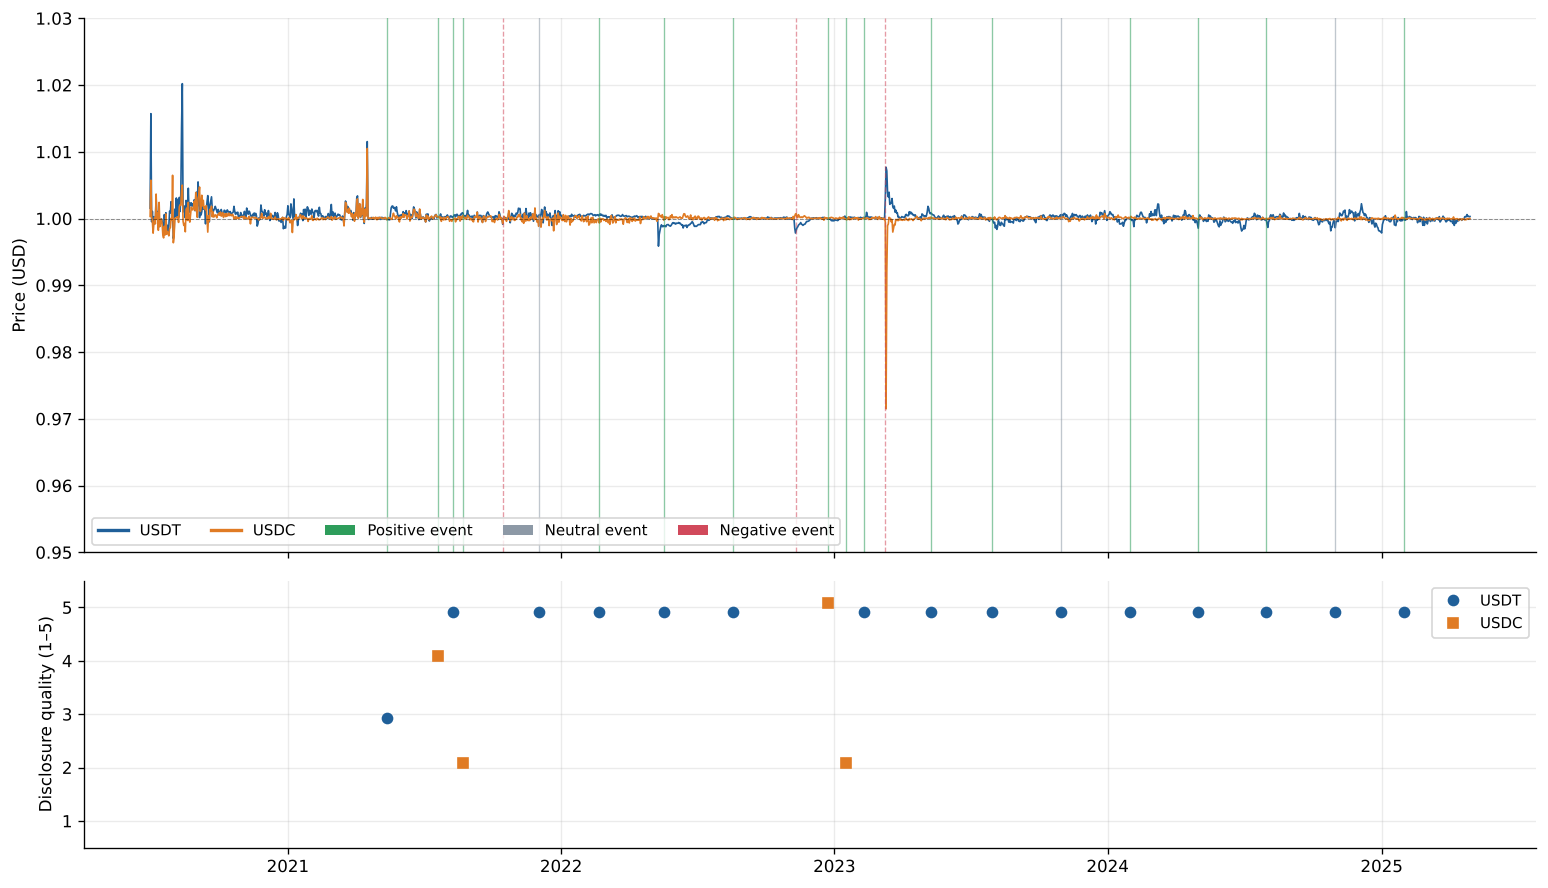

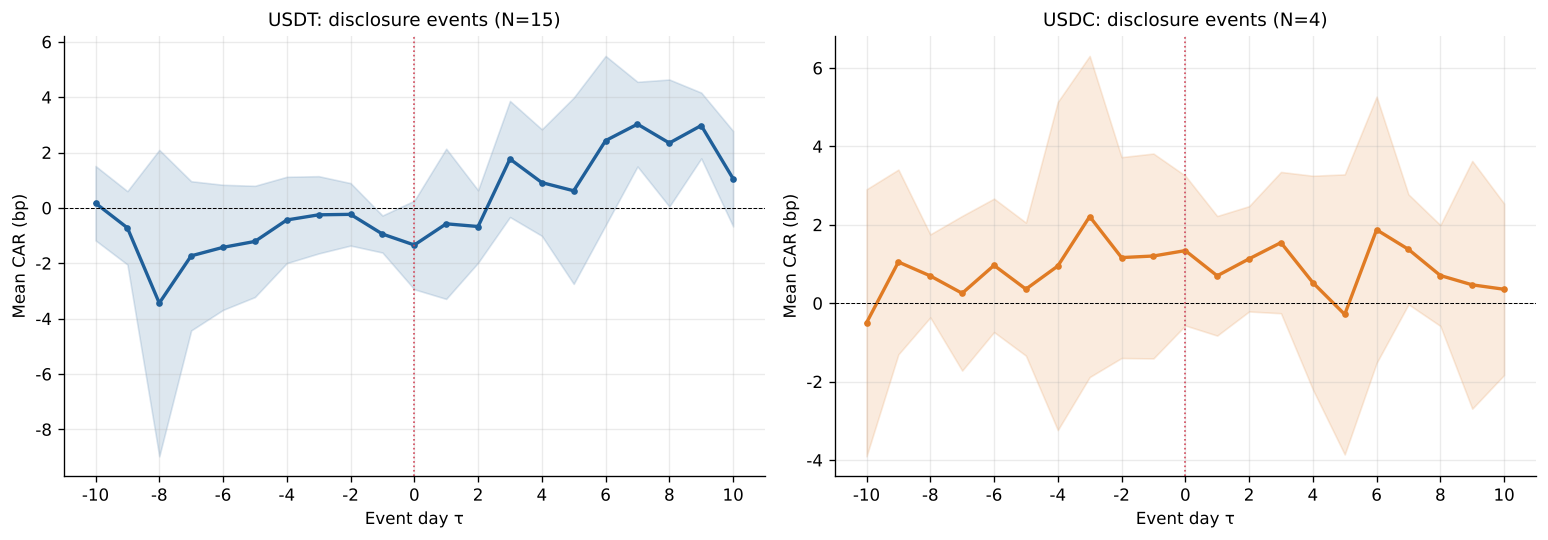

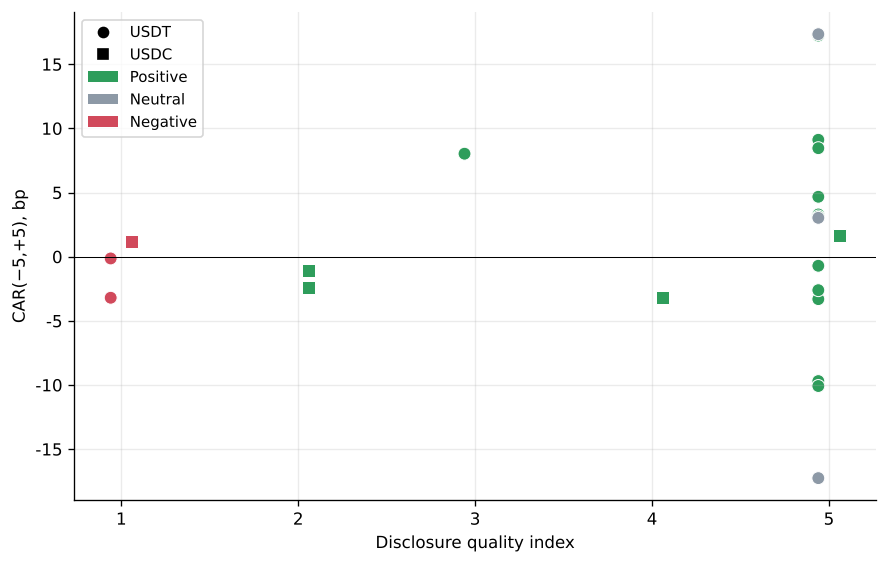

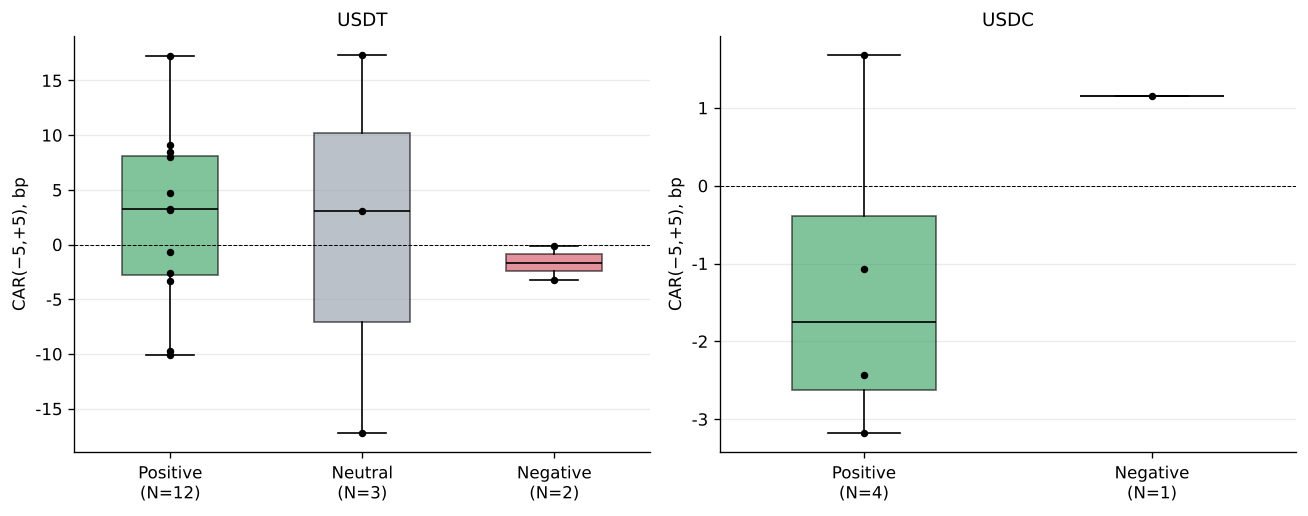

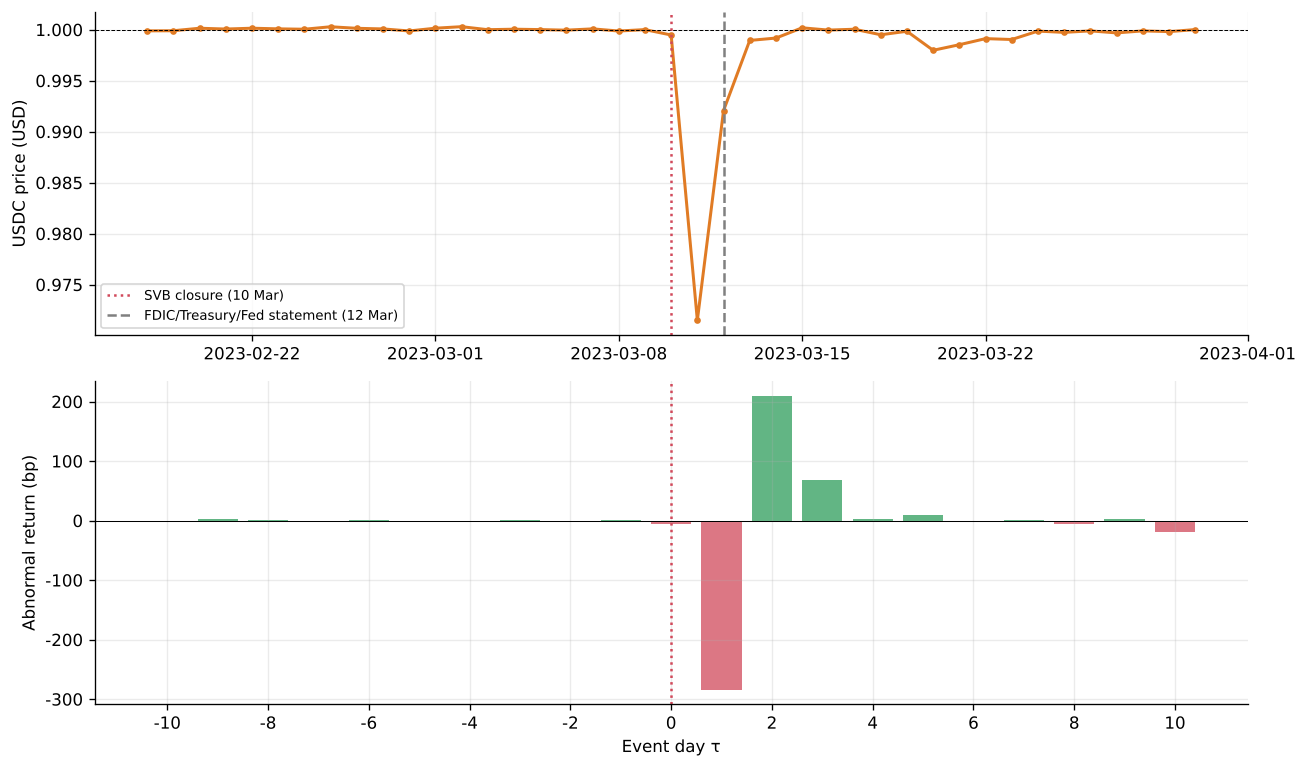

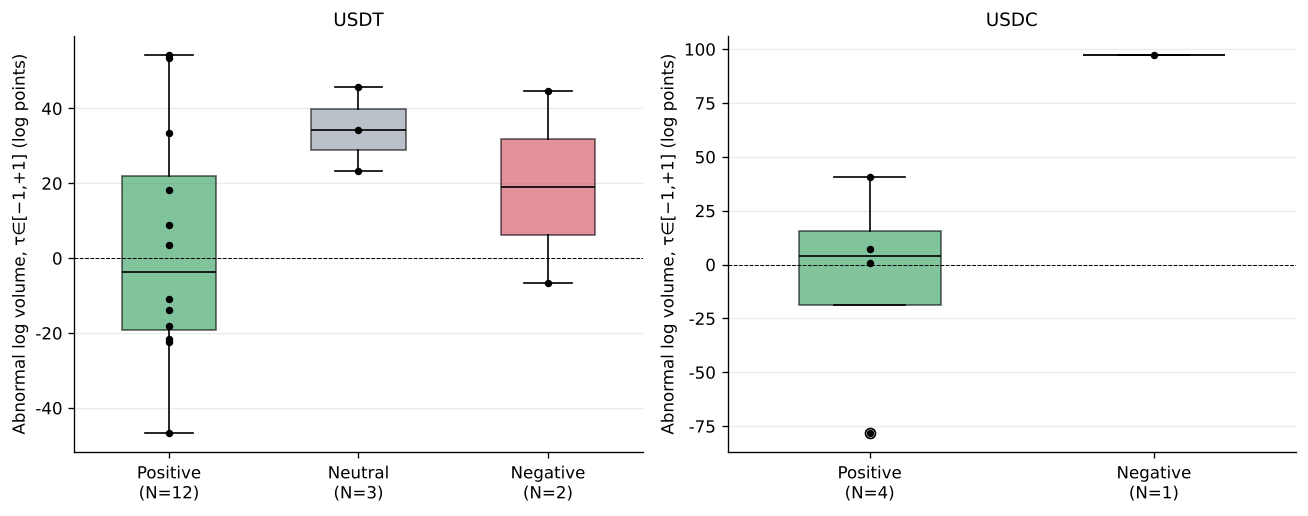

✅ Figures 1–6 saved


In [15]:
import matplotlib as _mpl
plt.rcParams.update({'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
_BOX_LABEL_KW = 'tick_labels' if tuple(int(x) for x in _mpl.__version__.split('.')[:2]) >= (3, 9) else 'labels'
palette = {'positive':'#2e9d5b','negative':'#d1495b','neutral':'#8d99a6'}
TYPE_EN = {'positive':'Positive','neutral':'Neutral','negative':'Negative'}
FIG = DIRS['figures']; DPI = 600

# Figure 1: prices, events, disclosure quality
fig, axes = plt.subplots(2,1,figsize=(13,7.5),gridspec_kw={'height_ratios':[2,1]},sharex=True)
ax = axes[0]
ax.plot(master['date'],master['p_usdt'],lw=1.0,color='#1f5f99',label='USDT')
ax.plot(master['date'],master['p_usdc'],lw=1.0,color='#e07b24',label='USDC')
ax.axhline(1.0,color='black',lw=0.6,ls='--',alpha=0.4)
for _,ev in events_df.iterrows():
    ax.axvline(ev['event_date'],color=palette[ev['event_type']],lw=0.8,alpha=0.55,
               ls='--' if ev['event_type']=='negative' else '-')
ax.legend(handles=[plt.Line2D([0],[0],color='#1f5f99',lw=2,label='USDT'),
                   plt.Line2D([0],[0],color='#e07b24',lw=2,label='USDC')]+
          [Patch(facecolor=palette[k],label=f'{TYPE_EN[k]} event') for k in ['positive','neutral','negative']],
          fontsize=9,ncol=5,loc='lower left')
ax.set_ylabel('Price (USD)'); ax.set_ylim(0.95,1.03); ax.grid(alpha=0.25)
ax2 = axes[1]
for coin,color in [('USDT','#1f5f99'),('USDC','#e07b24')]:
    s_ = events_df[(events_df['coin']==coin)&(events_df['event_type']!='negative')].sort_values('event_date')
    ax2.plot(s_['event_date'],s_['quality_score']+(0.08 if coin=='USDC' else -0.08),'o' if coin=='USDT' else 's',color=color,ms=6,label=coin,ls='none')
ax2.set_ylabel('Disclosure quality (1–5)'); ax2.set_ylim(0.5,5.5); ax2.set_yticks([1,2,3,4,5]); ax2.legend(fontsize=9); ax2.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure1_prices_events.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 2: average CAR path (excluding negative events)
fig,axes = plt.subplots(1,2,figsize=(13,4.6))
for ax,(cdf,coin,color) in zip(axes,[(car_usdt,'USDT','#1f5f99'),(car_usdc,'USDC','#e07b24')]):
    d_ = cdf[cdf['event_type']!='negative']
    s_ = tau_summary(d_, coin)
    ax.fill_between(s_['tau'],(s_['mean_CAR']-1.96*s_['se'])*1e4,(s_['mean_CAR']+1.96*s_['se'])*1e4,alpha=0.15,color=color)
    ax.plot(s_['tau'],s_['mean_CAR']*1e4,color=color,lw=2,marker='o',ms=3)
    ax.axhline(0,color='black',lw=0.6,ls='--'); ax.axvline(0,color='#d1495b',lw=1,ls=':')
    ax.set_title(f'{coin}: disclosure events (N={d_["event_date"].nunique()})',fontsize=11)
    ax.set_xlabel('Event day τ'); ax.set_ylabel('Mean CAR (bp)'); ax.set_xticks(range(-10,11,2)); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure2_car_path.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 3: quality vs CAR(-5,+5)
fig,ax = plt.subplots(figsize=(7.5,4.8))
for coin,mk in [('USDT','o'),('USDC','s')]:
    d_ = ev_all[ev_all['coin']==coin]
    ax.scatter(d_['quality_score']+(0.06 if coin=='USDC' else -0.06),d_[PRIMARY_WIN]*1e4,
               c=d_['event_type'].map(palette),marker=mk,s=60,edgecolors='white',lw=0.6,label=coin)
ax.axhline(0,color='black',lw=0.6)
ax.set_xlabel('Disclosure quality index'); ax.set_ylabel('CAR(−5,+5), bp'); ax.set_xticks([1,2,3,4,5])
ax.legend(handles=[plt.Line2D([0],[0],marker='o',ls='none',color='black',label='USDT'),plt.Line2D([0],[0],marker='s',ls='none',color='black',label='USDC')]+
          [Patch(facecolor=palette[k],label=TYPE_EN[k]) for k in ['positive','neutral','negative']],fontsize=9)
ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure3_quality_car.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 4: CAR(-5,+5) by event type
fig,axes = plt.subplots(1,2,figsize=(11,4.4))
for ax,coin in zip(axes,['USDT','USDC']):
    d_ = ev_all[ev_all['coin']==coin]
    order = [t for t in ['positive','neutral','negative'] if t in d_['event_type'].values]
    data = [d_[d_['event_type']==t][PRIMARY_WIN].values*1e4 for t in order]
    bp_ = ax.boxplot(data,**{_BOX_LABEL_KW:[f'{TYPE_EN[t]}\n(N={len(x)})' for t,x in zip(order,data)]},
                     patch_artist=True,widths=0.5,medianprops=dict(color='black'))
    for patch,t in zip(bp_['boxes'],order): patch.set(facecolor=palette[t],alpha=0.6)
    for k,(t,x) in enumerate(zip(order,data)):
        ax.scatter(np.full(len(x),k+1),x,color='black',s=12,zorder=3)
    ax.axhline(0,color='black',lw=0.6,ls='--'); ax.set_title(coin,fontsize=11); ax.set_ylabel('CAR(−5,+5), bp'); ax.grid(alpha=0.25,axis='y')
plt.tight_layout(); plt.savefig(f"{FIG}/Figure4_car_by_type.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 5: SVB case
svb = pd.Timestamp('2023-03-10')
w5  = master[(master['date']>=svb-pd.Timedelta('20d'))&(master['date']<=svb+pd.Timedelta('20d'))]
fig,(a1,a2) = plt.subplots(2,1,figsize=(11,6.5))
a1.plot(w5['date'],w5['p_usdc'],color='#e07b24',lw=1.8,marker='o',ms=3)
a1.axhline(1.0,color='black',lw=0.6,ls='--'); a1.axvline(svb,color='#d1495b',ls=':',label='SVB closure (10 Mar)')
a1.axvline(pd.Timestamp('2023-03-12'),color='gray',ls='--',label='FDIC/Treasury/Fed statement (12 Mar)')
a1.set_ylabel('USDC price (USD)'); a1.legend(fontsize=8); a1.grid(alpha=0.25)
sc = car_usdc[car_usdc['event_date']==svb].sort_values('tau')
a2.bar(sc['tau'],sc['AR']*1e4,color=np.where(sc['AR']<0,'#d1495b','#2e9d5b'),alpha=0.75)
a2.axhline(0,color='black',lw=0.6); a2.axvline(0,color='#d1495b',ls=':')
a2.set_xlabel('Event day τ'); a2.set_ylabel('Abnormal return (bp)'); a2.set_xticks(range(-10,11,2)); a2.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(f"{FIG}/Figure5_svb.png",dpi=DPI,bbox_inches='tight'); plt.show()

# Figure 6: abnormal trading volume by event type
av_ = pd.read_csv(f"{DIRS['results']}/abnormal_volume.csv")
fig,axes = plt.subplots(1,2,figsize=(11,4.4))
for ax,coin in zip(axes,['USDT','USDC']):
    d_ = av_[av_['coin']==coin]
    order = [t for t in ['positive','neutral','negative'] if t in d_['event_type'].values]
    data = [d_[d_['event_type']==t]['AV_-1_1'].values for t in order]
    bp_ = ax.boxplot(data,**{_BOX_LABEL_KW:[f'{TYPE_EN[t]}\n(N={len(x)})' for t,x in zip(order,data)]},
                     patch_artist=True,widths=0.5,medianprops=dict(color='black'))
    for patch,t in zip(bp_['boxes'],order): patch.set(facecolor=palette[t],alpha=0.6)
    for k,x in enumerate(data): ax.scatter(np.full(len(x),k+1),x,color='black',s=12,zorder=3)
    ax.axhline(0,color='black',lw=0.6,ls='--'); ax.set_title(coin,fontsize=11)
    ax.set_ylabel('Abnormal log volume, τ∈[−1,+1] (log points)'); ax.grid(alpha=0.25,axis='y')
plt.tight_layout(); plt.savefig(f"{FIG}/Figure6_volume.png",dpi=DPI,bbox_inches='tight'); plt.show()
print('✅ Figures 1–6 saved')


---
## STEP 13 | 테이블 & 최종 요약

> Table 2 (이벤트별 CAR) 생성. H1·H2·H3 결과 집약 출력.


In [16]:
# Table 2
t2 = ev_all[['coin','event_date','event_type','quality_score',
              'CAR_-1_1','CAR_-3_3','CAR_-5_5']].copy()
t2['event_date'] = t2['event_date'].dt.strftime('%Y-%m-%d')
for c in ['CAR_-1_1','CAR_-3_3','CAR_-5_5']:
    t2[c] = (t2[c] * 10000).round(3)
t2.columns = ['코인','공시일','유형','품질지수',
               'CAR(-1,+1)bp','CAR(-3,+3)bp','CAR(-5,+5)bp']
t2.to_csv(f"{DIRS['tables']}/Table2_event_CAR.csv",
          index=False, encoding='utf-8-sig')
print(f'Table 2: {len(t2)}건  ✅')

print('\n'+'='*70)
print('📋 최종 분석 결과 요약 (v9: 공개일 기준 이벤트)')
print('='*70)
print(f'  기간: {master.date.min().date()} ~ {master.date.max().date()} ({len(master)}일)')
print(f'  이벤트: USDT {len(ev_usdt)}건 / USDC {len(ev_usdc)}건 = {len(ev_all)}건')
print(f'  주 창: {PRIMARY_WIN}')
print()

h1k = pd.read_csv(f"{DIRS['results']}/H1_results.csv")
print('[H1]:')
for _,r in h1k[h1k['window']==PRIMARY_WIN].iterrows():
    sig = ('***' if r['p']<0.01 else '**' if r['p']<0.05
           else '*' if r['p']<0.1 else 'n.s.')
    cnfl = '  ⚠ Boot·t 불일치' if r.get('conflict',False) else ''
    print(f'  {r["coin"]:4s}  mean={r["mean_bp"]:+8.3f}bp  '
          f't={r["t"]:6.3f}  p={r["p"]:.4f} {sig}  '
          f'Boot95%=[{r["boot_lo_bp"]:+.3f},{r["boot_hi_bp"]:+.3f}]{cnfl}')

h2k = pd.read_csv(f"{DIRS['results']}/H2_regression.csv")
pw  = h2k[(h2k['var']=='quality_score')&(h2k['window']==PRIMARY_WIN)].iloc[0]
dg  = pd.read_csv(f"{DIRS['results']}/H2_residual_diagnostics.csv")
dw_row = dg[dg['window']==PRIMARY_WIN].iloc[0]
adj = dw_row['AdjR2']
adj_note = '  ⚠ 음수' if adj < 0 else ''
print(f'\n[H2] {PRIMARY_WIN}: '
      f'coef={pw.coef_bp:.4f}bp  p={pw.p:.4f}  '
      f'R²={dw_row["R2"]:.4f}  Adj-R²={adj:.4f}{adj_note}  '
      f'VIF_max={dw_row["VIF_max"]:.3f}  SE={pw.se_type}  WCR boot p={pw.p_wcr_boot:.4f}')

h3k = pd.read_csv(f"{DIRS['results']}/H3_results.csv")
print(f'\n[H3] {PRIMARY_WIN}:')
for _,r in h3k[h3k['window']==PRIMARY_WIN].iterrows():
    rn = r['ratio_note'] if pd.notna(r.get('ratio_note','')) else ''
    rv = f'{r["ratio"]:.2f}x ({rn})' if pd.notna(r['ratio']) else rn
    if r['test_feasible']:
        sig = ('***' if r['p_ttest']<0.01 else '**' if r['p_ttest']<0.05
               else '*' if r['p_ttest']<0.1 else 'n.s.')
        print(f'  {r["coin"]:4s}  긍정={r["pos_mean_bp"]:+8.3f}bp  '
              f'부정={r["neg_mean_bp"]:+8.3f}bp  비율={rv}  '
              f'p={r["p_ttest"]:.4f}{sig}  [{r["direction"]}]')
    else:
        print(f'  {r["coin"]:4s}  검정불가(N_neg={r["n_neg"]})  '
              f'부정={r["neg_mean_bp"]:+8.3f}bp  비율={rv}  [{r["direction"]}]')

print()



Table 2: 22건  ✅

📋 최종 분석 결과 요약 (v9: 공개일 기준 이벤트)
  기간: 2020-07-01 ~ 2025-04-29 (1764일)
  이벤트: USDT 17건 / USDC 5건 = 22건
  주 창: CAR_-5_5

[H1]:
  USDT  mean=  +1.606bp  t= 0.722  p=0.4807 n.s.  Boot95%=[-2.565,+5.940]
  USDC  mean=  -0.771bp  t=-0.804  p=0.4662 n.s.  Boot95%=[-2.460,+0.918]

[H2] CAR_-5_5: coef=-0.1333bp  p=0.9204  R²=0.0219  Adj-R²=-0.1411  ⚠ 음수  VIF_max=4.274  SE=Cluster(date, G=22)  WCR boot p=0.9497

[H3] CAR_-5_5:
  USDT  긍정=  +2.294bp  부정=  -1.668bp  비율=0.73x (H3 방향 일치)  p=0.1950n.s.  [음수 — H3 방향 일치]
  USDC  검정불가(N_neg=1)  부정=  +1.151bp  비율=0.92x (H3 방향 일치)  [N_neg=1: 방향 해석 불가(단일 사례)]



---
# STEP R. 리비전 분석 (FinTech fintech-4675558, Round 1 리뷰 대응)

위 STEP 1–11은 **심사받은 v9 원고의 수치를 그대로 재현**하며 수정하지 않았다. 아래 STEP R은 리뷰어 지적에 대응하는 **추가·수정 분석**이다.

| 셀 | 내용 | 리뷰어 |
|---|---|---|
| R00 | 데이터 자동 준비(Drive 연결, 유통량·BTC 거래량·SVB 시간별 가격 다운로드) | – |
| R0 | 공통 설정, 표본 구분(routine / stress), 데이터 파일 확인 | – |
| R1 | H1 재구성: disclosure-only 기본 + pooled 병기 (Table 4 수정) | R1-7, R2-3, R4-1 |
| R2 | 최소탐지효과(noncentral-t), 동등성 검정(TOST) | R1-8, R2-6, R4-7 |
| R3 | 페그 안정성 지표 + 비이벤트 placebo 백분위 | R1-2, R2-1, R4-2, R4-7, R3 |
| R4 | 스트레스 이벤트 개별 보고(표준화 CAR, 백분위) | R2-9, R4-7 |
| R5 | H2 재구성: 보고서 한정, 기준별 코딩, 레버리지, HC/자유도, wild bootstrap | R1-3, R2-4·5, R4-4·6 |
| R6 | Figure 2 수정: 이벤트 경로 bootstrap 신뢰대역(pointwise·simultaneous) | R1-5 |
| R7 | 거래량 수정: 기준기간 정제, 달력효과 표시, BTC 시장조정(파일 있을 때) | R2-10, R4-8 |
| R8 | 대안 벤치마크(교차 스테이블코인, 2요인, constant mean) | R2-7 |
| R9 | 후보 이벤트 선정 엔진(코인별 21일 규칙, MIN_OBS, 제외 사유 기록) | R1-1, R2-2, R4-1·3 |
| R10 | 유통량(발행·소각) 반응(파일 있을 때) | R2-14, R3 |
| R11 | SVB 시간별 경로(파일 있을 때) | R2-8, R1-6 |
| R01 | Circle 월간 attestation 공개일(감사인 서명일) 자동 수집 | R4-1, R1-1 |
| R3c | 일중 저가 기준 이탈, 비정상수익률 절댓값 합 | R4-2 |
| R10b | 유통량 집계 오류일 보정 강건성 | (방어) |
| R13 | 확장 표본·대안 표본 시나리오별 재분석 | R1-1, R2-2, R4-1·3 |
| R14 | 2차 코딩 일치도(κ) | R1-3, R2-4, R4-5 |
| R15 | 교수님 독립 코딩 시트 생성 | R1-3, R2-4, R4-5 |
| R16 | 경쟁 뉴스 달력, 오염 이벤트 제외 민감도 | R1-6, R2-12 |
| R12 | 본문용 이벤트 단위 결과표 + 소프트웨어 버전 | R4-10 |

---

In [17]:
# R00. 리비전 데이터 자동 준비 (Colab에서 "모두 실행"만 하면 됨)
#   ① Google Drive 연결(Colab일 때) ② 유통량·BTC 거래량·SVB 시간별 가격을 인터넷에서 받아 저장
#   ③ 새 폴더(FinTech_4675558_Revision_R1)의 event_candidates_v10.csv 를 찾아 사용
#   이미 파일이 있으면 다시 받지 않는다. 인터넷이 막힌 환경에서는 건너뛴다.
import os, sys, time, shutil, requests, glob
PROJECT_FOLDER = 'FinTech_4675558_Revision_R1'
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive as _gdrive
    _gdrive.mount('/content/drive', force_remount=True)       # 계정 선택 창에서 beingham@gmail.com 선택
    hits = glob.glob(f'/content/drive/MyDrive/{PROJECT_FOLDER}') or glob.glob(f'/content/drive/**/{PROJECT_FOLDER}', recursive=True)
    if not hits:
        top = sorted(os.listdir('/content/drive/MyDrive'))[:15] if os.path.exists('/content/drive/MyDrive') else []
        raise RuntimeError(
            f"\n\n❌ Google Drive에서 '{PROJECT_FOLDER}' 폴더를 찾지 못했습니다.\n"
            "   → 연결된 Drive가 beingham@gmail.com 계정이 아닐 가능성이 큽니다.\n"
            "   → 런타임 > 런타임 연결 해제 및 삭제 후 다시 실행하고, 계정 선택 창에서 beingham@gmail.com을 고르세요.\n"
            f"   현재 연결된 내 드라이브의 최상위 폴더(일부): {top}")
    PROJECT_DIR = hits[0]
    DRIVE_DIRS = [PROJECT_DIR, os.path.join(os.path.dirname(PROJECT_DIR), 'stablecoin_research')]
    print('✅ Drive 연결 확인:', PROJECT_DIR)
else:
    DRIVE_DIRS = []
SAVE_DIRS = [BASE] + [d for d in DRIVE_DIRS if os.path.exists(d)]

def _have(name):
    return next((os.path.join(d, name) for d in DRIVE_DIRS + [BASE, '.']
                 if os.path.exists(os.path.join(d, name)) and os.path.getsize(os.path.join(d, name)) > 100), None)

def _save(df, name, **kw):
    for d in SAVE_DIRS:
        try:
            df.to_csv(os.path.join(d, name), **kw)
        except Exception as e:
            print('  저장 실패', d, e)

START_R, END_R = str(master['date'].min().date()), str(master['date'].max().date())

if not _have('supply_daily.csv'):
    try:
        fr = []
        for sid, coin in [(1, 'usdt'), (2, 'usdc')]:
            js = requests.get(f'https://stablecoins.llama.fi/stablecoincharts/all?stablecoin={sid}', timeout=60).json()
            df = pd.DataFrame(js)
            df['date'] = pd.to_datetime(df['date'].astype(int), unit='s').dt.normalize()
            df[f'supply_{coin}'] = df['totalCirculating'].apply(lambda x: x.get('peggedUSD'))
            fr.append(df[['date', f'supply_{coin}']].set_index('date'))
        sup = pd.concat(fr, axis=1).loc[START_R:END_R]
        if len(sup) == 0:
            raise ValueError('빈 데이터')
        _save(sup, 'supply_daily.csv'); print('✅ supply_daily.csv', sup.shape)
    except Exception as e:
        print('⚠ 유통량 수집 실패:', e)

if not _have('btc_volume_daily.csv'):
    try:
        bt = yf.download('BTC-USD', start=START_R, end=str((master['date'].max() + pd.Timedelta(days=1)).date()),
                         progress=False, auto_adjust=False)
        bt.columns = [c[0] if isinstance(c, tuple) else c for c in bt.columns]
        bt = bt[['Close', 'Volume']].rename(columns={'Close': 'p_btc', 'Volume': 'v_btc'}); bt.index.name = 'date'
        if len(bt) == 0:
            raise ValueError('빈 데이터 (Yahoo Finance 응답 없음)')
        _save(bt, 'btc_volume_daily.csv'); print('✅ btc_volume_daily.csv', bt.shape)
    except Exception as e:
        print('⚠ BTC 거래량 수집 실패:', e)

if not _have('usdc_hourly_svb.csv'):
    try:
        out = []; t0_ = int(pd.Timestamp('2023-03-03', tz='UTC').timestamp() * 1000)
        t1_ = int(pd.Timestamp('2023-03-21', tz='UTC').timestamp() * 1000)
        while t0_ < t1_:
            rows_ = requests.get('https://data-api.binance.vision/api/v3/klines',
                                 params=dict(symbol='USDCUSDT', interval='1h', startTime=t0_, endTime=t1_, limit=1000),
                                 timeout=60).json()
            if not rows_ or not isinstance(rows_, list):
                break
            out += rows_; t0_ = rows_[-1][0] + 3_600_000; time.sleep(0.2)
        hr = pd.DataFrame(out, columns=['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time',
                                        'qav', 'trades', 'tbb', 'tbq', 'ignore'])
        hr['time_utc'] = pd.to_datetime(hr['open_time'], unit='ms', utc=True)
        hr = hr[['time_utc', 'open', 'high', 'low', 'close', 'volume', 'trades']].astype(
            {'open': float, 'high': float, 'low': float, 'close': float, 'volume': float})
        if len(hr):
            _save(hr, 'usdc_hourly_svb.csv', index=False); print('✅ usdc_hourly_svb.csv', hr.shape)
    except Exception as e:
        print('⚠ SVB 시간별 가격 수집 실패(선택 항목):', e)


if not _have('ohlc_daily.csv'):
    try:
        fr = []
        for tk, k in [('USDT-USD', 'usdt'), ('USDC-USD', 'usdc')]:
            o = yf.download(tk, start=START_R, end=str((master['date'].max() + pd.Timedelta(days=1)).date()),
                            progress=False, auto_adjust=False)
            o.columns = [c[0] if isinstance(c, tuple) else c for c in o.columns]
            fr.append(o[['Low', 'High']].rename(columns={'Low': f'low_{k}', 'High': f'high_{k}'}))
        oh = pd.concat(fr, axis=1); oh.index.name = 'date'
        if len(oh) == 0:
            raise ValueError('빈 데이터')
        _save(oh, 'ohlc_daily.csv'); print('✅ ohlc_daily.csv', oh.shape)
    except Exception as e:
        print('⚠ 일별 고가·저가 수집 실패:', e)

for name in ['supply_daily.csv', 'btc_volume_daily.csv', 'usdc_hourly_svb.csv', 'ohlc_daily.csv',
             'event_candidates_v10.csv', 'circle_attestations_v2.csv', 'coding_second.csv']:
    print(f'  {name:28s} →', _have(name) or '없음')

⚠ SVB 시간별 가격 수집 실패(선택 항목): HTTPSConnectionPool(host='data-api.binance.vision', port=443): Max retries exceeded with url: /api/v3/klines?symbol=USDCUSDT&interval=1h&startTime=1677801600000&endTime=1679356800000&limit=1000 (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


Cookie fetch from fc.yahoo.com failed (ConnectionError), continuing without it


Cookie/crumb fetch failed (ConnectionError), continuing without crumb


Failed to get ticker 'USDT-USD' reason: Failed to perform, curl: (7) CONNECT tunnel failed, response 403. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.


Cookie/crumb fetch failed (ConnectionError), continuing without crumb



1 Failed download:


... (3 outputs left out)

Cookie/crumb fetch failed (ConnectionError), continuing without crumb



1 Failed download:


['USDC-USD']: ConnectionError('Failed to perform, curl: (7) CONNECT tunnel failed, response 403. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.')


⚠ 일별 고가·저가 수집 실패: 빈 데이터
  supply_daily.csv             → ./stablecoin_research/supply_daily.csv
  btc_volume_daily.csv         → ./stablecoin_research/btc_volume_daily.csv
  usdc_hourly_svb.csv          → 없음
  ohlc_daily.csv               → 없음
  event_candidates_v10.csv     → ./stablecoin_research/event_candidates_v10.csv
  circle_attestations_v2.csv   → 없음
  coding_second.csv            → 없음


---

In [18]:
# R0. 공통 설정
import os, sys, platform
from scipy.stats import nct, t as tdist, wilcoxon
# 결과 저장 위치: Drive가 연결돼 있으면 Drive 폴더(세션이 끝나도 남음), 아니면 로컬 임시 폴더
REV = os.path.join(DRIVE_DIRS[0], 'revision_outputs') if DRIVE_DIRS else f"{BASE}/revision"
os.makedirs(REV, exist_ok=True)
print('결과 저장 위치:', REV)
R_SEED = 20261107
rng = np.random.default_rng(R_SEED)

STRESS_TYPES = {'negative'}
ev_all['routine'] = (~ev_all['event_type'].isin(STRESS_TYPES)).astype(int)
# 준비금 '보고서'가 아닌 공시 (기준 ②–④를 구조적으로 충족할 수 없음, R4-4)
NON_REPORT = {('USDC', '2021-08-23'): 'reserve-policy announcement',
              ('USDC', '2023-01-17'): 'auditor appointment'}
ev_all['is_report'] = [int(r == 1 and (c, d.strftime('%Y-%m-%d')) not in NON_REPORT)
                       for r, c, d in zip(ev_all['routine'], ev_all['coin'], ev_all['event_date'])]

# 시장 전체 스트레스 구간 (기준기간 정제와 placebo 제외에 사용; 날짜는 대표 공개일)
def pctile(ref, v):
    ref = np.asarray(ref, float); ref = ref[np.isfinite(ref)]
    return ((ref < v).mean() + 0.5 * (ref == v).mean()) * 100   # mid-rank: 동점 처리

STRESS_DATES = pd.to_datetime(['2021-10-15', '2022-05-09', '2022-05-12', '2022-11-08',
                               '2022-11-11', '2023-03-10'])

def t0_of(date):
    return int(master.index[master['date'] == pd.Timestamp(date)][0])

def path(coin, date):
    cdf = car_usdt if coin == 'USDT' else car_usdc
    return cdf[cdf['event_date'] == pd.Timestamp(date)].set_index('tau')['AR']

OPTIONAL = {'supply': 'supply_daily.csv', 'btcvol': 'btc_volume_daily.csv', 'hourly': 'usdc_hourly_svb.csv',
            'cands': 'event_candidates_v10.csv', 'ohlc': 'ohlc_daily.csv', 'circle': 'circle_attestations_v2.csv',
            'coding2': 'coding_second.csv'}
HAVE = {k: _have(v) for k, v in OPTIONAL.items()}
print('표본:', ev_all.groupby(['coin', 'routine']).size().to_dict())
print('보고서(H2 대상):', ev_all.groupby('coin')['is_report'].sum().to_dict())
print('선택 데이터 파일:', {k: (v or '없음') for k, v in HAVE.items()})

결과 저장 위치: ./stablecoin_research/revision
표본: {('USDC', 0): 1, ('USDC', 1): 4, ('USDT', 0): 2, ('USDT', 1): 15}
보고서(H2 대상): {'USDC': 2, 'USDT': 15}
선택 데이터 파일: {'supply': './stablecoin_research/supply_daily.csv', 'btcvol': './stablecoin_research/btc_volume_daily.csv', 'hourly': '없음', 'cands': './stablecoin_research/event_candidates_v10.csv', 'ohlc': '없음', 'circle': '없음', 'coding2': '없음'}


---

In [19]:
# R01. Circle USDC 월간 attestation 공개일 수집 (R4-1, R1-1)
#   각 보고서 PDF의 '독립회계사 보고서 서명일'을 공개일의 대용치로 쓴다
#   (검증 예: 2021년 3월분 서명일 2021-05-24, Circle 블로그 게시 2021-05-25).
#   PDF 목록: ① 인터넷 아카이브(Wayback CDX)에 저장된 Circle 보고서 URL ② Circle 투명성 페이지의 링크.
#   결과: circle_attestations.csv (Drive에 저장, 다시 실행하면 건너뜀)
import re, io, json
from datetime import datetime
MONTHS = 'January|February|March|April|May|June|July|August|September|October|November|December'
DATE_RE = re.compile(rf'({MONTHS})\s+(\d{{1,2}}),\s*(\d{{4}})')
CITY_RE = re.compile(rf'(New York|Philadelphia|Boston|Chicago|San Francisco|Washington|Charlotte|Dallas|Los Angeles)[^\n]{{0,30}}[\s,]*\n?\s*(({MONTHS})\s+\d{{1,2}},\s*\d{{4}})')

def _d(m):
    return datetime.strptime(f'{m[0]} {m[1]} {m[2]}', '%B %d %Y')

def parse_attestation(text):
    """as-of 날짜와 서명일 추출. method: city(도시+날짜 패턴) / window(as-of 이후 120일 내 마지막 날짜) / none"""
    t = text.replace('\u2019', "'")
    asof = None
    m = re.search(rf'as of\s+(({MONTHS})\s+\d{{1,2}},\s*\d{{4}})(?:,?\s+and\s+(({MONTHS})\s+\d{{1,2}},\s*\d{{4}}))?', t)
    if m:
        asof = datetime.strptime(re.sub(r'\s+', ' ', (m.group(3) or m.group(1)).replace(',', '')), '%B %d %Y')
        if asof.day < 25:   # Deloitte 보고서: 월중 임의일 + 월말 두 기준일 → 같은 달 월말 날짜가 본문에 있으면 그것을 기준일로
            same = [_d(x) for x in DATE_RE.findall(t)]
            same = [x for x in same if x.year == asof.year and x.month == asof.month and x.day >= 25]
            if same:
                asof = max(same)
    sign, method = None, 'none'
    for cm in CITY_RE.finditer(t):
        cand = datetime.strptime(re.sub(r'\s+', ' ', cm.group(2).replace(',', '')), '%B %d %Y')
        if asof is None or 0 < (cand - asof).days <= 150:
            sign, method = cand, 'city'
    if sign is None and asof is not None:
        cands = [_d(x) for x in DATE_RE.findall(t)]
        cands = [c for c in cands if 0 < (c - asof).days <= 150]
        if cands:
            sign, method = max(cands), 'window'
    auditor = 'Deloitte' if 'Deloitte' in t else ('Grant Thornton' if 'Grant Thornton' in t else '')
    return asof, sign, method, auditor

CIRCLE_FILE = 'circle_attestations_v2.csv'   # v2: 전체 페이지 + PDF 생성일 대체
CIRCLE_OUT = _have(CIRCLE_FILE)
if CIRCLE_OUT:
    print('이미 수집됨:', CIRCLE_OUT)
else:
    try:
        !pip -q install pypdf
        from pypdf import PdfReader
        import logging; logging.getLogger('pypdf').setLevel(logging.ERROR)
        urls = set()
        for prefix in ['6778953.fs1.hubspotusercontent-na1.net/hubfs/6778953/USDCAttestationReports/',
                       'f.hubspotusercontent00.net/hubfs/6778953/USDCAttestationReports/',
                       '6778953.hs-sites.com/hubfs/USDCAttestationReports/']:
            try:
                r = requests.get('https://web.archive.org/cdx/search/cdx',
                                 params=dict(url=prefix, matchType='prefix', output='json', collapse='urlkey',
                                             filter='statuscode:200', fl='original,timestamp'), timeout=120)
                rows_ = r.json()[1:] if r.ok and r.text.strip() else []
                for orig, ts in rows_:
                    if orig.lower().endswith('.pdf'):
                        urls.add((orig, ts))
            except Exception as e:
                print('  CDX 실패', prefix, e)
        for page in ['https://www.circle.com/transparency', 'https://www.circle.com/en/transparency']:
            try:
                h = requests.get(page, timeout=60, headers={'User-Agent': 'Mozilla/5.0'}).text
                for u in re.findall(r'https://[^"\']+USDCAttestationReports[^"\']+\.pdf', h):
                    urls.add((u, ''))
            except Exception:
                pass
        print('PDF 후보 URL:', len(urls))
        recs, seen = [], set()
        for orig, ts in sorted(urls):
            key = requests.utils.unquote(orig).split('/')[-1].lower()
            if key in seen:
                continue
            content = None
            for u in [orig if orig.startswith('http') else 'https://' + orig] + \
                     ([f'https://web.archive.org/web/{ts}id_/{orig}'] if ts else []):
                try:
                    rr = requests.get(u, timeout=60, headers={'User-Agent': 'Mozilla/5.0'})
                    if rr.ok and rr.content[:4] == b'%PDF':
                        content = rr.content; break
                except Exception:
                    pass
            if content is None:
                continue
            try:
                rd = PdfReader(io.BytesIO(content))
                txt = '\n'.join((p.extract_text() or '') for p in rd.pages)
                meta = rd.metadata or {}
                cdt = getattr(meta, 'creation_date', None)
            except Exception:
                continue
            asof, sign, method, aud = parse_attestation(txt)
            if asof is None:
                continue
            seen.add(key)
            recs.append(dict(as_of=asof.date(), sign_text=sign.date() if sign else None, text_method=method,
                             pdf_created=cdt.date() if cdt else None, auditor=aud, url=orig))
        CIR = (pd.DataFrame(recs).sort_values('as_of').drop_duplicates('as_of', keep='last'))
        for c in ['as_of', 'sign_text', 'pdf_created']:
            CIR[c] = pd.to_datetime(CIR[c])
        # 서명일 결정: ① 본문 '도시+날짜'(city) ② PDF 생성일(본문 추정일과 3일 이내면 'pdf_meta+text') ③ 본문 추정일(window)
        meta_ok = CIR['pdf_created'].notna() & (CIR['pdf_created'] - CIR['as_of']).dt.days.between(1, 150)
        gap = (CIR['pdf_created'] - CIR['sign_text']).dt.days.abs()
        CIR['sign_date'] = np.where(CIR['text_method'] == 'city', CIR['sign_text'],
                                    np.where(meta_ok, CIR['pdf_created'], CIR['sign_text']))
        CIR['method'] = np.where(CIR['text_method'] == 'city', 'city',
                                 np.where(meta_ok, np.where(gap <= 3, 'pdf_meta+text', 'pdf_meta'), CIR['text_method']))
        CIR['sign_date'] = pd.to_datetime(CIR['sign_date'])
        gt = CIR[CIR['text_method'] == 'city'].dropna(subset=['pdf_created'])
        if len(gt):
            agree = ((gt['pdf_created'] - gt['sign_text']).dt.days.abs() <= 1).mean()
            print(f'검증: Grant Thornton 시기 PDF 생성일이 본문 서명일과 ±1일 이내 일치 비율 = {agree:.0%} (N={len(gt)})')
        _save(CIR, CIRCLE_FILE, index=False)
        print(f'✅ {CIRCLE_FILE}: {len(CIR)}건, 서명일 결정 방법별:', CIR['method'].value_counts().to_dict())
    except Exception as e:
        print('⚠ Circle attestation 수집 실패:', e)

HAVE['circle'] = _have(CIRCLE_FILE)
if HAVE['circle']:
    CIR = pd.read_csv(HAVE['circle'], parse_dates=['as_of', 'sign_date'])
    CIR = CIR[[c for c in ['as_of', 'sign_date', 'method', 'sign_text', 'pdf_created', 'auditor'] if c in CIR]]
    CIR['lag_days'] = (CIR['sign_date'] - CIR['as_of']).dt.days
    print(CIR[(CIR['as_of'] >= '2021-06-01') & (CIR['as_of'] <= '2025-03-31')].to_string(index=False))
    print('기준일→서명일 지연(일):', CIR['lag_days'].describe().round(1).to_dict())

  CDX 실패 6778953.fs1.hubspotusercontent-na1.net/hubfs/6778953/USDCAttestationReports/ HTTPSConnectionPool(host='web.archive.org', port=443): Max retries exceeded with url: /cdx/search/cdx?url=6778953.fs1.hubspotusercontent-na1.net%2Fhubfs%2F6778953%2FUSDCAttestationReports%2F&matchType=prefix&output=json&collapse=urlkey&filter=statuscode%3A200&fl=original%2Ctimestamp (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


  CDX 실패 f.hubspotusercontent00.net/hubfs/6778953/USDCAttestationReports/ HTTPSConnectionPool(host='web.archive.org', port=443): Max retries exceeded with url: /cdx/search/cdx?url=f.hubspotusercontent00.net%2Fhubfs%2F6778953%2FUSDCAttestationReports%2F&matchType=prefix&output=json&collapse=urlkey&filter=statuscode%3A200&fl=original%2Ctimestamp (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


  CDX 실패 6778953.hs-sites.com/hubfs/USDCAttestationReports/ HTTPSConnectionPool(host='web.archive.org', port=443): Max retries exceeded with url: /cdx/search/cdx?url=6778953.hs-sites.com%2Fhubfs%2FUSDCAttestationReports%2F&matchType=prefix&output=json&collapse=urlkey&filter=statuscode%3A200&fl=original%2Ctimestamp (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


PDF 후보 URL: 0
⚠ Circle attestation 수집 실패: 'as_of'


---

In [20]:
# R1. H1 재구성 — disclosure-only를 기본 표본으로 (Table 4 수정)
def describe(x):
    x = np.asarray(x, float); n = len(x)
    if n < 2:
        return dict(N=n, mean_bp=x.mean() if n else np.nan, median_bp=np.nan, sd_bp=np.nan,
                    t=np.nan, p_t=np.nan, p_wilcoxon=np.nan, ci_lo=np.nan, ci_hi=np.nan)
    tt = ttest_1samp(x, 0)
    se = x.std(ddof=1) / np.sqrt(n); c = tdist.ppf(0.975, n - 1)
    try:
        pw = wilcoxon(x).pvalue if n >= 5 else np.nan
    except ValueError:
        pw = np.nan
    return dict(N=n, mean_bp=x.mean(), median_bp=np.median(x), sd_bp=x.std(ddof=1),
                t=tt.statistic, p_t=tt.pvalue, p_wilcoxon=pw,
                ci_lo=x.mean() - c * se, ci_hi=x.mean() + c * se)

rows = []
for coin in ['USDT', 'USDC']:
    for sample, mask in [('routine (baseline)', ev_all['routine'] == 1),
                         ('pooled (v9 Table 4)', ev_all['routine'] >= 0),
                         ('stress only', ev_all['routine'] == 0)]:
        d = ev_all[(ev_all['coin'] == coin) & mask]
        for w in ALL_WINS + ['CAR_-10_10']:
            rows.append(dict(coin=coin, sample=sample, window=w, **describe(d[w] * 1e4)))
H1r = pd.DataFrame(rows)
H1r.to_csv(f'{REV}/R1_H1_routine_vs_pooled.csv', index=False)
show = H1r[H1r['sample'] != 'stress only'].copy()
print(show.round(3).to_string(index=False))
print('\n주 분석창 routine-only:',
      {c: (round(r.mean_bp, 2), round(r.p_t, 3), int(r.N)) for c, r in
       H1r[(H1r['sample'] == 'routine (baseline)') & (H1r['window'] == PRIMARY_WIN)].set_index('coin').iterrows()})

coin              sample     window  N  mean_bp  median_bp   sd_bp      t   p_t  p_wilcoxon    ci_lo   ci_hi
USDT  routine (baseline)   CAR_-1_1 15   -0.342     -0.663   3.201 -0.413 0.686       0.639   -2.114   1.431
USDT  routine (baseline)   CAR_-3_3 15    2.202      1.151   6.094  1.400 0.183       0.107   -1.172   5.577
USDT  routine (baseline)   CAR_-5_5 15    2.043      3.133   9.701  0.816 0.428       0.454   -3.329   7.415
USDT  routine (baseline) CAR_-10_10 15    1.054     -0.485   9.066  0.450 0.659       0.978   -3.966   6.075
USDT pooled (v9 Table 4)   CAR_-1_1 17   -0.405     -0.663   3.007 -0.556 0.586       0.459   -1.951   1.141
USDT pooled (v9 Table 4)   CAR_-3_3 17    1.243      0.719   6.312  0.812 0.429       0.353   -2.002   4.488
USDT pooled (v9 Table 4)   CAR_-5_5 17    1.606      3.029   9.174  0.722 0.481       0.548   -3.110   6.323
USDT pooled (v9 Table 4) CAR_-10_10 17    0.573     -1.099   8.589  0.275 0.787       0.818   -3.843   4.989
USDC  routine (base

---

In [21]:
# R2. 최소탐지효과(noncentral-t)와 동등성 검정(TOST)
EQ_MARGINS_BP = [5.0, 10.0]   # 경제적 동등성 마진(±bp). 근거는 본문에 서술 (예: 주요 거래소 스프레드·평상시 페그 변동)

def power_t(delta, sd, n, alpha=0.05):
    df = n - 1; ncp = delta / (sd / np.sqrt(n)); c = tdist.ppf(1 - alpha / 2, df)
    return 1 - nct.cdf(c, df, ncp) + nct.cdf(-c, df, ncp)

def mde_t(sd, n, power=0.8, alpha=0.05):
    lo, hi = 1e-9, 50 * sd
    for _ in range(200):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if power_t(mid, sd, n, alpha) < power else (lo, mid)
    return hi

def tost(x, m):
    p_lo = ttest_1samp(x, -m, alternative='greater').pvalue
    p_hi = ttest_1samp(x, m, alternative='less').pvalue
    return max(p_lo, p_hi)

rows = []
for coin in ['USDT', 'USDC']:
    d = ev_all[(ev_all['coin'] == coin) & (ev_all['routine'] == 1)]
    for w in ALL_WINS:
        x = (d[w] * 1e4).values; n = len(x); sd = x.std(ddof=1)
        # 분산 추정 불확실성: SD의 95% 상한(카이제곱)으로도 MDE 계산
        sd_hi = sd * np.sqrt((n - 1) / stats.chi2.ppf(0.025, n - 1))
        se = sd / np.sqrt(n); c90 = tdist.ppf(0.95, n - 1)
        r = dict(coin=coin, window=w, N=n, mean_bp=x.mean(), sd_bp=sd,
                 MDE80_t=mde_t(sd, n, .8), MDE90_t=mde_t(sd, n, .9),
                 MDE80_normal_v9=(1.96 + 0.8416) * se, MDE80_t_sdUpper=mde_t(sd_hi, n, .8),
                 CI90_lo=x.mean() - c90 * se, CI90_hi=x.mean() + c90 * se)
        for m in EQ_MARGINS_BP:
            r[f'TOST_p_±{m:g}bp'] = tost(x, m)
        rows.append(r)
MDE = pd.DataFrame(rows); MDE.to_csv(f'{REV}/R2_MDE_TOST.csv', index=False)
print(MDE.round(3).to_string(index=False))
print('\n해석: TOST p<0.05 → 평균 효과가 ±마진 안에 있다(경제적으로 무시할 만한 크기와 동등)는 결론을 지지. p≥0.05 → 그 마진으로는 판단 불가.')

coin   window  N  mean_bp  sd_bp  MDE80_t  MDE90_t  MDE80_normal_v9  MDE80_t_sdUpper  CI90_lo  CI90_hi  TOST_p_±5bp  TOST_p_±10bp
USDT CAR_-1_1 15   -0.342  3.201    2.490    2.883            2.315            3.927   -1.797    1.114        0.000         0.000
USDT CAR_-3_3 15    2.202  6.094    4.741    5.490            4.408            7.477   -0.569    4.974        0.049         0.000
USDT CAR_-5_5 15    2.043  9.701    7.548    8.740            7.018           11.904   -2.369    6.455        0.129         0.003
USDC CAR_-1_1  4   -0.465  2.753    5.858    6.901            3.856           21.842   -3.704    2.774        0.023         0.003
USDC CAR_-3_3  4    0.597  3.164    6.732    7.931            4.432           25.101   -3.125    4.320        0.034         0.005
USDC CAR_-5_5  4   -1.252  2.141    4.557    5.368            3.000           16.990   -3.771    1.268        0.020         0.002

해석: TOST p<0.05 → 평균 효과가 ±마진 안에 있다(경제적으로 무시할 만한 크기와 동등)는 결론을 지지. p≥0.05 → 그 마진으로는 판단 불가.


---

In [22]:
# R3. 페그 안정성 지표 + 비이벤트 placebo 분포
#   dev = 가격 − 1 (부호 유지).  v1의 dev_* 열은 절대값이므로 가격에서 다시 계산한다.
for k in ['usdt', 'usdc']:
    master[f'sdev_{k}'] = master[f'p_{k}'] - 1.0

def peg_metrics(coin, t0, lo=-5, hi=5):
    k = coin.lower(); sub = master.iloc[t0 + lo: t0 + hi + 1]
    d = sub[f'sdev_{k}'] * 1e4; r = sub[f'r_{k}'].abs() * 1e4
    # 공시 직전 수준: τ∈[−60,−11] 의 부호 있는 이탈 중앙값. 장기간 par 아래(위)에서 거래된 '수준'을 제거한다.
    pre = master[f'sdev_{k}'].iloc[t0 - 60: t0 - 10].median() * 1e4
    rel = d - pre
    post = (master[f'sdev_{k}'].iloc[t0: t0 + 21] * 1e4 - pre).abs()
    i_max = int(np.argmax(post.values))
    back = np.where(post.values[i_max:] < 5)[0]
    return dict(pre_level_bp=pre, maxabs_dev_bp=d.abs().max(), min_dev_bp=d.min(),
                maxabs_rel_bp=rel.abs().max(), min_rel_bp=rel.min(),
                sum_abs_ret_bp=r.sum(), days_off_10bp=int((rel.abs() > 10).sum()),
                recovery_days=float(back[0]) if len(back) else np.nan)

METRICS = ['maxabs_rel_bp', 'min_rel_bp', 'sum_abs_ret_bp', 'days_off_10bp', 'maxabs_dev_bp', 'min_dev_bp']
LOCAL = 250   # 시기 맞춤 placebo: 이벤트 ±250거래일 안의 비이벤트 날짜
ev_rows = []
for _, ev in ev_all.iterrows():
    ev_rows.append(dict(coin=ev['coin'], event_date=ev['event_date'], event_type=ev['event_type'],
                        routine=ev['routine'], **peg_metrics(ev['coin'], t0_of(ev['event_date']))))
PEG = pd.DataFrame(ev_rows)

# placebo: 표본 이벤트와 시장 스트레스 일자의 ±10거래일을 제외한 모든 날짜
def placebo_dates(coin, buffer=10):
    excl = set()
    blocked = list(ev_all.loc[ev_all['coin'] == coin, 'event_date']) + list(STRESS_DATES)
    for d in blocked:
        i = t0_of(d) if (master['date'] == d).any() else None
        if i is not None:
            excl.update(range(i - buffer, i + buffer + 1))
    lo_ok = -EST_WIN[0]; hi_ok = len(master) - 21
    return [i for i in range(lo_ok, hi_ok) if i not in excl]

PLAC = {}
for coin in ['USDT', 'USDC']:
    idx = placebo_dates(coin)
    PLAC[coin] = pd.DataFrame([dict(t0=i, **peg_metrics(coin, i)) for i in idx])
for m in METRICS:
    PEG[f'pct_{m}'] = [pctile(PLAC[c][m], v) for c, v in zip(PEG['coin'], PEG[m])]
    PEG[f'pctL_{m}'] = [pctile(PLAC[c].loc[(PLAC[c]['t0'] - t0_of(d)).abs() <= LOCAL, m], v)
                        for c, v, d in zip(PEG['coin'], PEG[m], PEG['event_date'])]
PEG.to_csv(f'{REV}/R3_peg_metrics_events.csv', index=False)

summ = []
for coin in ['USDT', 'USDC']:
    pl = PLAC[coin]; rt = PEG[(PEG['coin'] == coin) & (PEG['routine'] == 1)]
    for m in METRICS:
        mw = mannwhitneyu(rt[m], pl[m], alternative='two-sided').pvalue
        # 시기 맞춤 검정: 지역 백분위가 균등분포(중앙값 50)인지 — 부호 순위 검정
        dl = rt[f'pctL_{m}'] - 50
        pl_ = wilcoxon(dl).pvalue if len(dl) >= 5 and (dl != 0).any() else np.nan
        summ.append(dict(coin=coin, metric=m, N_routine=len(rt), N_placebo=len(pl),
                         routine_median=rt[m].median(), placebo_median=pl[m].median(),
                         placebo_p90=pl[m].quantile(.9), placebo_p99=pl[m].quantile(.99),
                         median_pctile_global=rt[f'pct_{m}'].median(), p_MW_global=mw,
                         median_pctile_local=rt[f'pctL_{m}'].median(), p_local_vs_50=pl_))
PEGS = pd.DataFrame(summ); PEGS.to_csv(f'{REV}/R3_peg_routine_vs_placebo.csv', index=False)
print(PEGS.round(2).to_string(index=False))
print('\n주: *_dev_bp = par 대비, *_rel_bp = 공시 직전 수준(τ−60~−11 중앙값) 대비. 2023–24년 USDT는 par 아래에서 거래돼 '
      'par 대비 지표는 수준 효과를 포함한다. 주 지표는 *_rel_bp, 비교 기준은 시기 맞춤(±250일) placebo.')
print('\n이벤트별(주요 열):')
print(PEG[['coin', 'event_date', 'event_type', 'pre_level_bp', 'maxabs_rel_bp', 'pctL_maxabs_rel_bp', 'min_rel_bp',
           'pctL_min_rel_bp', 'recovery_days']].round(1).to_string(index=False))


# R3b. 강건성: (i) 공시 후만 보는 창 (0,+5), (ii) 창이 시장 스트레스 일자와 겹치는 이벤트 제외
def contaminated(coin, date, lo=-5, hi=5, buf=0):
    t0 = t0_of(date)
    for d in STRESS_DATES:
        if (master['date'] == d).any() and t0 + lo - buf <= t0_of(d) <= t0 + hi + buf and pd.Timestamp(date) != d:
            return True
    return False
rob = []
for coin in ['USDT', 'USDC']:
    pl_idx = placebo_dates(coin)
    for (lo, hi) in [(-5, 5), (0, 5), (-1, 1)]:
        plv = {i: peg_metrics(coin, i, lo, hi) for i in pl_idx}
        for excl in [False, True]:
            ev_ = ev_all[(ev_all['coin'] == coin) & (ev_all['routine'] == 1)]
            if excl:
                ev_ = ev_[[not contaminated(coin, d, lo, hi) for d in ev_['event_date']]]
            for m in ['maxabs_rel_bp', 'days_off_10bp', 'min_rel_bp']:
                pct = []
                for d in ev_['event_date']:
                    t0 = t0_of(d); v = peg_metrics(coin, t0, lo, hi)[m]
                    loc = [plv[i][m] for i in pl_idx if abs(i - t0) <= LOCAL]
                    pct.append(pctile(loc, v))
                pct = np.array(pct)
                p_ = wilcoxon(pct - 50).pvalue if len(pct) >= 5 and (pct != 50).any() else np.nan
                rob.append(dict(coin=coin, window=f'({lo},{hi})', excl_stress_overlap=excl, metric=m,
                                N=len(pct), median_local_pctile=np.median(pct), mean_local_pctile=pct.mean(), p_vs_50=p_))
ROB = pd.DataFrame(rob); ROB.to_csv(f'{REV}/R3b_peg_robustness.csv', index=False)
print(ROB.round(3).to_string(index=False))
print('스트레스 겹침으로 제외된 routine 이벤트:',
      [(c, d.date()) for c, d in zip(ev_all['coin'], ev_all['event_date'])
       if ev_all.loc[(ev_all['coin'] == c) & (ev_all['event_date'] == d), 'routine'].iloc[0] == 1 and contaminated(c, d)])

coin         metric  N_routine  N_placebo  routine_median  placebo_median  placebo_p90  placebo_p99  median_pctile_global  p_MW_global  median_pctile_local  p_local_vs_50
USDT  maxabs_rel_bp         15       1102           10.22            7.16        16.08        29.43                 69.60         0.05                71.76           0.04
USDT     min_rel_bp         15       1102           -6.17           -3.85         0.16         7.71                 31.40         0.44                45.43           0.42
USDT sum_abs_ret_bp         15       1102           21.84           24.25        57.13       156.17                 44.74         0.63                64.25           0.30
USDT  days_off_10bp         15       1102            1.00            0.00         4.00         7.00                 73.64         0.15                59.22           0.17
USDT  maxabs_dev_bp         15       1102           12.05            7.35        17.49        34.02                 79.22         0.02           

coin window  excl_stress_overlap        metric  N  median_local_pctile  mean_local_pctile  p_vs_50
USDT (-5,5)                False maxabs_rel_bp 15               71.765             67.393    0.035
USDT (-5,5)                False days_off_10bp 15               59.216             58.747    0.169
USDT (-5,5)                False    min_rel_bp 15               45.430             45.135    0.421
USDT (-5,5)                 True maxabs_rel_bp 15               71.765             67.393    0.035
USDT (-5,5)                 True days_off_10bp 15               59.216             58.747    0.169
USDT (-5,5)                 True    min_rel_bp 15               45.430             45.135    0.421
USDT  (0,5)                False maxabs_rel_bp 15               76.033             69.746    0.010
USDT  (0,5)                False days_off_10bp 15               46.505             59.941    0.188
USDT  (0,5)                False    min_rel_bp 15               31.330             40.264    0.208
USDT  (0,5

---

In [23]:
# R4. 스트레스 이벤트 개별 보고 — 표준화 CAR, routine 및 placebo CAR 대비 백분위
def car_at(coin, t0, lo, hi, mkt='r_btc'):
    k = coin.lower(); p = estimate_params(master, master['date'].iloc[t0], f'r_{k}', mkt)
    if p is None:
        return np.nan, np.nan
    sub = master.iloc[t0 + lo: t0 + hi + 1]
    ar = sub[f'r_{k}'] - (p['alpha'] + p['beta'] * sub[mkt])
    return ar.sum(), ar.sum() / (p['sigma'] * np.sqrt(hi - lo + 1))

PLAC_CAR = {}
for coin in ['USDT', 'USDC']:
    dates = placebo_dates(coin)[::3]          # 3거래일 간격 표본 (계산량 절감)
    rows = []
    for i in dates:
        r = {}
        for w, (lo, hi) in {'CAR_-1_1': (-1, 1), 'CAR_-3_3': (-3, 3), 'CAR_-5_5': (-5, 5)}.items():
            c, s = car_at(coin, i, lo, hi); r[w] = c; r['S' + w] = s
        rows.append(r)
    PLAC_CAR[coin] = pd.DataFrame(rows).dropna()

rows = []
for _, ev in ev_all[ev_all['routine'] == 0].iterrows():
    coin = ev['coin']; t0 = t0_of(ev['event_date'])
    rt = ev_all[(ev_all['coin'] == coin) & (ev_all['routine'] == 1)]
    for w, (lo, hi) in {'CAR_-1_1': (-1, 1), 'CAR_-3_3': (-3, 3), 'CAR_-5_5': (-5, 5)}.items():
        c, s = car_at(coin, t0, lo, hi)
        rows.append(dict(coin=coin, event_date=ev['event_date'].date(), description=ev['description'][:45],
                         window=w, CAR_bp=c * 1e4, SCAR=s,
                         pctile_vs_routine=pctile(rt[w], c),
                         pctile_vs_placebo=pctile(PLAC_CAR[coin][w], c),
                         N_routine=len(rt), N_placebo=len(PLAC_CAR[coin])))
STRESS = pd.DataFrame(rows); STRESS.to_csv(f'{REV}/R4_stress_events_individual.csv', index=False)
print(STRESS.round(2).to_string(index=False))

coin event_date                                   description   window  CAR_bp    SCAR  pctile_vs_routine  pctile_vs_placebo  N_routine  N_placebo
USDT 2021-10-15 CFTC order: USD 41M civil penalty for reserve CAR_-1_1   -0.30   -0.02              60.00              47.55         15        368
USDT 2021-10-15 CFTC order: USD 41M civil penalty for reserve CAR_-3_3   -6.26   -0.21               6.67              10.87         15        368
USDT 2021-10-15 CFTC order: USD 41M civil penalty for reserve CAR_-5_5   -0.14   -0.00              40.00              55.16         15        368
USDT 2022-11-11 FTX Chapter 11 filing: market-wide stress, br CAR_-1_1   -1.47   -0.29              33.33              32.34         15        368
USDT 2022-11-11 FTX Chapter 11 filing: market-wide stress, br CAR_-3_3   -5.65   -0.72               6.67              13.04         15        368
USDT 2022-11-11 FTX Chapter 11 filing: market-wide stress, br CAR_-5_5   -3.20   -0.33              26.67             

---

In [24]:
# R3c. 일중 저가 기준 페그 이탈, 비정상수익률 절댓값 합 (R4-2)
def sabs_ar(coin, t0, lo=-5, hi=5):
    k = coin.lower(); p = estimate_params(master, master['date'].iloc[t0], f'r_{k}')
    if p is None:
        return np.nan
    sub = master.iloc[t0 + lo: t0 + hi + 1]
    return (sub[f'r_{k}'] - (p['alpha'] + p['beta'] * sub['r_btc'])).abs().sum() * 1e4

if HAVE['ohlc']:
    OH = pd.read_csv(HAVE['ohlc'], parse_dates=['date']).set_index('date')
    for k in ['usdt', 'usdc']:
        master[f'low_{k}'] = master['date'].map(OH[f'low_{k}'])
def low_metric(coin, t0, lo=-5, hi=5):
    k = coin.lower()
    if f'low_{k}' not in master:
        return np.nan
    pre = master[f'sdev_{k}'].iloc[t0 - 60: t0 - 10].median() * 1e4
    return (master[f'low_{k}'].iloc[t0 + lo: t0 + hi + 1] - 1).min() * 1e4 - pre

rows = []
for coin in ['USDT', 'USDC']:
    pidx = placebo_dates(coin)[::3]
    PL = pd.DataFrame([dict(t0=i, sabs_ar=sabs_ar(coin, i), low_rel=low_metric(coin, i)) for i in pidx])
    for _, ev in ev_all[ev_all['coin'] == coin].iterrows():
        t0 = t0_of(ev['event_date']); loc = PL[(PL['t0'] - t0).abs() <= LOCAL]
        v1, v2 = sabs_ar(coin, t0), low_metric(coin, t0)
        rows.append(dict(coin=coin, event_date=ev['event_date'].date(), event_type=ev['event_type'], routine=ev['routine'],
                         sum_abs_AR_bp=v1, pctL_sum_abs_AR=pctile(loc['sabs_ar'], v1),
                         min_low_rel_bp=v2, pctL_min_low_rel=pctile(loc['low_rel'], v2) if np.isfinite(v2) else np.nan))
R3C = pd.DataFrame(rows); R3C.to_csv(f'{REV}/R3c_low_and_absAR.csv', index=False)
for coin in ['USDT', 'USDC']:
    d = R3C[(R3C['coin'] == coin) & (R3C['routine'] == 1)]
    out = {}
    for m in ['pctL_sum_abs_AR', 'pctL_min_low_rel']:
        x = d[m].dropna()
        out[m] = (round(x.median(), 1), round(wilcoxon(x - 50).pvalue, 3) if len(x) >= 5 else np.nan, len(x))
    print(coin, 'routine 지역 백분위 중앙값 (중앙값, p vs 50, N):', out)
print(R3C.round(1).to_string(index=False))
if not HAVE['ohlc']:
    print('⚠ ohlc_daily.csv 없음 → 일중 저가 지표는 Colab 실행 후 계산')

USDT routine 지역 백분위 중앙값 (중앙값, p vs 50, N): {'pctL_sum_abs_AR': (np.float64(76.5), np.float64(0.208), 15), 'pctL_min_low_rel': (nan, nan, 0)}
USDC routine 지역 백분위 중앙값 (중앙값, p vs 50, N): {'pctL_sum_abs_AR': (np.float64(32.6), nan, 4), 'pctL_min_low_rel': (nan, nan, 0)}
coin event_date event_type  routine  sum_abs_AR_bp  pctL_sum_abs_AR  min_low_rel_bp  pctL_min_low_rel
USDT 2021-05-13   positive        1           19.7             11.5             NaN               NaN
USDT 2021-08-09   positive        1           17.5             26.0             NaN               NaN
USDT 2021-10-15   negative        0           44.8             64.3             NaN               NaN
USDT 2021-12-03    neutral        1           61.3             81.8             NaN               NaN
USDT 2022-02-21   positive        1           14.1             50.4             NaN               NaN
USDT 2022-05-19   positive        1           22.8             82.5             NaN               NaN
USDT 2022-08-19   p

---

In [25]:
# R5. H2 재구성 — 준비금 보고서 한정, 기준별 코딩, 레버리지, 정확한 추정량·자유도, wild bootstrap
QC = pd.DataFrame([
    # (coin, date, amt, composition, detail, audit) — STEP 2 events_raw의 score() 인자 그대로
    ('USDT','2021-05-13',1,1,0,0),('USDT','2021-08-09',1,1,1,1),('USDT','2021-10-15',0,0,0,0),
    ('USDT','2021-12-03',1,1,1,1),('USDT','2022-02-21',1,1,1,1),('USDT','2022-05-19',1,1,1,1),
    ('USDT','2022-08-19',1,1,1,1),('USDT','2022-11-11',0,0,0,0),('USDT','2023-02-09',1,1,1,1),
    ('USDT','2023-05-10',1,1,1,1),('USDT','2023-07-31',1,1,1,1),('USDT','2023-10-31',1,1,1,1),
    ('USDT','2024-01-31',1,1,1,1),('USDT','2024-05-01',1,1,1,1),('USDT','2024-07-31',1,1,1,1),
    ('USDT','2024-10-31',1,1,1,1),('USDT','2025-01-31',1,1,1,1),('USDC','2021-07-20',1,1,0,1),
    ('USDC','2021-08-23',0,1,0,0),('USDC','2022-12-23',1,1,1,1),('USDC','2023-01-17',0,0,0,1),
    ('USDC','2023-03-10',0,0,0,0)], columns=['coin','event_date','amt','composition','detail','audit'])
QC['event_date'] = pd.to_datetime(QC['event_date'])
H2d = ev_all.merge(QC, on=['coin', 'event_date'])
assert (H2d[['amt','composition','detail','audit']].sum(axis=1) + 1 == H2d['quality_score']).all()
H2d = H2d.merge(PEG[['coin', 'event_date', 'maxabs_rel_bp']], on=['coin', 'event_date'])
H2d = H2d.sort_values(['coin', 'event_date'])
rep = H2d[H2d['is_report'] == 1].copy()
rep['dQ'] = rep.groupby('coin')['quality_score'].diff().fillna(0)   # 직전 보고서 대비 변화 (R4-4)
rep['Q5'] = (rep['quality_score'] == 5).astype(int)
H2d[['coin','event_date','event_type','routine','is_report','amt','composition','detail','audit','quality_score']]\
    .to_csv(f'{REV}/R5_quality_criteria_coding.csv', index=False)
print('점수 분포(routine 19건):', H2d[H2d['routine'] == 1]['quality_score'].value_counts().sort_index().to_dict())
print('점수 분포(보고서 17건):', rep['quality_score'].value_counts().sort_index().to_dict())

WEBB6 = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])

def wild_p(y, X, k, B=9999, seed=R_SEED):
    """Webb 6점 wild bootstrap (관측치 단위, 귀무 제약). HC1 t 통계량 기준 양측 p."""
    y = np.asarray(y, float); X = np.asarray(X, float)
    full = sm.OLS(y, X).fit(cov_type='HC1'); t_obs = full.tvalues[k]
    Xr = np.delete(X, k, axis=1); fr = sm.OLS(y, Xr).fit()
    g = np.random.default_rng(seed); cnt = 0
    for _ in range(B):
        ys = fr.fittedvalues + fr.resid * g.choice(WEBB6, size=len(y))
        ts = sm.OLS(ys, X).fit(cov_type='HC1').tvalues[k]
        cnt += abs(ts) >= abs(t_obs)
    return (cnt + 1) / (B + 1)

def h2_fit(d, y, xs, label):
    X = sm.add_constant(d[xs].astype(float)); Y = d[y].astype(float)
    ols = sm.OLS(Y, X).fit(); h = ols.get_influence().hat_matrix_diag
    hc1 = ols.get_robustcov_results('HC1')
    out = []
    for j, v in enumerate(X.columns):
        hc3_p = np.nan
        if h.max() < 0.999:
            hc3_p = ols.get_robustcov_results('HC3').pvalues[j]
        out.append(dict(spec=label, y=y, var=v, coef=ols.params[v], se_HC1=hc1.bse[j],
                        p_HC1_t_df=hc1.pvalues[j], df_resid=int(ols.df_resid), p_HC3=hc3_p,
                        p_wild=(wild_p(Y, X, j) if v != 'const' else np.nan),
                        N=len(d), max_leverage=h.max(), n_leverage_ge_0p99=int((h >= 0.99).sum()),
                        r2=ols.rsquared))
    return out

rows = []
ycar = 'CAR_-5_5_bp'
for d_ in (H2d, rep):
    d_[ycar] = d_['CAR_-5_5'] * 1e4
    d_['CAR_-3_3_bp'] = d_['CAR_-3_3'] * 1e4
# (a) v9 사양을 정확한 추정량으로 재보고: 22건, HC1, 잔차 자유도 18
rows += h2_fit(H2d, ycar, ['quality_score', 'negative', 'is_usdc'], 'v9 spec, HC1 (df=18)')
rows += h2_fit(H2d, 'CAR_-3_3_bp', ['quality_score', 'negative', 'is_usdc'], 'v9 spec CAR(-3,+3), HC1')
# (b) 보고서 한정 기본 사양
rows += h2_fit(rep, ycar, ['quality_score', 'is_usdc'], 'reports only (baseline)')
rows += h2_fit(rep, ycar, ['dQ', 'is_usdc'], 'reports only, ΔQ vs previous report')
rows += h2_fit(rep, ycar, ['Q5', 'is_usdc'], 'reports only, Q=5 dummy')
rows += h2_fit(rep, 'maxabs_rel_bp', ['quality_score', 'is_usdc'], 'reports only, y = max |peg dev vs pre-level|')
rows += h2_fit(rep[rep['coin'] == 'USDT'], ycar, ['quality_score'], 'USDT reports only')
H2R = pd.DataFrame(rows); H2R.to_csv(f'{REV}/R5_H2_revised.csv', index=False)
print(H2R[H2R['var'] != 'const'][['spec', 'var', 'coef', 'p_HC1_t_df', 'df_resid', 'p_HC3', 'p_wild',
                                   'N', 'max_leverage', 'n_leverage_ge_0p99']].round(3).to_string(index=False))
print('\n주: v9의 "Cluster(date, G=22)"는 날짜가 모두 달라 이분산-강건(HC) 추정과 같다. '
      'max_leverage≥0.99 이면 해당 관측치가 계수를 단독 결정하므로 HC3은 정의되지 않음(NaN).')

점수 분포(routine 19건): {2: 2, 3: 1, 4: 1, 5: 15}
점수 분포(보고서 17건): {3: 1, 4: 1, 5: 15}


                                        spec           var    coef  p_HC1_t_df  df_resid  p_HC3  p_wild  N  max_leverage  n_leverage_ge_0p99
                        v9 spec, HC1 (df=18) quality_score  -0.133       0.921        18  0.940   0.946 22         0.516                   0
                        v9 spec, HC1 (df=18)      negative  -2.252       0.632        18  0.751   0.808 22         0.516                   0
                        v9 spec, HC1 (df=18)       is_usdc  -2.407       0.393        18  0.536   0.456 22         0.516                   0
                     v9 spec CAR(-3,+3), HC1 quality_score  -0.876       0.289        18  0.424   0.354 22         0.516                   0
                     v9 spec CAR(-3,+3), HC1      negative -11.936       0.000        18  0.007   0.011 22         0.516                   0
                     v9 spec CAR(-3,+3), HC1       is_usdc  -3.242       0.025        18  0.057   0.102 22         0.516                   0
             

---

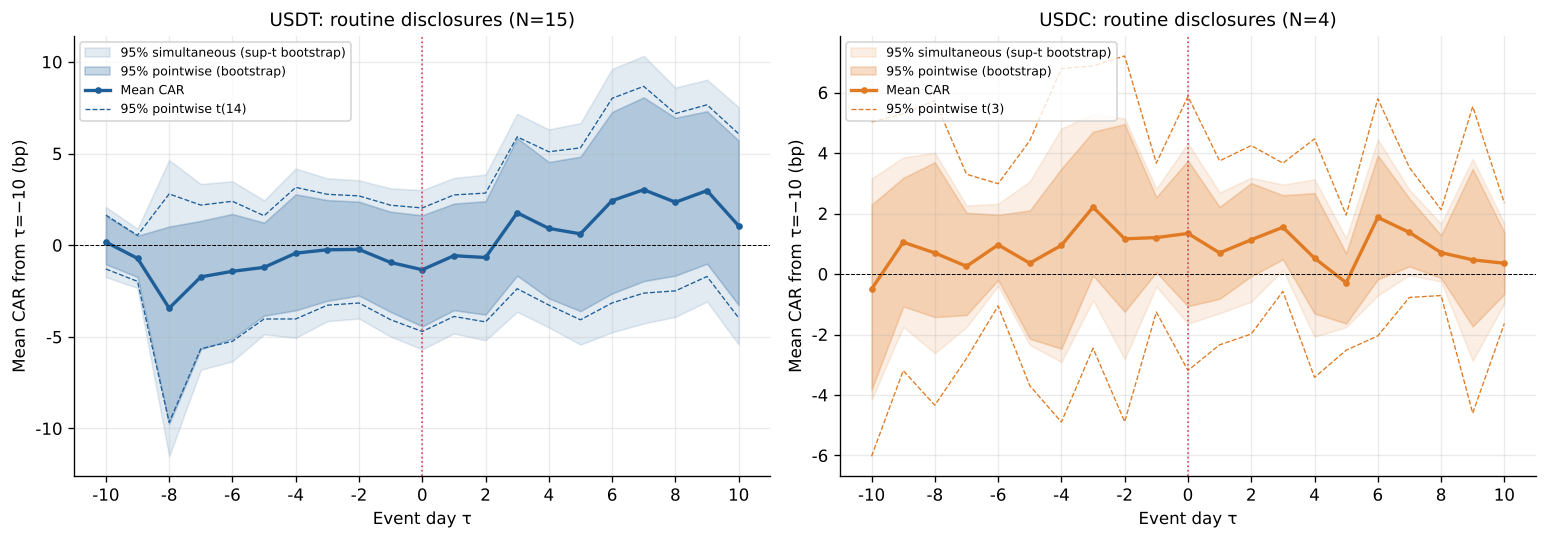

주: USDC routine N=4는 bootstrap 재표본이 256가지뿐이므로 t(3) 대역을 함께 보고한다.


In [26]:
# R6. Figure 2 수정 — 이벤트 경로 bootstrap 신뢰대역
B_PATH = 5000
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
band_rows = []
for ax, (coin, color) in zip(axes, [('USDT', '#1f5f99'), ('USDC', '#e07b24')]):
    d = ev_all[(ev_all['coin'] == coin) & (ev_all['routine'] == 1)]
    P = np.vstack([path(coin, dt).reindex(range(-10, 11)).fillna(0).cumsum().values for dt in d['event_date']]) * 1e4
    n = P.shape[0]; mean = P.mean(0)
    se = P.std(0, ddof=1) / np.sqrt(n); ct = tdist.ppf(0.975, n - 1)
    idx = rng.integers(0, n, size=(B_PATH, n)); BM = P[idx].mean(1)
    lo_pw, hi_pw = np.percentile(BM, [2.5, 97.5], axis=0)
    bsd = BM.std(0, ddof=1); bsd[bsd == 0] = np.nan
    supz = np.nanmax(np.abs((BM - mean) / bsd), axis=1); c_sim = np.quantile(supz, 0.95)
    ax.fill_between(range(-10, 11), mean - c_sim * bsd, mean + c_sim * bsd, color=color, alpha=0.12,
                    label='95% simultaneous (sup-t bootstrap)')
    ax.fill_between(range(-10, 11), lo_pw, hi_pw, color=color, alpha=0.25, label='95% pointwise (bootstrap)')
    ax.plot(range(-10, 11), mean, color=color, lw=2, marker='o', ms=3, label='Mean CAR')
    ax.plot(range(-10, 11), mean - ct * se, color=color, lw=0.8, ls='--')
    ax.plot(range(-10, 11), mean + ct * se, color=color, lw=0.8, ls='--', label=f'95% pointwise t({n-1})')
    ax.axhline(0, color='black', lw=0.6, ls='--'); ax.axvline(0, color='#d1495b', lw=1, ls=':')
    ax.set_title(f'{coin}: routine disclosures (N={n})', fontsize=11)
    ax.set_xlabel('Event day τ'); ax.set_ylabel('Mean CAR from τ=−10 (bp)'); ax.set_xticks(range(-10, 11, 2))
    ax.grid(alpha=0.25); ax.legend(fontsize=7.5, loc='upper left')
    band_rows += [dict(coin=coin, tau=t_, mean_bp=m_, pw_lo=a_, pw_hi=b_, t_lo=m_ - ct * s_, t_hi=m_ + ct * s_,
                       sim_lo=m_ - c_sim * q_, sim_hi=m_ + c_sim * q_, N=n)
                  for t_, m_, a_, b_, s_, q_ in zip(range(-10, 11), mean, lo_pw, hi_pw, se, bsd)]
plt.tight_layout(); plt.savefig(f'{REV}/Figure2_revised_car_path.png', dpi=DPI, bbox_inches='tight'); plt.show()
pd.DataFrame(band_rows).to_csv(f'{REV}/R6_figure2_bands.csv', index=False)
print('주: USDC routine N=4는 bootstrap 재표본이 256가지뿐이므로 t(3) 대역을 함께 보고한다.')

---

In [27]:
# R7. 비정상 거래량 수정 — 기준기간 정제, 달력효과, BTC 시장조정(파일 있을 때)
BTCV = None
if HAVE['btcvol']:
    BTCV = pd.read_csv(HAVE['btcvol'], parse_dates=['date']).set_index('date')['v_btc']
    master['v_btc'] = master['date'].map(BTCV)
    if master['v_btc'].isna().mean() > 0.05:
        print('⚠ BTC 거래량 날짜가 가격 자료와 맞지 않아 시장조정을 건너뜀'); BTCV = None
stress_idx = set()
for d in STRESS_DATES:
    if (master['date'] == d).any():
        i = t0_of(d); stress_idx.update(range(i - 10, i + 11))

def av_row(ev, base=(-60, -11), clean=True, adj=False):
    k = ev['coin'].lower(); t0 = t0_of(ev['event_date'])
    lv = np.log(master[f'v_{k}'])
    if adj:
        lv = lv - np.log(master['v_btc'])
    bidx = [i for i in range(t0 + base[0], t0 + base[1] + 1) if not (clean and i in stress_idx)]
    mu = lv.iloc[bidx].mean()
    out = {}
    for lo, hi in [(-1, 1), (-5, 5)]:
        out[f'AV_{lo}_{hi}'] = (lv.iloc[t0 + lo: t0 + hi + 1].mean() - mu) * 100
    out['n_base_days'] = len(bidx)
    return out

def holiday(d):
    return int((d.month == 12 and d.day >= 18) or (d.month == 1 and d.day <= 5))

rows = []
for _, ev in ev_all.iterrows():
    base = dict(coin=ev['coin'], event_date=ev['event_date'], event_type=ev['event_type'], routine=ev['routine'],
                quality_score=ev['quality_score'], holiday_window=holiday(ev['event_date']))
    for tag, kw in [('v9', dict(clean=False)), ('clean', dict(clean=True))] + \
                   ([('clean_btcadj', dict(clean=True, adj=True))] if BTCV is not None else []):
        r = av_row(ev, **kw)
        base.update({f'{k}_{tag}': v for k, v in r.items()})
    rows.append(base)
AVR = pd.DataFrame(rows); AVR.to_csv(f'{REV}/R7_abnormal_volume_revised.csv', index=False)
tags = ['v9', 'clean'] + (['clean_btcadj'] if BTCV is not None else [])
summ = []
for coin in ['USDT', 'USDC']:
    for samp, m in [('routine', AVR['routine'] == 1), ('routine excl. holiday', (AVR['routine'] == 1) & (AVR['holiday_window'] == 0)),
                    ('stress', AVR['routine'] == 0)]:
        d = AVR[(AVR['coin'] == coin) & m]
        for tg in tags:
            for w in ['AV_-1_1', 'AV_-5_5']:
                x = d[f'{w}_{tg}']
                summ.append(dict(coin=coin, sample=samp, version=tg, window=w, N=len(x), mean_logpts=x.mean(),
                                 p_t=ttest_1samp(x, 0).pvalue if len(x) > 1 else np.nan))
AVS = pd.DataFrame(summ); AVS.to_csv(f'{REV}/R7_abnormal_volume_summary.csv', index=False)
print(AVS.round(3).to_string(index=False))
if BTCV is None:
    print('\n⚠ btc_volume_daily.csv 없음 → BTC 시장조정 거래량은 파일을 올린 뒤 다시 실행')

coin                sample      version  window  N  mean_logpts   p_t
USDT               routine           v9 AV_-1_1 15        9.444 0.260
USDT               routine           v9 AV_-5_5 15        0.470 0.951
USDT               routine        clean AV_-1_1 15       10.030 0.219
USDT               routine        clean AV_-5_5 15        1.057 0.887
USDT               routine clean_btcadj AV_-1_1 15       -2.282 0.588
USDT               routine clean_btcadj AV_-5_5 15       -0.306 0.936
USDT routine excl. holiday           v9 AV_-1_1 15        9.444 0.260
USDT routine excl. holiday           v9 AV_-5_5 15        0.470 0.951
USDT routine excl. holiday        clean AV_-1_1 15       10.030 0.219
USDT routine excl. holiday        clean AV_-5_5 15        1.057 0.887
USDT routine excl. holiday clean_btcadj AV_-1_1 15       -2.282 0.588
USDT routine excl. holiday clean_btcadj AV_-5_5 15       -0.306 0.936
USDT                stress           v9 AV_-1_1  2       19.061 0.593
USDT                

---

In [28]:
# R8. 대안 벤치마크 — 교차 스테이블코인, BTC+교차 2요인, constant mean
def car_generic(coin, t0, mkts, lo=-5, hi=5):
    k = coin.lower(); s, e = t0 + EST_WIN[0], t0 + EST_WIN[1]
    est = master.iloc[s:e + 1].dropna(subset=[f'r_{k}'] + mkts)
    win = master.iloc[t0 + lo: t0 + hi + 1]
    if mkts:
        fit = sm.OLS(est[f'r_{k}'], sm.add_constant(est[mkts])).fit()
        er = fit.params['const'] + (win[mkts] * fit.params[mkts]).sum(axis=1)
    else:
        er = est[f'r_{k}'].mean()
    return (win[f'r_{k}'] - er).sum() * 1e4

other = {'USDT': 'r_usdc', 'USDC': 'r_usdt'}
rows = []
for _, ev in ev_all.iterrows():
    t0 = t0_of(ev['event_date']); c = ev['coin']
    rows.append(dict(coin=c, event_date=ev['event_date'], routine=ev['routine'],
                     btc=ev['CAR_-5_5'] * 1e4, cross_stable=car_generic(c, t0, [other[c]]),
                     btc_plus_cross=car_generic(c, t0, ['r_btc', other[c]]), constant_mean=car_generic(c, t0, [])))
ALT = pd.DataFrame(rows); ALT.to_csv(f'{REV}/R8_alt_benchmarks_events.csv', index=False)
summ = []
for coin in ['USDT', 'USDC']:
    d = ALT[(ALT['coin'] == coin) & (ALT['routine'] == 1)]
    for m in ['btc', 'cross_stable', 'btc_plus_cross', 'constant_mean']:
        summ.append(dict(coin=coin, model=m, N=len(d), mean_bp=d[m].mean(), p_t=ttest_1samp(d[m], 0).pvalue))
ALTS = pd.DataFrame(summ); ALTS.to_csv(f'{REV}/R8_alt_benchmarks_summary.csv', index=False)
print(ALTS.round(3).to_string(index=False))
print('추정기간 상관(USDT, USDC 일별 수익률):', round(master[['r_usdt', 'r_usdc']].corr().iloc[0, 1], 3),
      '| BTC–USDT:', round(master[['r_usdt', 'r_btc']].corr().iloc[0, 1], 3))

coin          model  N  mean_bp   p_t
USDT            btc 15    2.043 0.428
USDT   cross_stable 15    1.763 0.319
USDT btc_plus_cross 15    3.668 0.099
USDT  constant_mean 15    0.680 0.760
USDC            btc  4   -1.252 0.327
USDC   cross_stable  4   -2.711 0.178
USDC btc_plus_cross  4   -2.912 0.118
USDC  constant_mean  4   -1.471 0.296
추정기간 상관(USDT, USDC 일별 수익률): 0.296 | BTC–USDT: 0.037


---

In [29]:
# R9. 후보 이벤트 선정 엔진 — event_candidates_v10.csv 가 있으면 규칙을 자동 적용
#   필수 열: coin(USDT/USDC/ALL), event_date, category(report/policy/assurance/enforcement/stress/news),
#            importance(1~3, 클수록 우선), verified(0/1), source, source_url, note
MIN_GAP = 21   # 같은 코인 안에서 적용 (코인 간에는 적용하지 않음). 시장 전체 이벤트(coin=ALL)는 두 코인 모두에 적용

def select_events(c, min_gap=MIN_GAP):
    c = c.copy(); c['event_date'] = pd.to_datetime(c['event_date'], errors='coerce')
    rows = [{**r.to_dict(), 'coin_used': r['coin'], 'decision': 'excluded', 'reason': 'placeholder — release date to be filled'}
            for _, r in c[c['event_date'].isna()].iterrows()]
    c = c[c['event_date'].notna()]
    for coin in ['USDT', 'USDC']:
        sub = c[c['coin'].isin([coin, 'ALL'])].sort_values(['event_date', 'importance'], ascending=[True, False])
        kept = []
        for _, r in sub.iterrows():
            reason = ''
            if not (master['date'] == r['event_date']).any():
                reason = 'date not in price data'
            elif estimate_params(master, r['event_date'], f'r_{coin.lower()}') is None:
                # v9 코드는 추정창 시작(τ=−250)이 자료 시작 이전이면 제외한다 (MIN_OBS 50과 별개).
                # NYAG 2021-02-23이 여기에 해당 → 짧은 추정창 허용 여부는 R9b에서 민감도 분석
                n_avail = t0_of(r['event_date']) + EST_WIN[1] + 1
                reason = f'estimation window starts before data start (available {n_avail} days ≥ MIN_OBS {MIN_OBS})'
            elif int(r.get('verified', 0)) != 1:
                reason = 'date not yet verified against primary source'
            else:
                clash = [k for k in kept if abs((r['event_date'] - k['event_date']).days) < min_gap]
                if clash:
                    k = clash[0]
                    if r['importance'] > k['importance']:
                        kept.remove(k); rows.append({**k, 'coin_used': coin, 'decision': 'excluded',
                                                     'reason': f"replaced by {r['event_date'].date()} (within {min_gap}d, higher importance)"})
                    else:
                        reason = f"within {min_gap}d of {k['event_date'].date()} (kept: importance {k['importance']})"
            rec = {**r.to_dict(), 'coin_used': coin}
            if reason:
                rows.append({**rec, 'decision': 'excluded', 'reason': reason})
            else:
                kept.append(rec)
        rows += [{**k, 'decision': 'included', 'reason': ''} for k in kept]
    return pd.DataFrame(rows).sort_values(['coin_used', 'event_date'])

def circle_rows():
    """R01 결과를 후보 행으로 변환. 서명일 = 공개일 대용치. 품질지수·유형은 잠정 코딩(교수님 코딩으로 대체 예정)."""
    if not HAVE.get('circle'):
        return pd.DataFrame()
    c = pd.read_csv(HAVE['circle'], parse_dates=['as_of', 'sign_date']).dropna(subset=['sign_date'])
    c = c[(c['sign_date'] >= master['date'].min() + pd.Timedelta(days=260)) & (c['sign_date'] <= master['date'].max() - pd.Timedelta(days=15))]
    existing = ev_all.loc[(ev_all['coin'] == 'USDC') & (ev_all['routine'] == 1), 'event_date']   # 같은 공시 중복만(스트레스 이벤트 제외)
    rows = []
    for _, r in c.iterrows():
        if (abs((existing - r['sign_date']).dt.days) <= 7).any():
            continue                                   # v9에 이미 있는 보고서(같은 공시)
        detail = int(r['as_of'] >= pd.Timestamp('2022-07-01'))
        rows.append(dict(coin='USDC', event_date=r['sign_date'].strftime('%Y-%m-%d'), category='report', importance=2,
                         verified=int(r['method'] in ('city', 'pdf_meta+text')), in_v9=0, scenario='base',
                         description=f"Circle monthly attestation as of {r['as_of'].date()} ({r['auditor']})",
                         source='Independent accountant report date (attestation PDF)', source_url=r['url'],
                         note=f"date method={r['method']}", q_amt=1, q_comp=1, q_detail=detail, q_audit=1,
                         prov_type='neutral'))
    return pd.DataFrame(rows)

SCEN_DEF = {
    'v9_reproduction': lambda c: c[c['in_v9'] == 1].assign(coin=lambda x: x['coin'].where(x['event_date'].astype(str) != '2022-11-11', 'USDT')),
    'base_extended':   lambda c: c[c['scenario'] == 'base'],
    'base_no_circle':  lambda c: c[(c['scenario'] == 'base') & ~c['description'].str.startswith('Circle monthly', na=False)],
    'no_terra':        lambda c: c[(c['scenario'] == 'base') & ~((c['category'] == 'stress') & c['event_date'].astype(str).str.startswith('2022-05'))],
    'alt_terra_onset': lambda c: c[((c['scenario'] == 'base') & ~(c['event_date'].astype(str) == '2022-05-12')) | (c['scenario'] == 'alt_terra_onset')],
    'alt_ftx_run':     lambda c: c[((c['scenario'] == 'base') & ~(c['event_date'].astype(str) == '2022-11-11')) | (c['scenario'] == 'alt_ftx_run')],
}
SEL_BY = {}
if HAVE['cands']:
    CAND = pd.concat([pd.read_csv(HAVE['cands']), circle_rows()], ignore_index=True)
    CAND['in_v9'] = CAND['in_v9'].fillna(0).astype(int)
    for name, f in SCEN_DEF.items():
        sel = select_events(f(CAND)); sel['scenario_run'] = name; SEL_BY[name] = sel
    SEL = SEL_BY['base_extended']
    pd.concat(SEL_BY.values()).to_csv(f'{REV}/R9_event_selection_log.csv', index=False)
    print(pd.concat(SEL_BY.values()).groupby(['scenario_run', 'coin_used', 'decision']).size().unstack().fillna(0).astype(int).to_string())
    print('\n기본 확장 표본에서 제외된 후보:')
    print(SEL[SEL['decision'] == 'excluded'][['coin_used', 'event_date', 'category', 'reason']].to_string(index=False))
else:
    print('⚠ event_candidates_v10.csv 없음 → 후보 목록을 만든 뒤 다시 실행')

# R9b. 짧은 추정창 허용 시 NYAG(2021-02-23) — R4-3 ("MIN_OBS 50 충족" 지적) 민감도
def car_short(coin, date, lo, hi):
    k = coin.lower(); t0 = t0_of(date); s_ = max(0, t0 + EST_WIN[0]); e_ = t0 + EST_WIN[1]
    est = master.iloc[s_:e_ + 1].dropna(subset=[f'r_{k}', 'r_btc'])
    fit = sm.OLS(est[f'r_{k}'], sm.add_constant(est['r_btc'])).fit()
    win = master.iloc[t0 + lo: t0 + hi + 1]
    ar = win[f'r_{k}'] - (fit.params['const'] + fit.params['r_btc'] * win['r_btc'])
    return len(est), ar.sum() * 1e4, ar.sum() / (fit.resid.std(ddof=2) * np.sqrt(hi - lo + 1))
for w, (lo, hi) in {'CAR_-1_1': (-1, 1), 'CAR_-3_3': (-3, 3), 'CAR_-5_5': (-5, 5)}.items():
    n_, c_, s_ = car_short('USDT', '2021-02-23', lo, hi)
    print(f'NYAG 2021-02-23 {w}: 추정 {n_}일, CAR={c_:+.2f} bp, SCAR={s_:+.2f}')

decision                   excluded  included
scenario_run    coin_used                    
alt_ftx_run     USDC              2         7
                USDT              4        19
alt_terra_onset USDC              2         7
                USDT              4        19
base_extended   USDC              2         7
                USDT              4        19
base_no_circle  USDC              2         7
                USDT              4        19
no_terra        USDC              2         6
                USDT              3        19
v9_reproduction USDC              0         5
                USDT              0        17

기본 확장 표본에서 제외된 후보:
coin_used event_date    category                                                                       reason
     USDC 2022-11-03      policy                       replaced by 2022-11-11 (within 21d, higher importance)
     USDC 2023-03-13        news                                within 21d of 2023-03-10 (kept: importance 3)
     U

---

In [30]:
# R10. 유통량 반응 (supply_daily.csv 가 있을 때) — 상환/발행 경로 (R2-14)
if HAVE['supply']:
    SUP = pd.read_csv(HAVE['supply'], parse_dates=['date']).set_index('date')
    for k in ['usdt', 'usdc']:
        master[f'ls_{k}'] = np.log(master['date'].map(SUP[f'supply_{k}']))
    def sup_chg(coin, t0, lo, hi):
        s = master[f'ls_{coin.lower()}']
        return (s.iloc[t0 + hi] - s.iloc[t0 + lo - 1]) * 1e4      # bp of supply
    SW = {'S_-1_1': (-1, 1), 'S_0_5': (0, 5), 'S_0_10': (0, 10)}
    rows = []
    for _, ev in ev_all.iterrows():
        t0 = t0_of(ev['event_date']); r = dict(coin=ev['coin'], event_date=ev['event_date'], routine=ev['routine'])
        for w, (lo, hi) in SW.items():
            v = sup_chg(ev['coin'], t0, lo, hi)
            pl = np.array([sup_chg(ev['coin'], i, lo, hi) for i in placebo_dates(ev['coin'])])
            pl = pl[np.isfinite(pl)]
            r[w] = v; r[f'pct_{w}'] = pctile(pl, v); r[f'abn_{w}'] = v - np.median(pl)
        rows.append(r)
    SUPR = pd.DataFrame(rows); SUPR.to_csv(f'{REV}/R10_supply_response.csv', index=False)
    print(SUPR.round(1).to_string(index=False))
    for coin in ['USDT', 'USDC']:
        d = SUPR[(SUPR['coin'] == coin) & (SUPR['routine'] == 1)]
        print(coin, 'routine abnormal supply change (bp, median-adjusted):',
              {w: (round(d[f'abn_{w}'].mean(), 1), round(ttest_1samp(d[f'abn_{w}'], 0).pvalue, 3)) for w in SW})
else:
    print('⚠ supply_daily.csv 없음 → Colab 수집 스크립트 실행 후 다시 실행')


# R10b. 유통량 집계 오류일 보정 강건성 — 하루 급변 후 다음 날 반대로 되돌아온 날(|변화|>250bp, 되돌림>60%)을 앞뒤 평균으로 보정
if HAVE['supply']:
    clean_log = {}
    for k in ['usdt', 'usdc']:
        ls = master[f'ls_{k}'].copy(); g = ls.diff() * 1e4
        bad = [i for i in range(1, len(g) - 1) if abs(g.iloc[i]) > 250 and np.sign(g.iloc[i + 1]) == -np.sign(g.iloc[i])
               and abs(g.iloc[i + 1]) > 0.6 * abs(g.iloc[i])]
        for i in bad:
            ls.iloc[i] = (ls.iloc[i - 1] + ls.iloc[i + 1]) / 2
        master[f'lsc_{k}'] = ls; clean_log[k] = [str(master['date'].iloc[i].date()) for i in bad]
    print('보정한 날짜:', clean_log)
    rows = []
    for _, ev in ev_all.iterrows():
        k = ev['coin'].lower(); t0 = t0_of(ev['event_date'])
        r = dict(coin=ev['coin'], event_date=ev['event_date'].date(), routine=ev['routine'])
        for w, (lo, hi) in SW.items():
            for tag, col in [('raw', f'ls_{k}'), ('clean', f'lsc_{k}')]:
                s_ = master[col]; v = (s_.iloc[t0 + hi] - s_.iloc[t0 + lo - 1]) * 1e4
                pl = np.array([(s_.iloc[i + hi] - s_.iloc[i + lo - 1]) * 1e4 for i in placebo_dates(ev['coin'])])
                r[f'{w}_{tag}'] = v; r[f'pct_{w}_{tag}'] = pctile(pl, v)
        rows.append(r)
    SUPC = pd.DataFrame(rows); SUPC.to_csv(f'{REV}/R10b_supply_cleaning_robustness.csv', index=False)
    print(SUPC[[c for c in SUPC.columns if c.startswith(('coin', 'event_date', 'pct_S_0_10'))]].round(1).to_string(index=False))

coin event_date  routine  S_-1_1  pct_S_-1_1  abn_S_-1_1   S_0_5  pct_S_0_5  abn_S_0_5  S_0_10  pct_S_0_10  abn_S_0_10
USDT 2021-05-13        1   174.2        94.8       166.3   171.2       88.9      147.3   339.5        90.8       288.9
USDT 2021-08-09        1   160.3        94.0       152.4     0.0       21.3      -24.0   157.7        80.2       107.1
USDT 2021-10-15        0    -0.0        20.0        -7.9    -0.5       17.2      -24.4    -4.0        12.7       -54.6
USDT 2021-12-03        1   132.8        92.0       124.9   393.1       96.0      369.2   393.3        91.7       342.7
USDT 2022-02-21        1    83.9        88.3        76.0    42.4       62.7       18.4    90.1        66.2        39.5
USDT 2022-05-19        1  -206.8         0.5      -214.7  -126.6        1.8     -150.6  -227.8         1.5      -278.4
USDT 2022-08-19        1    -2.4        14.5       -10.3     0.0       25.8      -23.9     0.0        21.7       -50.6
USDT 2022-11-11        0  -356.0         0.1    

coin event_date  pct_S_0_10_raw  pct_S_0_10_clean
USDT 2021-05-13            90.8              91.0
USDT 2021-08-09            80.2              80.4
USDT 2021-10-15            12.7              12.7
USDT 2021-12-03            91.7              91.9
USDT 2022-02-21            66.2              66.2
USDT 2022-05-19             1.5               1.5
USDT 2022-08-19            21.7              21.7
USDT 2022-11-11             1.0               1.0
USDT 2023-02-09            90.1              90.3
USDT 2023-05-10            58.5              58.5
USDT 2023-07-31             8.1               8.1
USDT 2023-10-31            85.8              85.9
USDT 2024-01-31            32.3              32.3
USDT 2024-05-01            31.9              31.9
USDT 2024-07-31            66.3              66.4
USDT 2024-10-31            88.0              88.2
USDT 2025-01-31            80.1              80.3
USDC 2021-07-20            63.3              63.4
USDC 2021-08-23            51.9              51.9


---

In [31]:
# R11. SVB 시간별 경로 (usdc_hourly_svb.csv 가 있을 때)
#   연대표 시각은 1차 출처로 확인 후 입력 (UTC). verified=False 인 항목은 그림에 점선으로 표시.
SVB_CHRONO = [
    # (UTC 시각, 사건, verified)
    ('2023-03-10 16:00', 'SVB closed by CA DFPI; FDIC receiver (time TBC)', False),
    ('2023-03-11 03:00', 'Circle discloses USD 3.3B of reserves at SVB (time TBC)', False),
    ('2023-03-12 22:15', 'Treasury/Fed/FDIC joint statement (time TBC)', False),
]
if HAVE['hourly']:
    HR = pd.read_csv(HAVE['hourly'], parse_dates=['time_utc'])
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.plot(HR['time_utc'], (HR['close'] - 1) * 1e4, lw=1.1, color='#e07b24', label='USDC/USDT close − 1 (bp)')
    ax.fill_between(HR['time_utc'], (HR['low'] - 1) * 1e4, (HR['high'] - 1) * 1e4, color='#e07b24', alpha=0.2, label='hourly low–high')
    for ts, lab, ok in SVB_CHRONO:
        x = pd.Timestamp(ts, tz='UTC'); ax.axvline(x, color='#d1495b', lw=1, ls='-' if ok else ':')
        ax.text(x, ax.get_ylim()[0], ' ' + lab, rotation=90, fontsize=7, va='bottom')
    ax.axhline(0, color='black', lw=0.6, ls='--'); ax.set_ylabel('Deviation from par (bp)'); ax.grid(alpha=0.25); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f'{REV}/Figure_SVB_hourly.png', dpi=DPI, bbox_inches='tight'); plt.show()
    lowest = HR.loc[HR['low'].idxmin()]
    print('최저:', lowest['time_utc'], round((lowest['low'] - 1) * 1e4, 1), 'bp')
    first_back = HR[(HR['time_utc'] > lowest['time_utc']) & ((HR['close'] - 1).abs() * 1e4 < 50)]
    print('|이탈|<50bp 복귀 첫 시각:', first_back['time_utc'].iloc[0] if len(first_back) else '없음')
else:
    print('⚠ usdc_hourly_svb.csv 없음 → (선택) Colab 수집 스크립트 실행 후 다시 실행')

⚠ usdc_hourly_svb.csv 없음 → (선택) Colab 수집 스크립트 실행 후 다시 실행


---

In [32]:
# R13. 확장 표본 재분석 — 선정 엔진(R9) 결과를 CAR·페그·유통량·H2 분석에 연결 (R1-1, R2-2, R4-1·3)
#   시나리오: v9_reproduction(검증용), base_extended(기본), base_no_circle, no_terra, alt_terra_onset, alt_ftx_run
V9TYPE = {(c, d.strftime('%Y-%m-%d')): t for c, d, t in zip(ev_all['coin'], ev_all['event_date'], ev_all['event_type'])}
V9Q = {(c, d.strftime('%Y-%m-%d')): q for c, d, q in zip(ev_all['coin'], ev_all['event_date'], ev_all['quality_score'])}

def build_events(sel):
    inc = sel[sel['decision'] == 'included'].copy()
    rows = []
    for _, r in inc.iterrows():
        coin = r['coin_used']; d = pd.Timestamp(r['event_date']).strftime('%Y-%m-%d'); key = (coin, d)
        if r['category'] in ('stress', 'enforcement'):
            et = 'negative'
        elif key in V9TYPE:
            et = V9TYPE[key]
        elif r['category'] == 'policy':
            et = 'positive'
        else:
            et = r.get('prov_type') if isinstance(r.get('prov_type'), str) else 'neutral'
        if key in V9Q:
            q = V9Q[key]
        elif pd.notna(r.get('q_amt')):
            q = int(r['q_amt'] + r['q_comp'] + r['q_detail'] + r['q_audit'] + 1)
        else:
            q = np.nan
        rows.append(dict(coin=coin, event_date=pd.Timestamp(d), event_type=et, quality_score=q,
                         description=str(r['description'])[:80], source=r.get('source', ''), source_url=r.get('source_url', ''),
                         category=r['category'], new=int(key not in V9TYPE)))
    return pd.DataFrame(rows).sort_values(['coin', 'event_date']).reset_index(drop=True)

def run_scenario(name, sel):
    evx = build_events(sel)
    parts = []
    for coin, ret in [('USDT', 'r_usdt'), ('USDC', 'r_usdc')]:
        cdf, _ = compute_car(master, evx, coin, ret)
        if len(cdf):
            parts.append(make_event_level(cdf))
    el = pd.concat(parts, ignore_index=True).merge(evx[['coin', 'event_date', 'category', 'new']], on=['coin', 'event_date'])
    el['routine'] = (el['event_type'] != 'negative').astype(int)
    el['is_report'] = ((el['routine'] == 1) & (el['category'] == 'report')).astype(int)
    el['is_usdc'] = (el['coin'] == 'USDC').astype(int)
    for w in ALL_WINS + ['CAR_-10_10']:
        el[w + '_bp'] = el[w] * 1e4
    pm = []
    for _, e in el.iterrows():
        t0 = t0_of(e['event_date']); r = {}
        for tag, (lo, hi) in {'m55': (-5, 5), 'm05': (0, 5)}.items():
            v = peg_metrics(e['coin'], t0, lo, hi)['maxabs_rel_bp']
            loc = [peg_metrics(e['coin'], i, lo, hi)['maxabs_rel_bp'] for i in placebo_dates(e['coin'])[::2] if abs(i - t0) <= LOCAL]
            r[f'maxabs_rel_{tag}'] = v; r[f'pctL_maxabs_rel_{tag}'] = pctile(loc, v)
        if HAVE['supply']:
            col = f"lsc_{e['coin'].lower()}" if f"lsc_{e['coin'].lower()}" in master else f"ls_{e['coin'].lower()}"
            s_ = master[col]; v = (s_.iloc[t0 + 10] - s_.iloc[t0 - 1]) * 1e4
            pl = [(s_.iloc[i + 10] - s_.iloc[i - 1]) * 1e4 for i in placebo_dates(e['coin'])]
            r['S_0_10_bp'] = v; r['pct_S_0_10'] = pctile(pl, v)
        pm.append(r)
    el = pd.concat([el.reset_index(drop=True), pd.DataFrame(pm)], axis=1)
    el.to_csv(f'{REV}/R13_events_{name}.csv', index=False)
    summ = []
    for coin in ['USDT', 'USDC']:
        d = el[(el['coin'] == coin) & (el['routine'] == 1)]
        x = d['CAR_-5_5_bp'].values; n = len(x)
        row = dict(scenario=name, coin=coin, N_routine=n, N_new=int(d['new'].sum()),
                   N_stress=int(((el['coin'] == coin) & (el['routine'] == 0)).sum()),
                   CAR55_mean=x.mean() if n else np.nan, CAR55_p=ttest_1samp(x, 0).pvalue if n > 1 else np.nan,
                   TOST5_p=tost(x, 5) if n > 1 else np.nan, TOST10_p=tost(x, 10) if n > 1 else np.nan,
                   MDE80_t=mde_t(x.std(ddof=1), n) if n > 1 else np.nan,
                   pegL05_median_pct=d['pctL_maxabs_rel_m05'].median(),
                   pegL05_p=wilcoxon(d['pctL_maxabs_rel_m05'] - 50).pvalue if n >= 5 else np.nan)
        if 'pct_S_0_10' in d:
            row.update(supply_median_pct=d['pct_S_0_10'].median(),
                       supply_p=wilcoxon(d['pct_S_0_10'] - 50).pvalue if n >= 5 else np.nan)
        summ.append(row)
    rep = el[el['is_report'] == 1].dropna(subset=['quality_score'])
    if len(rep) > 4 and rep['quality_score'].nunique() > 1:
        X = sm.add_constant(rep[['quality_score', 'is_usdc']].astype(float)); Y = rep['CAR_-5_5_bp']
        f = sm.OLS(Y, X).fit(cov_type='HC1'); h = sm.OLS(Y, X).fit().get_influence().hat_matrix_diag
        for r in summ:
            r.update(H2_N=len(rep), H2_coef=f.params['quality_score'], H2_p_HC1=f.pvalues['quality_score'],
                     H2_p_wild=wild_p(Y, X, 1, B=1999), H2_max_lev=h.max(),
                     Q_dist=str(rep['quality_score'].value_counts().sort_index().to_dict()))
    return el, summ

R13S = []
if SEL_BY:
    for name, sel in SEL_BY.items():
        try:
            _, sm_ = run_scenario(name, sel); R13S += sm_
        except Exception as e:
            print('⚠', name, '실패:', e)
    R13 = pd.DataFrame(R13S); R13.to_csv(f'{REV}/R13_scenarios_summary.csv', index=False)
    print(R13.round(3).to_string(index=False))
    print('\n주: v9_reproduction의 N·평균이 R1 routine 결과와 같아야 한다(파이프라인 검증).')

       scenario coin  N_routine  N_new  N_stress  CAR55_mean  CAR55_p  TOST5_p  TOST10_p  MDE80_t  pegL05_median_pct  pegL05_p  supply_median_pct  supply_p  H2_N  H2_coef  H2_p_HC1  H2_p_wild  H2_max_lev                    Q_dist
v9_reproduction USDT         15      0         2       2.043    0.428    0.129     0.003    7.548             75.824     0.010             66.425     0.349    17   -2.253     0.172      0.698        0.89       {3: 1, 4: 1, 5: 15}
v9_reproduction USDC          4      0         1      -1.252    0.327    0.020     0.002    4.557             34.104       NaN             51.933       NaN    17   -2.253     0.172      0.698        0.89       {3: 1, 4: 1, 5: 15}
  base_extended USDT         15      1         4       1.405    0.577    0.083     0.002    7.404             71.667     0.107             66.425     0.182    16   -2.503     0.149      0.710        0.89 {3.0: 1, 4.0: 1, 5.0: 14}
  base_extended USDC          4      0         3      -1.252    0.327    0.020  

---

In [33]:
# R14. 2차 코딩 일치도 (R1-3, R2-4, R4-5) — coding_second.csv(교수님 독립 코딩)가 있으면 계산
#   열: coin, event_date, event_type(positive/neutral/negative), amt, composition, detail, audit
def cohen_kappa(a, b, weights=None):
    a = pd.Series(a).astype(str).values; b = pd.Series(b).astype(str).values
    cats = sorted(set(a) | set(b)); k = len(cats); idx = {c: i for i, c in enumerate(cats)}
    O = np.zeros((k, k))
    for x, y in zip(a, b):
        O[idx[x], idx[y]] += 1
    n = O.sum(); E = np.outer(O.sum(1), O.sum(0)) / n
    if weights == 'linear':
        W = np.abs(np.subtract.outer(np.arange(k), np.arange(k))) / max(k - 1, 1)
    else:
        W = 1 - np.eye(k)
    return 1 - (W * O).sum() / (W * E).sum() if (W * E).sum() > 0 else 1.0

if HAVE.get('coding2'):
    C2 = pd.read_csv(HAVE['coding2'], parse_dates=['event_date'])
    M = H2d.merge(C2, on=['coin', 'event_date'], suffixes=('_1', '_2'))
    res = {'N': len(M), 'event_type': cohen_kappa(M['event_type_1'], M['event_type_2'])}
    for c in ['amt', 'composition', 'detail', 'audit']:
        res[c] = cohen_kappa(M[f'{c}_1'], M[f'{c}_2'])
    M['q2'] = M[['amt_2', 'composition_2', 'detail_2', 'audit_2']].sum(axis=1) + 1
    res['quality_score_weighted'] = cohen_kappa(M['quality_score'], M['q2'], 'linear')
    res['pct_agree_type'] = (M['event_type_1'] == M['event_type_2']).mean()
    pd.Series(res).to_csv(f'{REV}/R14_intercoder_kappa.csv')
    print(pd.Series(res).round(3).to_string())
    print('불일치 이벤트:'); print(M[M['event_type_1'] != M['event_type_2']][['coin', 'event_date', 'event_type_1', 'event_type_2']].to_string(index=False))
else:
    print('⚠ coding_second.csv 없음 → 교수님 독립 코딩을 받은 뒤 계산')

⚠ coding_second.csv 없음 → 교수님 독립 코딩을 받은 뒤 계산


---

In [34]:
# R15. 교수님 독립 코딩 시트 생성 (R1-3, R2-4, R4-5) — 최종 확장 표본의 routine 공시 전체
#   1차 코딩(우리)은 시트에 넣지 않는다(독립성). 정답 키는 별도 파일(coding_first_key.csv)로 저장.
CODING_RULES = [
    ('목적', '각 공시를 아래 규칙만으로 독립적으로 코딩합니다. 시장 반응(가격·거래량)은 보지 말고 공시 내용만 보세요.'),
    ('event_type', 'positive: 직전 공시 대비 공개 범위가 넓어졌거나(새 항목·세부정보 추가) 더 안전한 자산으로의 변화(예: CP 축소)를 보고'),
    ('', 'neutral: 직전 공시와 형식·범위가 같고 실질적 변화가 없는 정기 공시 (이익·초과준비금 보고만 추가된 경우 포함)'),
    ('', 'negative: 제재, 준비금 손상, 시장 전체 위기 (이 시트에는 없음 — 자동 분류)'),
    ('amt (0/1)', '준비금 총액을 공개했는가'),
    ('composition (0/1)', '자산군별 구성(현금, 국채, CP, 레포 등)을 공개했는가'),
    ('detail (0/1)', '자산군 이하 세부(발행사, 신용등급, 만기, CUSIP, 보관기관 중 하나 이상)를 공개했는가'),
    ('audit (0/1)', '독립 회계법인이 구성 내역까지 확인한 증명(attestation/examination)인가'),
    ('품질지수', 'amt + composition + detail + audit + 1 (자동 계산, 1~5)'),
    ('판단이 어려운 경우', 'notes 열에 이유를 적고 가장 가까운 값을 선택'),
]
if SEL_BY:
    EVF = build_events(SEL_BY['base_extended'])
    EVF = EVF[EVF['event_type'] != 'negative'].reset_index(drop=True)
    sheet = EVF[['coin', 'event_date', 'category', 'description', 'source', 'source_url']].copy()
    sheet.insert(0, 'No', range(1, len(sheet) + 1))
    for c in ['event_type', 'amt', 'composition', 'detail', 'audit', 'notes']:
        sheet[c] = ''
    key = EVF[['coin', 'event_date', 'event_type', 'quality_score']].copy()
    key.to_csv(f'{REV}/coding_first_key.csv', index=False)
    path_x = f'{REV}/coding_sheet_second_coder.xlsx'
    try:
        with pd.ExcelWriter(path_x) as xw:
            pd.DataFrame(CODING_RULES, columns=['항목', '규칙']).to_excel(xw, sheet_name='코딩 규칙', index=False)
            sheet.assign(event_date=sheet['event_date'].dt.strftime('%Y-%m-%d')).to_excel(xw, sheet_name='코딩표', index=False)
        print('✅ 코딩 시트:', path_x, f'({len(sheet)}건: USDT {int((sheet.coin=="USDT").sum())}, USDC {int((sheet.coin=="USDC").sum())})')
    except Exception as e:
        sheet.to_csv(path_x.replace('.xlsx', '.csv'), index=False); print('⚠ xlsx 실패, csv로 저장:', e)
    print('완성본은 coding_second.csv (열: coin, event_date, event_type, amt, composition, detail, audit)로 저장하면 R14가 κ를 계산합니다.')

✅ 코딩 시트: ./stablecoin_research/revision/coding_sheet_second_coder.xlsx (19건: USDT 15, USDC 4)
완성본은 coding_second.csv (열: coin, event_date, event_type, amt, composition, detail, audit)로 저장하면 R14가 κ를 계산합니다.


---

In [35]:
# R16. 경쟁 뉴스 달력과 오염 민감도 (R1-6, R2-12)
#   시장 전체 또는 스테이블코인 관련 주요 사건 목록(2021–2025)과 각 이벤트 창(−5,+5)의 겹침을 자동 표시.
#   날짜는 사건이 처음 공개된 날(UTC 기준). verified=0 행은 1차 출처 확인 후 1로 바꾼다.
MARKET_NEWS = pd.DataFrame([
    ('2021-05-12', 'Tesla suspends Bitcoin payments', 'market', 1),
    ('2021-05-18', 'China bans financial institutions from crypto services; May 19 crash', 'market', 1),
    ('2021-05-21', 'China State Council targets Bitcoin mining', 'market', 1),
    ('2021-06-09', 'El Salvador passes Bitcoin Law', 'market', 1),
    ('2021-09-07', 'Bitcoin becomes legal tender in El Salvador; flash crash', 'market', 1),
    ('2021-09-24', 'PBoC declares all crypto transactions illegal', 'market', 1),
    ('2021-10-19', 'First US Bitcoin futures ETF (BITO) begins trading', 'market', 1),
    ('2021-11-10', 'Bitcoin all-time high (~$69k)', 'market', 1),
    ('2021-11-15', 'US infrastructure law with crypto broker reporting signed', 'regulation', 1),
    ('2022-03-09', 'US executive order on digital assets', 'regulation', 1),
    ('2022-06-12', 'Celsius pauses withdrawals', 'market', 1),
    ('2022-06-27', 'Three Arrows Capital default/liquidation order', 'market', 1),
    ('2022-07-13', 'Celsius files for bankruptcy', 'market', 1),
    ('2022-08-08', 'OFAC sanctions Tornado Cash (USDC addresses frozen)', 'stablecoin', 1),
    ('2022-09-15', 'Ethereum Merge', 'market', 1),
    ('2023-01-19', 'Genesis files for bankruptcy', 'market', 1),
    ('2023-02-13', 'NYDFS orders Paxos to stop minting BUSD', 'stablecoin', 1),
    ('2023-03-08', 'Silvergate announces wind-down', 'market', 1),
    ('2023-06-05', 'SEC sues Binance (Coinbase on Jun 6)', 'regulation', 1),
    ('2023-06-15', 'BlackRock files for spot Bitcoin ETF', 'market', 1),
    ('2023-07-13', 'Ripple partial court win vs SEC', 'regulation', 1),
    ('2023-08-07', 'PayPal launches PYUSD stablecoin', 'stablecoin', 1),
    ('2023-08-29', 'Grayscale wins appeal against SEC', 'regulation', 1),
    ('2023-11-21', 'Binance $4.3B settlement; CZ steps down', 'regulation', 1),
    ('2024-01-10', 'SEC approves spot Bitcoin ETFs', 'regulation', 1),
    ('2024-03-14', 'Bitcoin all-time high (~$73k)', 'market', 1),
    ('2024-04-20', 'Bitcoin halving', 'market', 1),
    ('2024-05-23', 'SEC approves spot Ether ETF filings', 'regulation', 1),
    ('2024-06-30', 'EU MiCA stablecoin rules apply', 'stablecoin', 1),
    ('2024-08-05', 'Global market sell-off (yen carry unwind)', 'market', 1),
    ('2024-11-05', 'US presidential election', 'market', 1),
    ('2024-12-05', 'Bitcoin crosses $100k', 'market', 1),
    ('2024-12-30', 'MiCA fully applicable; EU venues restrict non-compliant stablecoins', 'stablecoin', 0),
    ('2025-01-23', 'US executive order on digital assets (stablecoins)', 'regulation', 1),
    ('2025-02-21', 'Bybit exchange hack', 'market', 1),
    ('2025-03-06', 'US Strategic Bitcoin Reserve executive order', 'regulation', 1),
    ('2025-04-02', 'US tariff announcement; risk-asset sell-off', 'market', 1),
], columns=['date', 'news', 'kind', 'verified'])
MARKET_NEWS['date'] = pd.to_datetime(MARKET_NEWS['date'])
MARKET_NEWS.to_csv(f'{REV}/R16_market_news_calendar.csv', index=False)

if SEL_BY:
    EB = build_events(SEL_BY['base_extended'])
    rows = []
    for _, e in EB.iterrows():
        hit = MARKET_NEWS[(MARKET_NEWS['date'] - e['event_date']).dt.days.between(-5, 5)]
        rows.append(dict(coin=e['coin'], event_date=e['event_date'].date(), event_type=e['event_type'],
                         n_news=len(hit), news='; '.join(f"{d.date()} {n}" for d, n in zip(hit['date'], hit['news'])),
                         stablecoin_news=int((hit['kind'] == 'stablecoin').any())))
    CAL = pd.DataFrame(rows); CAL.to_csv(f'{REV}/R16_event_window_news.csv', index=False)
    print('창 안에 주요 뉴스가 있는 이벤트:', int((CAL['n_news'] > 0).sum()), '/', len(CAL))
    print(CAL[CAL['n_news'] > 0][['coin', 'event_date', 'event_type', 'news']].to_string(index=False))
    # 민감도: 오염 이벤트를 뺀 routine 결과 (기본 확장 표본)
    elx = pd.read_csv(f'{REV}/R13_events_base_extended.csv', parse_dates=['event_date'])
    flag = {(c, pd.Timestamp(d)) for c, d, n in zip(CAL['coin'], CAL['event_date'], CAL['n_news']) if n > 0}
    elx['contaminated'] = [int((c, d) in flag) for c, d in zip(elx['coin'], elx['event_date'])]
    out = []
    for coin in ['USDT', 'USDC']:
        for lab, m in [('all routine', elx['routine'] == 1), ('routine, clean windows', (elx['routine'] == 1) & (elx['contaminated'] == 0))]:
            d = elx[(elx['coin'] == coin) & m]; x = d['CAR_-5_5_bp'].values
            out.append(dict(coin=coin, sample=lab, N=len(x), CAR55_mean=x.mean(), p=ttest_1samp(x, 0).pvalue if len(x) > 1 else np.nan,
                            TOST5_p=tost(x, 5) if len(x) > 1 else np.nan, TOST10_p=tost(x, 10) if len(x) > 1 else np.nan,
                            pegL05_median=d['pctL_maxabs_rel_m05'].median()))
    SENS = pd.DataFrame(out); SENS.to_csv(f'{REV}/R16_contamination_sensitivity.csv', index=False)
    print(SENS.round(3).to_string(index=False))

창 안에 주요 뉴스가 있는 이벤트: 8 / 26
coin event_date event_type                                                                                                                        news
USDC 2023-01-17   positive                                                                                     2023-01-19 Genesis files for bankruptcy
USDC 2023-03-10   negative                                                                                   2023-03-08 Silvergate announces wind-down
USDT 2021-05-13   positive 2021-05-12 Tesla suspends Bitcoin payments; 2021-05-18 China bans financial institutions from crypto services; May 19 crash
USDT 2021-10-15   negative                                                               2021-10-19 First US Bitcoin futures ETF (BITO) begins trading
USDT 2023-02-09   positive                                                                          2023-02-13 NYDFS orders Paxos to stop minting BUSD
USDT 2023-03-10   negative                                         

---

In [36]:
# R12. 본문용 이벤트 단위 결과표 (R4-10: Table S1 → 본문) + 소프트웨어 버전
src = events_df[['coin', 'event_date', 'source', 'source_url']]
T_EV = (ev_all[['coin', 'event_date', 'event_type', 'quality_score', 'routine', 'is_report', 'description',
                'CAR_-1_1', 'CAR_-3_3', 'CAR_-5_5']]
        .merge(PEG[['coin', 'event_date', 'maxabs_rel_bp', 'pctL_maxabs_rel_bp', 'min_rel_bp', 'maxabs_dev_bp']], on=['coin', 'event_date'])
        .merge(AVR[['coin', 'event_date', 'AV_-1_1_clean', 'holiday_window']], on=['coin', 'event_date'])
        .merge(src, on=['coin', 'event_date'], how='left')
        .sort_values('event_date'))
for w in ['CAR_-1_1', 'CAR_-3_3', 'CAR_-5_5']:
    T_EV[w] = T_EV[w] * 1e4
T_EV.insert(0, 'No', range(1, len(T_EV) + 1))
T_EV.to_csv(f'{REV}/R12_event_level_table.csv', index=False, encoding='utf-8-sig')
print(T_EV.drop(columns=['description', 'source_url']).round(1).to_string(index=False))

import importlib
vers = {'python': platform.python_version()}
for m in ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib']:
    vers[m] = importlib.import_module(m).__version__
pd.Series(vers).to_csv(f'{REV}/R12_software_versions.csv')
print('\n소프트웨어 버전:', vers)

 No coin event_date event_type  quality_score  routine  is_report  CAR_-1_1  CAR_-3_3  CAR_-5_5  maxabs_rel_bp  pctL_maxabs_rel_bp  min_rel_bp  maxabs_dev_bp  AV_-1_1_clean  holiday_window                             source
  1 USDT 2021-05-13   positive              3        1          1       0.9       1.2       8.0            6.2                13.3        -6.2            6.8           54.3               0    The Block / CoinDesk 2021-05-13
  2 USDC 2021-07-20   positive              4        1          1      -3.7      -2.2      -3.2            6.8                41.3        -6.8            5.7            0.9               0             Circle blog 2021-07-20
  3 USDT 2021-08-09   positive              5        1          1      -0.6       4.8       3.3            3.5                21.7        -1.5            5.9           33.5               0                CoinDesk 2021-08-09
  4 USDC 2021-08-23   positive              2        1          0       3.0       5.0      -2.4         

## STEP V10. Rule-based extended sample (manuscript v10, Round 1 revision)
The cells below reproduce all results reported in the revised manuscript. Required files: `events_v10_base.csv`, `circle_attestation_dates_v10.csv`, `supply_daily.csv`, `btc_volume_daily.csv` (all in this repository).

N by coin/routine: {('USDC', 0): 3, ('USDC', 1): 36, ('USDT', 0): 4, ('USDT', 1): 15}


coin  sample     window  N   mean  median     sd      t     p  p_wil   ci_lo  ci_hi  mde80  mde90  tost5  tost10  ci90_lo  ci90_hi
USDT routine   CAR_-1_1 15 -0.169  -0.580  3.223 -0.203 0.842  0.890  -1.954  1.616  2.508  2.904  0.000   0.000   -1.634    1.297
USDT routine   CAR_-3_3 15  2.131   1.151  6.128  1.347 0.199  0.169  -1.262  5.525  4.768  5.521  0.046   0.000   -0.656    4.918
USDT routine   CAR_-5_5 15  1.405   3.029  9.516  0.572 0.577  0.599  -3.865  6.674  7.404  8.573  0.083   0.002   -2.923    5.732
USDT routine CAR_-10_10 15  1.448  -0.485  8.799  0.637 0.534  0.890  -3.424  6.321  6.846  7.927  0.070   0.001   -2.553    5.450
USDT  pooled   CAR_-1_1 19  2.983  -0.580 18.539  0.701 0.492  0.738  -5.952 11.919 12.601 14.586  0.321   0.058   -4.392   10.358
USDT  pooled   CAR_-3_3 19  2.557   0.719 10.543  1.057 0.304  0.490  -2.525  7.638  7.166  8.295  0.163   0.003   -1.637    6.751
USDT  pooled   CAR_-5_5 19  2.204  -0.136 12.276  0.783 0.444  0.709  -3.713  8.121

coin       metric  N  median_pct  mean_pct  p_wil  share_above90
USDT pctL_peg_m11 15      43.429    44.550  0.389          0.067
USDT pctL_peg_m55 15      67.630    61.043  0.169          0.267
USDT pctL_peg_m05 15      68.786    62.321  0.125          0.200
USDT     pctL_s11 15      58.586    55.844  0.454          0.133
USDT     pctL_s05 15      67.811    58.422  0.151          0.133
USDT    pctL_s010 15      67.333    58.837  0.330          0.133
USDT     pct_s010 15      66.360    61.366  0.188          0.200
USDC pctL_peg_m11 36      42.015    41.870  0.114          0.056
USDC pctL_peg_m55 36      30.385    39.501  0.025          0.056
USDC pctL_peg_m05 36      40.889    39.872  0.050          0.028
USDC     pctL_s11 36      35.014    41.220  0.056          0.083
USDC     pctL_s05 36      47.878    46.863  0.479          0.028
USDC    pctL_s010 36      44.650    46.162  0.388          0.111
USDC     pct_s010 36      41.616    45.677  0.405          0.139


coin event_date                                     desc  CAR_-1_1  pctP_CAR_-1_1  CAR_-3_3  pctP_CAR_-3_3  CAR_-5_5  pctP_CAR_-5_5  peg_m55  pctL_peg_m55  recovery_days     s11  pct_s11     s010  pct_s010
USDT 2021-10-15 CFTC order: USD 41M civil penalty for re     -0.30          45.45     -6.26          12.12     -0.14          49.31    11.86         67.44            1.0   -0.00    20.40    -3.99     13.51
USDT 2022-05-12  Terra/UST collapse (market-wide stress)    -16.14           0.55     -8.70           6.61    -12.48           4.41    44.22        100.00            NaN -453.53     0.00 -1205.28      0.00
USDT 2022-11-11 FTX Chapter 11 filing (market-wide stres     -1.47          31.96     -5.65          14.88     -3.20          27.00    22.41         98.85           14.0 -356.00     0.09  -355.92      1.01
USDT 2023-03-10 SVB failure weekend (market-wide stress)     77.12          99.72     37.21         100.00     36.63         100.00    75.54        100.00           16.0   48.1

Q dist {('USDC', 5.0): 24, ('USDC', 4.0): 11, ('USDT', 5.0): 13, ('USDT', 3.0): 1}
                  spec           y           var   coef  se_HC1  p_HC1_t_df  df_resid  p_HC3  p_wild  N  max_leverage  n_leverage_ge_0p99    r2
       ext: reports, Q CAR_-5_5_bp quality_score -1.186   1.211       0.332        46  0.438   0.463 49         0.378                   0 0.022
       ext: reports, Q CAR_-5_5_bp       is_usdc -1.599   2.583       0.539        46  0.563   0.546 49         0.378                   0 0.022
ext: reports, Q, CAR33 CAR_-3_3_bp quality_score  0.658   1.143       0.568        46  0.583   0.566 49         0.378                   0 0.079
ext: reports, Q, CAR33 CAR_-3_3_bp       is_usdc -2.565   1.682       0.134        46  0.151   0.153 49         0.378                   0 0.079
      ext: reports, dQ CAR_-5_5_bp            dQ  0.982   1.123       0.386        46  0.412   0.450 49         0.807                   0 0.015
      ext: reports, dQ CAR_-5_5_bp       is_usdc -1.2

coin     model  N   mean     p  tost5  tost10
USDT       btc 15  1.405 0.577  0.083   0.002
USDT     cross 15  1.129 0.496  0.016   0.000
USDT btc_cross 15  2.984 0.167  0.171   0.002
USDT     const 15  0.091 0.966  0.017   0.000
USDC       btc 36  0.108 0.827  0.000   0.000
USDC     cross 36 -0.159 0.849  0.000   0.000
USDC btc_cross 36 -0.401 0.611  0.000   0.000
USDC     const 36  0.222 0.586  0.000   0.000
coin sample  N   mean     p  tost5  tost10  peg_med  peg_p
USDT    all 15  1.405 0.577  0.083   0.002   68.786  0.125
USDT  clean 11 -2.243 0.348  0.127   0.003   68.786  0.310
USDC    all 36  0.108 0.827  0.000   0.000   40.889  0.050
USDC  clean 29  0.108 0.846  0.000   0.000   41.573  0.170
                      sample  N  mean     p  tost5
USDC routine, before 2022-11 13 0.212 0.829    0.0
  USDC routine, from 2022-11 23 0.049 0.931    0.0


coin  N  c_sim  max_abs_mean  sim_lo_min  sim_hi_max
USDT 15   2.79          3.60       -4.75       10.36
USDC 36   2.64          3.04       -4.61        9.94
done


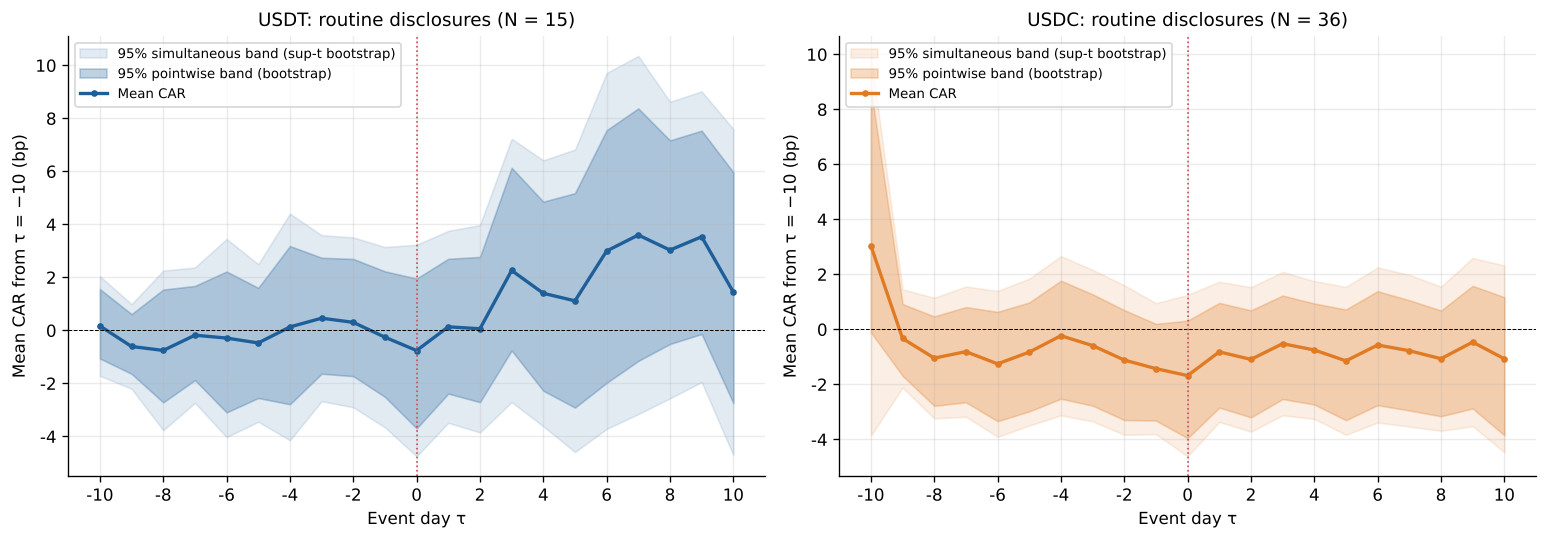

In [37]:
# V10. Extended rule-based sample (base_extended) — all numbers reported in manuscript v10
# Reproduces every number reported in manuscript v10 (Tables 4-9, Figure 2).
# Needs events_v10_base.csv (rule-based event sample) next to the notebook or in stablecoin_research/.
OUT = os.path.join(REV, 'v10'); os.makedirs(OUT, exist_ok=True)
_ev = _have('events_v10_base.csv')
if _ev is None:
    raise FileNotFoundError('events_v10_base.csv not found: place it next to the notebook')
EV = pd.read_csv(_ev, parse_dates=['event_date'])
parts = {}
for coin, ret in [('USDT', 'r_usdt'), ('USDC', 'r_usdc')]:
    cdf, _ = compute_car(master, EV, coin, ret); parts[coin] = cdf
car_usdt, car_usdc = parts['USDT'], parts['USDC']
el = pd.concat([make_event_level(parts['USDT']), make_event_level(parts['USDC'])], ignore_index=True)
el = el.merge(EV[['coin', 'event_date', 'category', 'new', 'routine', 'is_report']], on=['coin', 'event_date'])
el['negative'] = (el['routine'] == 0).astype(int); el['is_usdc'] = (el['coin'] == 'USDC').astype(int)
for w in ['CAR_-1_1', 'CAR_-3_3', 'CAR_-5_5', 'CAR_-10_10']:
    el[w + '_bp'] = el[w] * 1e4
ev_all = el.copy()
print('N by coin/routine:', el.groupby(['coin', 'routine']).size().to_dict())
RES = {}
WINS4 = ['CAR_-1_1', 'CAR_-3_3', 'CAR_-5_5', 'CAR_-10_10']

# --- H1
rows = []
for coin in ['USDT', 'USDC']:
    for samp, m in [('routine', el['routine'] == 1), ('pooled', el['routine'] >= 0)]:
        d = el[(el['coin'] == coin) & m]
        for w in WINS4:
            x = d[w + '_bp'].values; n = len(x); sd = x.std(ddof=1); se = sd / np.sqrt(n); c = tdist.ppf(.975, n - 1)
            rows.append(dict(coin=coin, sample=samp, window=w, N=n, mean=x.mean(), median=np.median(x), sd=sd,
                             t=x.mean() / se, p=ttest_1samp(x, 0).pvalue, p_wil=wilcoxon(x).pvalue,
                             ci_lo=x.mean() - c * se, ci_hi=x.mean() + c * se,
                             mde80=mde_t(sd, n, .8), mde90=mde_t(sd, n, .9), tost5=tost(x, 5), tost10=tost(x, 10),
                             ci90_lo=x.mean() - tdist.ppf(.95, n - 1) * se, ci90_hi=x.mean() + tdist.ppf(.95, n - 1) * se))
H1 = pd.DataFrame(rows); H1.to_csv(f'{OUT}/T_H1.csv', index=False)
print(H1.round(3).to_string(index=False))

# --- Peg stability and supply (local placebo)
for k in ['usdt', 'usdc']:
    master[f'sdev_{k}'] = master[f'p_{k}'] - 1.0
pm = []
PL = {c: placebo_dates(c) for c in ['USDT', 'USDC']}
for _, e in el.iterrows():
    t0 = t0_of(e['event_date']); r = dict(coin=e['coin'], event_date=e['event_date'])
    for tag, (lo, hi) in {'m55': (-5, 5), 'm05': (0, 5), 'm11': (-1, 1)}.items():
        v = peg_metrics(e['coin'], t0, lo, hi)['maxabs_rel_bp']
        loc = [peg_metrics(e['coin'], i, lo, hi)['maxabs_rel_bp'] for i in PL[e['coin']][::2] if abs(i - t0) <= LOCAL]
        r[f'peg_{tag}'] = v; r[f'pctL_peg_{tag}'] = pctile(loc, v)
    pmx = peg_metrics(e['coin'], t0, -5, 5); r['recovery_days'] = pmx['recovery_days']
    col = f"lsc_{e['coin'].lower()}"; s_ = master[col]
    for tag, (lo, hi) in {'s11': (-1, 1), 's05': (0, 5), 's010': (0, 10)}.items():
        v = (s_.iloc[t0 + hi] - s_.iloc[t0 + lo - 1]) * 1e4
        pl = np.array([(s_.iloc[i + hi] - s_.iloc[i + lo - 1]) * 1e4 for i in PL[e['coin']]]); pl = pl[np.isfinite(pl)]
        r[tag] = v; r[f'pct_{tag}'] = pctile(pl, v)
        loc = [(s_.iloc[i + hi] - s_.iloc[i + lo - 1]) * 1e4 for i in PL[e['coin']] if abs(i - t0) <= LOCAL]
        r[f'pctL_{tag}'] = pctile(loc, v)
    pm.append(r)
PM = pd.DataFrame(pm); el = el.merge(PM, on=['coin', 'event_date'])
rows = []
for coin in ['USDT', 'USDC']:
    d = el[(el['coin'] == coin) & (el['routine'] == 1)]
    for mcol in ['pctL_peg_m11', 'pctL_peg_m55', 'pctL_peg_m05', 'pctL_s11', 'pctL_s05', 'pctL_s010', 'pct_s010']:
        x = d[mcol] - 50
        rows.append(dict(coin=coin, metric=mcol, N=len(d), median_pct=d[mcol].median(), mean_pct=d[mcol].mean(),
                         p_wil=wilcoxon(x).pvalue, share_above90=(d[mcol] > 90).mean()))
PEGT = pd.DataFrame(rows); PEGT.to_csv(f'{OUT}/T_peg_supply.csv', index=False)
print(PEGT.round(3).to_string(index=False))

# --- Stress events individually
PLC = {}
for coin in ['USDT', 'USDC']:
    rr = []
    for i in PL[coin][::3]:
        r = {}
        for w, (lo, hi) in {'CAR_-1_1': (-1, 1), 'CAR_-3_3': (-3, 3), 'CAR_-5_5': (-5, 5)}.items():
            r[w] = car_at(coin, i, lo, hi)[0]
        rr.append(r)
    PLC[coin] = pd.DataFrame(rr).dropna()
rows = []
for _, e in el[el['routine'] == 0].iterrows():
    r = dict(coin=e['coin'], event_date=e['event_date'].date(), desc=e['description'][:40])
    for w in ['CAR_-1_1', 'CAR_-3_3', 'CAR_-5_5']:
        r[w] = e[w] * 1e4; r['pctP_' + w] = pctile(PLC[e['coin']][w], e[w])
    for c_ in ['peg_m55', 'pctL_peg_m55', 'recovery_days', 's11', 'pct_s11', 's010', 'pct_s010']:
        r[c_] = e[c_]
    rows.append(r)
ST = pd.DataFrame(rows); ST.to_csv(f'{OUT}/T_stress.csv', index=False)
print(ST.round(2).to_string(index=False))

# --- H2 (exploratory), reports only
rep = el[el['is_report'] == 1].dropna(subset=['quality_score']).sort_values(['coin', 'event_date']).copy()
rep['dQ'] = rep.groupby('coin')['quality_score'].diff().fillna(0); rep['Q5'] = (rep['quality_score'] == 5).astype(int)
rows = []
rows += h2_fit(rep, 'CAR_-5_5_bp', ['quality_score', 'is_usdc'], 'ext: reports, Q')
rows += h2_fit(rep, 'CAR_-3_3_bp', ['quality_score', 'is_usdc'], 'ext: reports, Q, CAR33')
rows += h2_fit(rep, 'CAR_-5_5_bp', ['dQ', 'is_usdc'], 'ext: reports, dQ')
rows += h2_fit(rep, 'peg_m55', ['quality_score', 'is_usdc'], 'ext: reports, Q, y=peg')
rows += h2_fit(rep[rep['coin'] == 'USDC'], 'CAR_-5_5_bp', ['quality_score'], 'ext: USDC reports')
rows += h2_fit(rep[rep['coin'] == 'USDT'], 'CAR_-5_5_bp', ['quality_score'], 'ext: USDT reports')
H2X = pd.DataFrame(rows); H2X.to_csv(f'{OUT}/T_H2.csv', index=False)
print('Q dist', rep.groupby('coin')['quality_score'].value_counts().to_dict())
print(H2X[H2X['var'] != 'const'].round(3).to_string(index=False))

# --- Volume
rows = []
for _, ev in el.iterrows():
    base = dict(coin=ev['coin'], event_date=ev['event_date'], routine=ev['routine'], holiday_window=holiday(ev['event_date']))
    for tag, kw in [('v9', dict(clean=False)), ('clean', dict(clean=True)), ('clean_btcadj', dict(clean=True, adj=True))]:
        base.update({f'{k}_{tag}': v for k, v in av_row(ev, **kw).items()})
    rows.append(base)
AV = pd.DataFrame(rows); el = el.merge(AV.drop(columns=['routine']), on=['coin', 'event_date'])
rows = []
for coin in ['USDT', 'USDC']:
    for samp, m in [('routine', el['routine'] == 1), ('routine excl. holiday', (el['routine'] == 1) & (el['holiday_window'] == 0))]:
        d = el[(el['coin'] == coin) & m]
        for tg in ['v9', 'clean', 'clean_btcadj']:
            for w in ['AV_-1_1', 'AV_-5_5']:
                x = d[f'{w}_{tg}']; rows.append(dict(coin=coin, sample=samp, version=tg, window=w, N=len(x), mean=x.mean(), p=ttest_1samp(x, 0).pvalue))
AVS = pd.DataFrame(rows); AVS.to_csv(f'{OUT}/T_volume.csv', index=False)
print(AVS.round(3).to_string(index=False))

# --- Alternative benchmarks
other = {'USDT': 'r_usdc', 'USDC': 'r_usdt'}
rows = []
for _, ev in el[el['routine'] == 1].iterrows():
    t0 = t0_of(ev['event_date']); c = ev['coin']
    rows.append(dict(coin=c, btc=ev['CAR_-5_5_bp'], cross=car_generic(c, t0, [other[c]]),
                     btc_cross=car_generic(c, t0, ['r_btc', other[c]]), const=car_generic(c, t0, [])))
ALT = pd.DataFrame(rows)
rows = []
for coin in ['USDT', 'USDC']:
    d = ALT[ALT['coin'] == coin]
    for m in ['btc', 'cross', 'btc_cross', 'const']:
        rows.append(dict(coin=coin, model=m, N=len(d), mean=d[m].mean(), p=ttest_1samp(d[m], 0).pvalue, tost5=tost(d[m].values, 5), tost10=tost(d[m].values, 10)))
ALTS = pd.DataFrame(rows); ALTS.to_csv(f'{OUT}/T_alt.csv', index=False); print(ALTS.round(3).to_string(index=False))

# --- Contamination (market news within ±5 calendar days)
el['n_news'] = [int(((MARKET_NEWS['date'] - d).dt.days.between(-5, 5)).sum()) for d in el['event_date']]
rows = []
for coin in ['USDT', 'USDC']:
    for samp, m in [('all', el['n_news'] >= 0), ('clean', el['n_news'] == 0)]:
        d = el[(el['coin'] == coin) & (el['routine'] == 1) & m]; x = d['CAR_-5_5_bp'].values
        rows.append(dict(coin=coin, sample=samp, N=len(x), mean=x.mean(), p=ttest_1samp(x, 0).pvalue, tost5=tost(x, 5), tost10=tost(x, 10),
                         peg_med=d['pctL_peg_m05'].median(), peg_p=wilcoxon(d['pctL_peg_m05'] - 50).pvalue))
CON = pd.DataFrame(rows); CON.to_csv(f'{OUT}/T_contam.csv', index=False); print(CON.round(3).to_string(index=False))

# --- Excluding Grant-Thornton-era duplicates / only Deloitte etc.: USDC subperiods
rows = []
for lab, m in [('USDC routine, before 2022-11', el['event_date'] < '2022-11-01'), ('USDC routine, from 2022-11', el['event_date'] >= '2022-11-01')]:
    d = el[(el['coin'] == 'USDC') & (el['routine'] == 1) & m]; x = d['CAR_-5_5_bp'].values
    rows.append(dict(sample=lab, N=len(x), mean=x.mean(), p=ttest_1samp(x, 0).pvalue, tost5=tost(x, 5)))
print(pd.DataFrame(rows).round(3).to_string(index=False))

# --- Figure 2 (extended)
B_PATH = 5000; rngf = np.random.default_rng(R_SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); band_rows = []
for ax, (coin, color) in zip(axes, [('USDT', '#1f5f99'), ('USDC', '#e07b24')]):
    d = el[(el['coin'] == coin) & (el['routine'] == 1)]
    P = np.vstack([path(coin, dt).reindex(range(-10, 11)).fillna(0).cumsum().values for dt in d['event_date']]) * 1e4
    n = P.shape[0]; mean = P.mean(0); se = P.std(0, ddof=1) / np.sqrt(n); ct = tdist.ppf(0.975, n - 1)
    idx = rngf.integers(0, n, size=(B_PATH, n)); BM = P[idx].mean(1)
    lo_pw, hi_pw = np.percentile(BM, [2.5, 97.5], axis=0); bsd = BM.std(0, ddof=1); bsd[bsd == 0] = np.nan
    c_sim = np.quantile(np.nanmax(np.abs((BM - mean) / bsd), axis=1), 0.95)
    ax.fill_between(range(-10, 11), mean - c_sim * bsd, mean + c_sim * bsd, color=color, alpha=0.12, label='95% simultaneous band (sup-t bootstrap)')
    ax.fill_between(range(-10, 11), lo_pw, hi_pw, color=color, alpha=0.28, label='95% pointwise band (bootstrap)')
    ax.plot(range(-10, 11), mean, color=color, lw=2, marker='o', ms=3, label='Mean CAR')
    ax.axhline(0, color='black', lw=0.6, ls='--'); ax.axvline(0, color='#d1495b', lw=1, ls=':')
    ax.set_title(f'{coin}: routine disclosures (N = {n})', fontsize=11)
    ax.set_xlabel('Event day τ'); ax.set_ylabel('Mean CAR from τ = −10 (bp)'); ax.set_xticks(range(-10, 11, 2))
    ax.grid(alpha=0.25); ax.legend(fontsize=8, loc='upper left')
    band_rows.append(dict(coin=coin, N=n, c_sim=c_sim, max_abs_mean=np.abs(mean).max(), sim_lo_min=(mean - c_sim * bsd).min(), sim_hi_max=(mean + c_sim * bsd).max()))
plt.tight_layout(); plt.savefig(f'{OUT}/Figure2_v10.png', dpi=300, bbox_inches='tight')
print(pd.DataFrame(band_rows).round(2).to_string(index=False))

# --- Event-level appendix
cols = ['coin', 'event_date', 'event_type', 'category', 'routine', 'is_report', 'quality_score', 'description',
        'CAR_-1_1_bp', 'CAR_-3_3_bp', 'CAR_-5_5_bp', 'CAR_-10_10_bp', 'peg_m55', 'pctL_peg_m55', 's010', 'pct_s010', 'AV_-1_1_clean_btcadj', 'n_news']
el[cols].sort_values(['coin', 'event_date']).to_csv(f'{OUT}/T_event_level.csv', index=False)
print('done')

In [38]:
# V10b. Additional analyses for Reviewer 2
# (a) further peg metrics, routine events, local percentiles
rows = []
for _, e in el[el['routine'] == 1].iterrows():
    t0 = t0_of(e['event_date']); r = dict(coin=e['coin'], event_date=e['event_date'])
    for tag, (lo, hi) in {'m55': (-5, 5), 'm05': (0, 5)}.items():
        v = peg_metrics(e['coin'], t0, lo, hi)
        loc = [peg_metrics(e['coin'], i, lo, hi) for i in PL[e['coin']][::2] if abs(i - t0) <= LOCAL]
        for m in ['maxabs_dev_bp', 'min_rel_bp', 'days_off_10bp', 'sum_abs_ret_bp']:
            r[f'{m}_{tag}'] = v[m]; r[f'pctL_{m}_{tag}'] = pctile([x[m] for x in loc], v[m])
    rows.append(r)
PX = pd.DataFrame(rows); out = []
for coin in ['USDT', 'USDC']:
    d = PX[PX['coin'] == coin]
    for c in [c for c in PX.columns if c.startswith('pctL_')]:
        x = d[c] - 50
        out.append(dict(coin=coin, metric=c, N=len(d), median=d[c].median(), p=wilcoxon(x).pvalue if (x != 0).any() else np.nan))
PXS = pd.DataFrame(out); PXS.to_csv(f'{OUT}/T_peg_extra.csv', index=False); print(PXS.round(3).to_string(index=False))

# (b) reporting lag and assurance type (reports)
asof = {('USDT','2021-05-13'):'2021-03-31',('USDT','2021-08-09'):'2021-06-30',('USDT','2021-12-03'):'2021-09-30',('USDT','2022-02-21'):'2021-12-31',
        ('USDT','2022-08-19'):'2022-06-30',('USDT','2023-02-09'):'2022-12-31',('USDT','2023-05-10'):'2023-03-31',('USDT','2023-07-31'):'2023-06-30',
        ('USDT','2023-10-31'):'2023-09-30',('USDT','2024-01-31'):'2023-12-31',('USDT','2024-05-01'):'2024-03-31',('USDT','2024-07-31'):'2024-06-30',
        ('USDT','2024-10-31'):'2024-09-30',('USDT','2025-01-31'):'2024-12-31',('USDC','2021-07-20'):'2021-05-28',('USDC','2022-12-23'):'2022-11-30'}
circ = pd.read_csv(_have('circle_attestation_dates_v10.csv'))
for a, s_ in zip(circ['as_of'], circ['sign_date']):
    asof.setdefault(('USDC', s_), a)
rep = el[el['is_report'] == 1].copy()
rep['lag'] = [(d - pd.Timestamp(asof[(c, d.strftime('%Y-%m-%d'))])).days for c, d in zip(rep['coin'], rep['event_date'])]
rep['examination'] = ((rep['coin'] == 'USDC') & (rep['event_date'] >= '2023-03-01')).astype(int)
print('lag summary', rep.groupby('coin')['lag'].describe().round(1).to_string())
rows = []
rows += h2_fit(rep, 'CAR_-5_5_bp', ['lag', 'is_usdc'], 'reports, reporting lag')
rows += h2_fit(rep, 'peg_m55', ['lag', 'is_usdc'], 'reports, reporting lag, y=peg')
rows += h2_fit(rep[rep['coin'] == 'USDC'], 'CAR_-5_5_bp', ['examination'], 'USDC reports, Deloitte examination')
rows += h2_fit(rep[rep['coin'] == 'USDC'], 'peg_m55', ['examination'], 'USDC reports, Deloitte examination, y=peg')
LAG = pd.DataFrame(rows); LAG.to_csv(f'{OUT}/T_lag_assurance.csv', index=False)
print(LAG[LAG['var'] != 'const'][['spec', 'var', 'coef', 'p_HC1_t_df', 'p_wild', 'N', 'max_leverage']].round(3).to_string(index=False))

# (c) labels of the submitted version (the manuscript uses the recoded labels in V10c)
rows = []
for coin in ['USDT', 'USDC']:
    for lab in ['positive', 'neutral']:
        d = el[(el['coin'] == coin) & (el['routine'] == 1) & (el['event_type'] == lab)]
        for y in ['CAR_-5_5_bp', 'peg_m55']:
            x = d[y].values
            rows.append(dict(coin=coin, label=lab, y=y, N=len(x), mean=x.mean(), p=ttest_1samp(x, 0).pvalue if len(x) > 1 else np.nan))
    a = el[(el['coin'] == coin) & (el['routine'] == 1) & (el['event_type'] == 'positive')]['CAR_-5_5_bp']
    b = el[(el['coin'] == coin) & (el['routine'] == 1) & (el['event_type'] == 'neutral')]['CAR_-5_5_bp']
    rows.append(dict(coin=coin, label='diff Welch', y='CAR_-5_5_bp', N=len(a) + len(b), mean=a.mean() - b.mean(), p=ttest_ind(a, b, equal_var=False).pvalue))
LAB = pd.DataFrame(rows); LAB.to_csv(f'{OUT}/T_label_split.csv', index=False); print(LAB.round(3).to_string(index=False))

# (d) SVB: alternative event dates and short windows (USDC)
t_svb = t0_of(pd.Timestamp('2023-03-10')); rows = []
for lab, t0 in [('10 Mar (bank closure)', t_svb), ('11 Mar (Circle disclosure)', t_svb + 1), ('12 Mar (joint statement)', t_svb + 2)]:
    for (lo, hi) in [(0, 0), (0, 1), (-1, 1), (0, 2)]:
        c, s = car_at('USDC', t0, lo, hi); rows.append(dict(date=lab, window=f'({lo},{hi})', CAR_bp=c * 1e4))
SVB = pd.DataFrame(rows); SVB.to_csv(f'{OUT}/T_svb_dates.csv', index=False); print(SVB.round(1).to_string(index=False))

coin                  metric  N  median     p
USDT  pctL_maxabs_dev_bp_m55 15  78.378 0.191
USDT     pctL_min_rel_bp_m55 15  47.429 0.762
USDT  pctL_days_off_10bp_m55 15  40.057 0.489
USDT pctL_sum_abs_ret_bp_m55 15  61.932 0.762
USDT  pctL_maxabs_dev_bp_m05 15  85.946 0.135
USDT     pctL_min_rel_bp_m05 15  36.571 0.460
USDT  pctL_days_off_10bp_m05 15  43.750 0.421
USDT pctL_sum_abs_ret_bp_m05 15  58.824 0.359
USDC  pctL_maxabs_dev_bp_m55 36  39.737 0.024
USDC     pctL_min_rel_bp_m55 36  56.902 0.470
USDC  pctL_days_off_10bp_m55 36  48.707 0.004
USDC pctL_sum_abs_ret_bp_m55 36  42.439 0.203
USDC  pctL_maxabs_dev_bp_m05 36  35.281 0.016
USDC     pctL_min_rel_bp_m05 36  54.874 0.494
USDC  pctL_days_off_10bp_m05 36  50.000 0.023
USDC pctL_sum_abs_ret_bp_m05 36  36.355 0.114
lag summary       count  mean   std   min   25%   50%   75%   max
coin                                                 
USDC   35.0  30.4   8.8  20.0  25.5  29.0  31.0  58.0
USDT   14.0  39.0  10.3  31.0  31.0  35.5  4

                                     spec         var   coef  p_HC1_t_df  p_wild  N  max_leverage
                   reports, reporting lag         lag -0.248       0.025   0.021 49         0.226
                   reports, reporting lag     is_usdc -3.521       0.197   0.214 49         0.226
            reports, reporting lag, y=peg         lag -0.063       0.323   0.326 49         0.226
            reports, reporting lag, y=peg     is_usdc -6.786       0.000   0.000 49         0.226
       USDC reports, Deloitte examination examination -0.292       0.788   0.792 35         0.071
USDC reports, Deloitte examination, y=peg examination -4.273       0.001   0.000 35         0.071
coin      label           y  N   mean     p
USDT   positive CAR_-5_5_bp 12  1.496 0.518
USDT   positive     peg_m55 12  9.300 0.000
USDT    neutral CAR_-5_5_bp  3  1.037 0.927
USDT    neutral     peg_m55  3 10.168 0.032
USDT diff Welch CAR_-5_5_bp 15  0.459 0.968
USDC   positive CAR_-5_5_bp  3 -0.858 0.604
USDC  

In [39]:
# V10c. Reviewer 4: standardized CARs of stress events; consistent positive/neutral rule
rows = []
for _, e in el[el['routine'] == 0].iterrows():
    t0 = t0_of(e['event_date']); rt = el[(el['coin'] == e['coin']) & (el['routine'] == 1)]
    r = dict(coin=e['coin'], event_date=e['event_date'].date())
    for w, (lo, hi) in {'CAR_-1_1': (-1, 1), 'CAR_-3_3': (-3, 3), 'CAR_-5_5': (-5, 5)}.items():
        c, s = car_at(e['coin'], t0, lo, hi); r['SCAR' + w[3:]] = s; r['pctR' + w[3:]] = pctile(rt[w], c)
    rows.append(r)
print(pd.DataFrame(rows).round(2).to_string(index=False))
POS = {('USDT','2021-05-13'),('USDT','2021-08-09'),('USDT','2022-02-21'),('USDT','2022-08-19'),('USDT','2022-10-13'),('USDT','2023-02-09'),('USDT','2024-05-01'),
       ('USDC','2021-07-20'),('USDC','2022-08-24'),('USDC','2022-12-23'),('USDC','2023-01-17')}
el['label2'] = ['positive' if (c, d.strftime('%Y-%m-%d')) in POS else 'neutral' for c, d in zip(el['coin'], el['event_date'])]
rows = []
for coin in ['USDT', 'USDC']:
    d = el[(el['coin'] == coin) & (el['routine'] == 1)]
    a = d[d['label2'] == 'positive']['CAR_-5_5_bp']; b = d[d['label2'] == 'neutral']['CAR_-5_5_bp']
    rows.append(dict(coin=coin, Npos=len(a), mean_pos=a.mean(), Nneu=len(b), mean_neu=b.mean(), p_welch=ttest_ind(a, b, equal_var=False).pvalue,
                     p_mw=mannwhitneyu(a, b).pvalue))
print(pd.DataFrame(rows).round(3).to_string(index=False))
el[['coin','event_date','label2']].to_csv(f'{OUT}/labels_v10.csv', index=False)

coin event_date  SCAR_-1_1  pctR_-1_1  SCAR_-3_3  pctR_-3_3  SCAR_-5_5  pctR_-5_5
USDT 2021-10-15      -0.02      53.33      -0.21       6.67      -0.00      46.67
USDT 2022-05-12      -2.12       0.00      -0.75       6.67      -0.86       6.67
USDT 2022-11-11      -0.29      33.33      -0.72       6.67      -0.33      26.67
USDT 2023-03-10      29.78     100.00       9.41     100.00       7.39     100.00
USDC 2022-05-12       0.48      83.33       0.01      61.11      -0.00      61.11
USDC 2022-11-11      -0.37      13.89       0.54      97.22       0.45      88.89
USDC 2023-03-10    -113.01       0.00      -2.63       2.78       0.24      69.44
coin  Npos  mean_pos  Nneu  mean_neu  p_welch  p_mw
USDT     7     2.092     8     0.803    0.795 0.779
USDC     4    -0.334    32     0.163    0.708 0.981


In [40]:
# V10d. Reporting lag with year effects (Section 4.4) and the label comparison used in the manuscript (labels as recoded in v10)
import statsmodels.formula.api as smf
rep['year'] = rep['event_date'].dt.year.astype(str)
f_ye = smf.ols('Q("CAR_-5_5_bp") ~ lag + is_usdc + C(year)', data=rep).fit(cov_type='HC1')
print('lag with year effects: coef %.3f, p = %.3f' % (f_ye.params['lag'], f_ye.pvalues['lag']))
f_ex = smf.ols('Q("CAR_-5_5_bp") ~ lag + is_usdc', data=rep[rep['lag'] < 55]).fit(cov_type='HC1')
print('lag excluding the two longest delays: coef %.3f, p = %.3f' % (f_ex.params['lag'], f_ex.pvalues['lag']))
print('Note: the label comparison reported in Section 4.4 uses label2 (cell V10c); cell V10b shows the labels of the submitted version.')

lag with year effects: coef -0.280, p = 0.010
lag excluding the two longest delays: coef -0.158, p = 0.057
Note: the label comparison reported in Section 4.4 uses label2 (cell V10c); cell V10b shows the labels of the submitted version.
